# beira. en datos

**Proyecto final · Case Study 2 (Data Analytics) · Ironhack Data Analytics · João Miguel Pais**

## El problema

La PAISAN Confecções es la fábrica de mi familia, en Oliveira do Hospital. Hace ropa para otras marcas y vive de muy pocos clientes: en 2025 los tres mayores se llevaron el 93 % de lo que facturó. Si uno de ellos se va, se va con él buena parte del año.

La **beira.** es la marca que montamos para que la fábrica tenga clientes propios: ropa personalizada para equipos, para el trabajo y para eventos. Todavía está arrancando, así que no tiene historia propia que analizar. Por eso miro fuera: qué compran las entidades públicas de la región, quién vuelve a comprar, cómo y cuándo compran, y qué cabe en la fábrica.

> **La pregunta de negocio:** ¿a quién debe dirigirse la beira. para traer clientes propios a la PAISAN, cómo y cuándo llegar a ellos, y cuánto trabajo nuevo cabe en la fábrica?

## Las hipótesis

| | Hipótesis | Datos | Prueba |
|---|---|---|---|
| H1 | Quien compra ropa un año vuelve a comprar al año siguiente | contratos públicos (Portal BASE) | chi-cuadrado y V de Cramér |
| H2 | Las prendas de equipo se compran sobre todo de mayo a septiembre | contratos públicos | chi-cuadrado y V de Cramér |
| H3 | Clubes y asociaciones publican menos contacto que las escuelas | organizaciones (OpenStreetMap) | chi-cuadrado y V de Cramér |
| H4 | La PAISAN depende de pocos clientes (los tres mayores pasan del 80 %) | facturas de la PAISAN | t de una muestra |
| H5 | Los clientes de la PAISAN que compran un año vuelven al siguiente | facturas de la PAISAN | chi-cuadrado y V de Cramér |
| H6 | La factura mediana de la PAISAN subió menos que el salario mínimo | facturas y salario mínimo | t de Welch sobre el logaritmo |

Además de las hipótesis, el notebook responde a las preguntas que necesito para actuar: quién compra, qué y por cuánto, por qué procedimiento, frente a qué competencia, en qué mes, y cuánto tendría que vender la beira. para que la PAISAN dependa menos de sus tres clientes.

## Lo que sale, en una tabla

| | Resultado |
|---|---|
| H1 | se cumple: vuelve a comprar el 62 % de quien compró, frente al 29 % de quien no (V = 0,32), todos los años y también en la región |
| H2 | se cumple, con efecto pequeño: 58 % de las prendas de equipo de mayo a septiembre, frente al 43 % del resto (V = 0,08) |
| H3 | se cumple: 18 % de clubes y asociaciones con contacto público, frente al 85 % de las escuelas (V = 0,56) |
| H4 | se cumple: los tres mayores clientes suman de media el 86,6 % de cada año (p = 0,001); en 2025, el 93 % |
| H5 | se cumple: 67 % frente a 4 % (V = 0,67) |
| H6 | se cumple: la factura mediana sube un 65 % y el salario mínimo un 79 % |
| La lista | 63 entidades públicas de la región compran ropa en dos años o más; 34 son fieles |
| Cómo | ajuste directo en el 48 % de los contratos de la región; el 77 % de los contratos es de menos de 20.000 € |
| Frente a quién | nadie domina: el 59 % de las compras repetidas va a un proveedor nuevo |
| Cuándo | escuelas en abril y mayo y de octubre a diciembre; fiestas de junio a septiembre |
| Cuánto cabe | unos 194.000 € más al año, si todos los meses llegaran al mejor mes |
| Cuánto hace falta | unos 83.000 € al año de la beira. para que los tres mayores bajen al 80 %: unas 980 piezas al mes al precio típico del mercado |
| Cuándo cabe | la fábrica tiene más sitio en junio y julio, cuando se produce para las fiestas (el 71 %, de mayo a agosto) |

## Cómo está hecho este notebook

1. Preparación · 2. Los datos · 3. Limpieza de los contratos · 4. El mercado público (H1, H2, H3) · 5. A quién dirigirse: la lista · 6. Cómo y cuándo llegar · 7. La PAISAN (H4, H5, H6, capacidad y modelo) · 8. Tablas para la base de datos, Tableau y la app · 9. La base de datos en MySQL y las consultas SQL · 10. El dashboard y la app · 11. Conclusiones

Cada paso tiene la misma forma: antes del código explico por qué lo hago y por qué con ese código y no con otro; después, qué saco del resultado y qué me llevo para los datos y para la presentación. Cada función la defino en el notebook justo antes de usarla, para que se vea qué hace; las mismas funciones están también en `src/funciones.py` (y las de la base de datos en `src/base_datos.py`) para poder reutilizarlas fuera del notebook. Los valores fijos (carpetas, colores, umbrales y palabras de las reglas) están en `src/config.py`. Al final de cada sección hay un resumen en portugués.

**Regla fija:** la Junta de Freguesia de Alvoco das Várzeas queda fuera de todas las tablas, por conflicto de intereses.

> **Resumo (português).** A PAISAN, a fábrica da minha família, depende de três clientes (93 % da facturação em 2025). A beira. nasce para lhe trazer clientes próprios. Este notebook responde a quem a beira. se deve dirigir, como e quando chegar a essas entidades e quanto trabalho novo cabe na fábrica, com seis hipóteses (H1 a H6), uma base de dados em MySQL, um painel de Tableau e uma app em Streamlit.

## Qué uso de cada semana del curso

Todo el código sale de las clases y de los labs. Debajo de cada «Por qué este código» está, en pequeño, lo que usa esa celda y en qué semana se dio.

| Semana | Lo que se usa en este notebook |
|---|---|
| Semana 1 · Python | `import`, `def` y `return`, `for`, `if` / `else`, comprensión de listas y diccionarios, `lambda`, `try` / `except`, `items` y `get`, `lower`, `replace`, `split`, `join`, `strip`, `startswith`, `endswith`, `len`, `range`, `round`..., `sys.path` y módulo propio |
| Semana 2 · pandas, fechas y gráficos básicos | `pd.read_csv`, `head`, `tail`, `info`, `describe`, `shape`, `loc` / `iloc`, filtro con una condición, `unique` / `nunique`, `value_counts`, `sort_values` / `sort_index`, `pd.concat`, `pd.DataFrame` / `pd.Series`, `isna` / `duplicated`, `dropna` / `fillna`, `drop_duplicates`, `drop`, `rename`, `astype`, `apply`, `map`, `isin`, `.str`, `copy`, `reset_index`, `.columns =`, `merge`, `pivot_table`, `melt`, `groupby`, `agg`, `size`, `sum`, `mean`, `median`..., `pd.to_datetime` y `.dt.year`, `sns.histplot`, `sns.boxplot`, `sns.scatterplot`, `sns.heatmap` |
| Semana 4 · SQL y datos relacionales | `pathlib.Path` y `mkdir`, `to_csv`, `getpass`, `mysql.connector` (`connect`, `cursor`, `execute`, `fetchall`), `ejecutar_script` (función propia, `src/base_datos.py`), `cargar_tabla` (función propia): `executemany` y `commit`, `conectar` (función propia): `create_engine` de SQLAlchemy, `connection.execute` con `text`, `consultar` (función propia): `pd.read_sql` con `text`, `SELECT`, `FROM`, `WHERE`, `ORDER BY`, `JOIN` / `LEFT JOIN`, `GROUP BY` con `COUNT`, `SUM`, `AVG`, `CASE WHEN`, subconsulta, `WITH` (CTE), funciones de ventana (`OVER`, `PARTITION BY`), `ROW_NUMBER` y `RANK`, `LAG` y `LEAD`, `IFNULL`, `CREATE TEMPORARY TABLE`, `CROSS JOIN`, `CREATE VIEW`, `glob.glob`, `to_csv` |
| Semana 5 · EDA, estadística y pruebas de hipótesis | `plt.subplots`, `plt.xlabel`, `plt.show`..., `pd.crosstab`, `quantile` / `skew`, `sns.barplot`, `sns.lineplot`, `chi2_contingency`, `association`, `corrwith`, `stats.shapiro`, `stats.pearsonr`, `np.log1p`, `stats.ttest_1samp` (`alternative`), `stats.ttest_ind` (`equal_var=False`), `stats.f_oneway`, `np.sqrt` |
| Semana 7 · Machine Learning | `MinMaxScaler` (`fit` y `transform`), `np.abs`, `np.zeros_like`, `np.triu_indices_from`, `KNeighborsRegressor`, `LinearRegression`, `DecisionTree`, `RandomForest`, `GradientBoosting`, `fit` y `predict`, `feature_importances_`, `mean_absolute_error`, `mean_squared_error`, `r2_score` |

Las funciones propias (`leer`, `revisar`, `normalizar`, `filas_del_ano`, `cargar_tabla`...) se definen en el notebook y están también en `src/funciones.py` y `src/base_datos.py`; importar de un archivo `.py` con `sys.path` (como `config.py` y `base_datos.py`) es de la lección de módulos.

# 1. Preparación

**Por qué lo hago.** Quiero que el notebook se pueda ejecutar de arriba abajo sin tocar nada, así que cargo al principio todo lo que voy a usar.

**Por qué este código.** Las librerías son las de clase: pandas y numpy para las tablas, matplotlib y seaborn para los gráficos, scipy para las pruebas y scikit-learn para el único modelo que queda, el de la facturación. Los valores fijos no los escribo aquí: los importo de `src/config.py`, como en la lección de módulos. Así, si cambio una carpeta o un umbral, lo cambio en un solo sitio.

<sub>Lo que uso: `import` (semana 1), `sys.path` y módulo propio (semana 1).</sub>

In [1]:
import glob
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from scipy.stats.contingency import association
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import MinMaxScaler
from sklearn.tree import DecisionTreeRegressor

sys.path.append("../src")
from config import (ACENTOS, ANOS_INCOMPLETOS, CARPETA_SQL, CARPETA_SQL_INTERNA, CARPETA_TABLEAU, COLORES, DATOS, FARDAMENTO,
                    INTERNO, JUNTA_EXCLUIDA, KM_CERCA, MESES_INCOMPLETOS, NO_ES_ROPA, OBJETIVO_TRES_MAYORES, PRENDAS_EQUIPO,
                    PROTECCION, RESULTADOS, ROPA, SEMILLA, SIGNOS)

print("listo | carpeta de datos públicos:", "../data/clean/", "| colores de la marca:", list(COLORES))

listo | carpeta de datos públicos: ../data/clean/ | colores de la marca: ['verde_serra', 'terracota', 'ambar', 'gris']


**Qué saco.** Todo carga sin errores.

**Para los datos y la presentación.** Nada para la presentación. Para el repositorio es importante: valores en un archivo de configuración y funciones también en `.py` es lo que pide la rúbrica.

**Por qué lo hago.** Hay tres cosas que voy a repetir con cada tabla: leerla con las columnas en minúsculas, revisarla y quitar la Junta excluida. Las escribo una vez como funciones.

**Por qué este código.** Con `def` y `return` (semana 1). `leer` junta la carpeta de `config.py` con el nombre del archivo y pasa las columnas a minúsculas con `.str.lower()`. `revisar` es la revisión de la semana 2 entera: tamaño, duplicados, `info`, nulos, primeras y últimas filas y `describe`. `sin_junta_excluida` busca el nombre en minúsculas y sin acentos para que la encuentre aunque esté escrita de otra forma. Las tres están también en `src/funciones.py`.

<sub>Lo que uso: `def` y `return` (semana 1), `lower`, `replace`, `split`, `join`, `strip`, `startswith`, `endswith` (semana 1), `lambda` (semana 1), `pd.read_csv` (semana 2), `.columns =` (semana 2), `.str` (semana 2), `shape` (semana 2), `isna` / `duplicated` (semana 2), `agg`, `size`, `sum`, `mean`, `median`... (semana 2), `info` (semana 2), `head` (semana 2), `tail` (semana 2), `describe` (semana 2), `dropna` / `fillna` (semana 2), `apply` (semana 2).</sub>

In [2]:
def leer(nombre):
    """Lee un CSV de data/clean y pasa los nombres de las columnas a minúsculas."""
    tabla = pd.read_csv(DATOS + nombre + ".csv")
    tabla.columns = tabla.columns.str.lower()
    return tabla


def revisar(tabla, nombre):
    """Revisión de la semana 2: tamaño, columnas y tipos, nulos, duplicados, primeras y últimas filas y resumen."""
    print("====", nombre, "====")
    print(tabla.shape[0], "filas y", tabla.shape[1], "columnas | filas duplicadas:", tabla.duplicated().sum())
    tabla.info()
    nulos = tabla.isna().sum()
    print("columnas con nulos:")
    print(nulos[nulos > 0])
    print("primeras filas:")
    print(tabla.head())
    print("últimas filas:")
    print(tabla.tail())
    print("resumen:")
    print(tabla.describe().round(2))


def sin_junta_excluida(tabla, columna):
    """Quita la Junta de Freguesia de Alvoco das Várzeas: la beira. no trabaja con ella (conflicto de intereses)."""
    nombre = tabla[columna].fillna("").str.lower().str.replace("ô", "o").str.replace("á", "a")
    return tabla[nombre.apply(lambda texto: JUNTA_EXCLUIDA not in texto)]


print(leer("municipios").columns.tolist()[:5])

['municipio', 'distrito', 'piloto', 'asociacion', 'autarquia']


**Qué saco.** Las funciones funcionan: la tabla de municipios se lee con las columnas en minúsculas.

**Para los datos y la presentación.** Para los datos: cada tabla del proyecto pasa por estas tres funciones. Para la presentación: no; sí para explicar a la Almu cómo reviso cada tabla.

> **Resumo da secção (português).** Carrego as bibliotecas das aulas e os valores fixos de `src/config.py`, e defino as três funções que uso com todas as tabelas: ler, rever e tirar a Junta excluída. O notebook corre de cima a baixo sem mexer em nada.

# 2. Los datos

Uso datos públicos para la parte A (el mercado) y datos internos de la PAISAN para la parte B (la fábrica). Casi todos los públicos los limpié en el proyecto 1 y están en `data/clean/`.

| Fuente | Qué aporta |
|---|---|
| Portal BASE (dados.gov.pt) | 6.382 contratos públicos de ropa de todo el país, 2020-2025; contratos de 2013-2015 y anuncios de concursos de la región |
| OpenStreetMap (proyecto 1) | 1.596 organizaciones de la región (clubes, asociaciones, escuelas...) con su contacto público |
| Proyecto 1 | 66 municipios con su distancia a la PAISAN, competencia por municipio y 136 fiestas y eventos |
| INE y PORDATA | alumnos por municipio, empresas de confección e impresión, IPC de la ropa y salario mínimo |
| Precios de personalización | 32 precios públicos de 7 fuentes portuguesas |
| e-fatura de la PAISAN (interno) | 3.416 facturas de 2013 a 2026, sin líneas de producto |
| Airtable de la beira. (interno) | los pedidos de la beira.: 3 reales y un escenario de 19 ventas, marcados |

**Por qué lo hago.** Antes de analizar nada quiero saber con qué cuento: qué tablas hay y de qué tamaño.

**Por qué este código.** Un `for` sobre la lista de archivos me ahorra catorce celdas iguales. Aquí solo miro el tamaño; la revisión de cada tabla viene en las celdas siguientes.

<sub>Lo que uso: `for` (semana 1), `shape` (semana 2).</sub>

In [3]:
archivos = ["contratos_pais", "organizaciones", "municipios", "alunos_concelho", "asociaciones_registro", "competencia_por_municipio",
            "contratos_2013_2015", "anuncios_region", "eventos_region", "calendario_escolar",
            "salario_minimo", "ipc_vestuario", "precios_personalizacion", "isto_costes"]
for nombre in archivos:
    tabla = leer(nombre)
    print(nombre, "|", tabla.shape[0], "filas |", tabla.shape[1], "columnas")

contratos_pais | 6382 filas | 27 columnas
organizaciones | 1596 filas | 20 columnas
municipios | 66 filas | 55 columnas
alunos_concelho | 4620 filas | 6 columnas
asociaciones_registro | 53 filas | 7 columnas
competencia_por_municipio | 66 filas | 9 columnas
contratos_2013_2015 | 698 filas | 26 columnas
anuncios_region | 110 filas | 16 columnas
eventos_region | 136 filas | 10 columnas
calendario_escolar | 40 filas | 9 columnas
salario_minimo | 16 filas | 4 columnas
ipc_vestuario | 75 filas | 7 columnas
precios_personalizacion | 32 filas | 13 columnas
isto_costes | 4 filas | 16 columnas


**Qué saco.** Hay catorce tablas públicas. La grande es la de contratos (6.382 filas); las otras son de contexto: organizaciones, municipios, alumnos, competencia, eventos, calendario escolar y los datos de precio.

**Para los datos y la presentación.** Para los datos: sé qué tabla responde a cada pregunta. Para la presentación: la diapositiva de fuentes sale de esta lista.

**Por qué lo hago.** Cada tabla de contexto tiene que pasar la revisión de la semana 2 antes de usarla: tamaño, tipos, nulos, duplicados y primeras filas.

**Por qué este código.** Un `for` con mis dos funciones: `leer` (columnas en minúsculas) y `revisar` (la revisión completa). Así las nueve tablas pasan por la misma revisión sin nueve celdas iguales. Los contratos, que son la tabla central, los reviso aparte en la sección 3, y las tablas de la sección 6 cuando las uso.

<sub>Lo que uso: `for` (semana 1).</sub>

In [4]:
CONTEXTO = ["organizaciones", "municipios", "alunos_concelho", "asociaciones_registro", "competencia_por_municipio",
            "salario_minimo", "ipc_vestuario", "precios_personalizacion", "isto_costes"]
for nombre in CONTEXTO:
    revisar(leer(nombre), nombre)

==== organizaciones ====
1596 filas y 20 columnas | filas duplicadas: 0
<class 'pandas.DataFrame'>
RangeIndex: 1596 entries, 0 to 1595
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   osm_tipo            1552 non-null   str    
 1   osm_id              1552 non-null   float64
 2   nombre              1596 non-null   str    
 3   municipio           1596 non-null   str    
 4   deporte             136 non-null    str    
 5   web                 286 non-null    str    
 6   email               699 non-null    str    
 7   telefono            773 non-null    float64
 8   lat                 1552 non-null   float64
 9   lon                 1552 non-null   float64
 10  segmento            1596 non-null   str    
 11  nombre_normalizado  1596 non-null   str    
 12  ano_fundacion       34 non-null     float64
 13  nivel_contacto      1596 non-null   str    
 14  fuente              1596 non-null   str    

**Qué saco.** Lo que encuentro en cada tabla:

| Tabla | Cada fila es | Lo que veo en la revisión |
|---|---|---|
| organizaciones | una organización de la región con su contacto (OpenStreetMap) | 1.596 filas: 809 escuelas, 348 autarquías, 189 instalaciones deportivas, 108 bomberos, 81 asociaciones y 61 clubes. Sin duplicados. Los nulos son de contacto (sin email 897, sin web 1.310), justo lo que mide H3. 44 juntas de freguesia no tienen coordenadas |
| municipios | uno de los 66 municipios, a 3-100 km de la PAISAN | población, jóvenes, organizaciones y compra pública de cada uno. Sin duplicados |
| alunos_concelho | un municipio, un curso y un nivel (INE) | 627 nulos, casi todos del nivel postsecundario; uso el total del último curso, que está completo |
| asociaciones_registro | un club o asociación registrado | 53 de Arganil, Oliveira do Hospital y Tábua; solo tres de los seis municipios del piloto |
| competencia_por_municipio | un municipio con sus empresas de confección e impresión | 66 filas, sin nulos ni duplicados |
| salario_minimo | un año | de 485 € en 2011 a 920 € en 2026; solo tiene nulos la columna `nota`, que es un comentario |
| ipc_vestuario | un año y una categoría de ropa (INE) | uso «prendas de vestir»; sin nulos |
| precios_personalizacion | un precio público «a partir de» | 32 precios de 7 fuentes; 24 no dicen si llevan IVA |
| isto_costes | una prenda de la ISTO. con su coste y su precio | 4 prendas; solo falta un gramaje |

Ninguna tiene filas duplicadas y los nulos están donde se espera.

**Para los datos y la presentación.** Para los datos: `organizaciones`, `municipios` y los indicadores (salario mínimo e IPC) acaban en MySQL; el resto son contexto. Para la presentación: la diapositiva de fuentes y el dato de H3 (clubes sin contacto).

> **Resumo da secção (português).** Tenho catorze tabelas públicas (a maior é a dos 6.382 contratos) e as facturas internas da PAISAN. Cada tabela passa pela mesma revisão: tamanho, tipos, nulos, duplicados e primeiras linhas.

# 3. Limpieza de los contratos

Los contratos son la tabla central de la parte A. Aquí compruebo su calidad, la limpio y miro el precio, que tiene una cola muy larga.

**Por qué lo hago.** Si hubiera contratos repetidos o precios imposibles, todas las medias y las pruebas de después saldrían mal.

**Por qué este código.** `revisar` me da el panorama y después cuento a propósito los dos problemas que más daño harían: el mismo `idcontrato` dos veces y precios de 0 € o menos. Los nulos los enseño solo de las columnas que tienen alguno, para no perderme en 30 columnas.

<sub>Lo que uso: `isna` / `duplicated` (semana 2), `agg`, `size`, `sum`, `mean`, `median`... (semana 2).</sub>

In [5]:
contratos = leer("contratos_pais")
revisar(contratos, "contratos_pais")
print("contratos repetidos (mismo idcontrato):", contratos["idcontrato"].duplicated().sum(), "| precio 0 o menos:", (contratos["precio"] <= 0).sum())

==== contratos_pais ====
6382 filas y 27 columnas | filas duplicadas: 0
<class 'pandas.DataFrame'>
RangeIndex: 6382 entries, 0 to 6381
Data columns (total 27 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   idcontrato              6382 non-null   int64  
 1   nanuncio                1115 non-null   str    
 2   tipoprocedimento        6382 non-null   str    
 3   objectocontrato         6382 non-null   str    
 4   desccontrato            6382 non-null   str    
 5   datapublicacao          6382 non-null   str    
 6   prazoexecucao           6382 non-null   int64  
 7   precobaseprocedimento   6382 non-null   float64
 8   datadecisaoadjudicacao  6382 non-null   str    
 9   concorrentes            3349 non-null   str    
 10  linkpecasproc           2911 non-null   str    
 11  adjudicatariopmes       2186 non-null   str    
 12  producto                6382 non-null   str    
 13  comprador_nif           6382 non

**Qué saco.** No hay duplicados ni precios a 0 €. Los nulos están en columnas que no voy a usar (número de anuncio, concurrentes, enlace, PME). El municipio falta en 824 contratos: son ministerios, hospitales e institutos que compran para todo el país.

**Para los datos y la presentación.** Para los datos: quito esas columnas y no relleno el municipio (lo resuelvo en la sección 5 con el nombre del comprador). Para la presentación: «los datos están limpios: sin duplicados y sin precios imposibles».

**Por qué lo hago.** Quiero dejar la tabla lista: sin columnas que no uso, con la regla de exclusión aplicada, la fecha como fecha y dos columnas nuevas que necesito para H2.

**Por qué este código.** `pd.to_datetime` porque una fecha como texto no se ordena bien. `grupo` y `es_equipo` las creo con `apply` y una `lambda`: es una condición simple (¿la prenda está en la lista de prendas de equipo?), y la lista viene de `config.py`. La descripción del contrato (`desccontrato`) la dejo, porque la regla de ropa y fardamento lee su texto.

<sub>Lo que uso: `len`, `range`, `round`... (semana 1), `lambda` (semana 1), `drop` (semana 2), `pd.to_datetime` y `.dt.year` (semana 2), `astype` (semana 2), `apply` (semana 2), `unique` / `nunique` (semana 2), `value_counts` (semana 2).</sub>

In [6]:
contratos = contratos.drop(columns=["nanuncio", "concorrentes", "linkpecasproc", "adjudicatariopmes"])
antes = len(contratos)
contratos = sin_junta_excluida(contratos, "comprador")
print("quitados por la regla de exclusión:", antes - len(contratos))

contratos["fecha"] = pd.to_datetime(contratos["fecha"])
contratos["ano"] = contratos["ano"].astype(int)
contratos["mes"] = contratos["mes"].astype(int)
contratos["grupo"] = contratos["producto"].apply(lambda p: "prendas de equipo" if p in PRENDAS_EQUIPO else "otras prendas")
contratos["es_equipo"] = contratos["grupo"].apply(lambda g: 1 if g == "prendas de equipo" else 0)
print(len(contratos), "contratos de", contratos["comprador_nif"].nunique(), "compradores")
print(contratos["tipo_comprador"].value_counts())

quitados por la regla de exclusión: 0
6382 contratos de 890 compradores
tipo_comprador
otro        3252
camara      2479
escuela      414
junta        233
bomberos       4
Name: count, dtype: int64


**Qué saco.** Quedan 6.382 contratos de 890 compradores. La regla de exclusión no quita ninguno: la Junta no aparece en estos contratos.

**Para los datos y la presentación.** Para los datos: esta es la tabla `contratos` que acaba en MySQL. Para la presentación: «6.382 contratos de 890 entidades, 2020-2025».

**Por qué lo hago.** Después de limpiar quiero ver cómo ha quedado: qué columnas hay, de qué tipo y unas filas de ejemplo.

**Por qué este código.** `info()` y `head()` son lo primero que se mira de un DataFrame (semana 2). Elijo las columnas que más uso para que el ejemplo se lea.

<sub>Lo que uso: `info` (semana 2), `head` (semana 2).</sub>

In [7]:
contratos.info()
contratos[["fecha", "comprador", "tipo_comprador", "producto", "objectocontrato", "proveedor", "precio"]].head()

<class 'pandas.DataFrame'>
RangeIndex: 6382 entries, 0 to 6381
Data columns (total 25 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   idcontrato              6382 non-null   int64         
 1   tipoprocedimento        6382 non-null   str           
 2   objectocontrato         6382 non-null   str           
 3   desccontrato            6382 non-null   str           
 4   datapublicacao          6382 non-null   str           
 5   prazoexecucao           6382 non-null   int64         
 6   precobaseprocedimento   6382 non-null   float64       
 7   datadecisaoadjudicacao  6382 non-null   str           
 8   producto                6382 non-null   str           
 9   comprador_nif           6382 non-null   int64         
 10  comprador               6382 non-null   str           
 11  proveedor_nif           5922 non-null   float64       
 12  proveedor               6382 non-null   str           
 13 

,fecha,comprador,tipo_comprador,producto,objectocontrato,proveedor,precio
0,2020-01-06,Município da Covilhã,camara,ropa de trabajo,FORNECIMENTO DE FARDAMENTO PARA COLABORADORES ...,TORVES LDA,17625.00
1,2020-01-08,"EPRALIMA - Escola Profissional do Alto Lima, C...",escuela,ropa de trabajo,Fardas Pedagógicas,"unifardas, sa",25389.00
2,2020-01-15,Município de Ourique,camara,ropa de trabajo,Aquisição de fardamento para o pessoal operaci...,Printus Fox2 Lda,22255.89
3,2020-01-16,Instituto Politécnico do Cávado e do Ave,otro,otra ropa,Aquisição de 6.000 garrafas de água para ofert...,"Effect - Comunicação, Lda.",10140.00
4,2020-01-16,Anafre - Associação Nacional de Freguesias,junta,merchandising,"O Objecto principal do contrato é a produção, ...",Publibranco - Marketing e Publicidade Lda.,6350.00


**Qué saco.** 6.382 contratos y 25 columnas. Solo faltan el NIF del proveedor (460) y el municipio (824). La fecha ya es `datetime64` y el precio `float64`.

**Para los datos y la presentación.** Para los datos: tipos correctos antes de agrupar. Para la presentación: no.

**Por qué lo hago.** Necesito saber cuánta historia tiene cada comprador: para H1 y para la lista, un comprador que solo aparece un año no me dice mucho.

**Por qué este código.** Agrupo por el NIF del comprador y cuento años distintos con `nunique`; después cuento cuántos compradores hay con 1, 2... 6 años con `value_counts`. Uso el NIF y no el nombre porque el mismo comprador aparece escrito de varias formas.

<sub>Lo que uso: `groupby` (semana 2), `unique` / `nunique` (semana 2), `value_counts` (semana 2), `sort_values` / `sort_index` (semana 2).</sub>

In [8]:
anos_por_entidad = contratos.groupby("comprador_nif")["ano"].nunique()
print("años con compra por entidad (de 1 a 6) y cuántas entidades hay en cada caso:")
print(anos_por_entidad.value_counts().sort_index())

años con compra por entidad (de 1 a 6) y cuántas entidades hay en cada caso:
ano
1    324
2    176
3    127
4     98
5     80
6     85
Name: count, dtype: int64


**Qué saco.** De 890 compradores, 324 solo compraron en un año y 85 compraron los seis años. Hay historia suficiente para hablar de repetición.

**Para los datos y la presentación.** Para los datos: el número de años con compra será una columna de la lista. Para la presentación: «uno de cada diez compra todos los años».

**Por qué lo hago.** Quiero conocer el tamaño de los pedidos públicos y quién hace los grandes y los pequeños, porque la beira. solo puede con los pequeños.

**Por qué este código.** `describe()` me da el rango; agrupando por tipo de comprador con `agg` (número, mediana, media y máximo) veo quién compra qué tamaño. Pongo la mediana al lado de la media a propósito, para ver si la media engaña.

<sub>Lo que uso: `describe` (semana 2), `groupby` (semana 2), `agg`, `size`, `sum`, `mean`, `median`... (semana 2), `sort_values` / `sort_index` (semana 2), `head` (semana 2).</sub>

In [9]:
print(contratos["precio"].describe().round(0))
print(contratos.groupby("tipo_comprador")["precio"].agg(["count", "median", "mean", "max"]).round(0))
contratos.sort_values("precio", ascending=False)[["fecha", "comprador", "producto", "precio"]].head()

count       6382.0
mean       23608.0
std        68137.0
min            3.0
25%         4412.0
50%         9842.0
75%        19900.0
max      2768206.0
Name: precio, dtype: float64
                count   median     mean        max
tipo_comprador                                    
bomberos            4  22532.0  35703.0    86236.0
camara           2479  11988.0  22639.0  1252851.0
escuela           414   3203.0   5247.0    47983.0
junta             233   7955.0  11081.0    74900.0
otro             3252   9509.0  27567.0  2768206.0


,fecha,comprador,producto,precio
4209,2024-03-22,Guarda Nacional Republicana,ropa de trabajo,2768206.00
4439,2024-01-18,Serviço de Utilização Comum dos Hospitais,otra ropa,1474787.73
246,2020-06-05,Município de Oeiras,ropa de trabajo,1252851.00
6357,2025-12-19,Santa Casa da Misericórdia de Lisboa,merchandising,1249800.00
52,2020-02-12,Município de Lisboa,ropa de trabajo,1157275.00


**Qué saco.** El precio va de 3 € a 2,8 millones. Las escuelas firman los contratos más pequeños (mediana de 3.203 €) y las cámaras los más grandes (11.988 €). Los contratos más caros son de la GNR, hospitales y cámaras grandes como Oeiras y Lisboa.

**Para los datos y la presentación.** Para los datos: las escuelas son el pedido a la medida de la beira. Para la presentación: «la escuela típica compra por 3.200 €».

**Por qué lo hago.** Con una diferencia tan grande entre lo pequeño y lo grande tengo que decidir cómo trato el precio: si quito atípicos y si resumo con media o mediana.

**Por qué este código.** Cuento los atípicos con la regla de Tukey (Q3 + 1,5 × IQR), que es la de clase, y dibujo dos histogramas: el precio y el logaritmo de 1 + precio (`np.log1p`). El logaritmo comprime los contratos enormes y deja ver la forma; `log1p` y no `log` para que un precio muy bajo no dé problemas.

<sub>Lo que uso: `len`, `range`, `round`... (semana 1), `agg`, `size`, `sum`, `mean`, `median`... (semana 2), `sns.histplot` (semana 2), `quantile` / `skew` (semana 5), `plt.subplots`, `plt.xlabel`, `plt.show`... (semana 5), `np.log1p` (semana 5).</sub>

mediana: 9842 | media: 23608 | asimetría: 17.3
atípicos (Tukey): 740


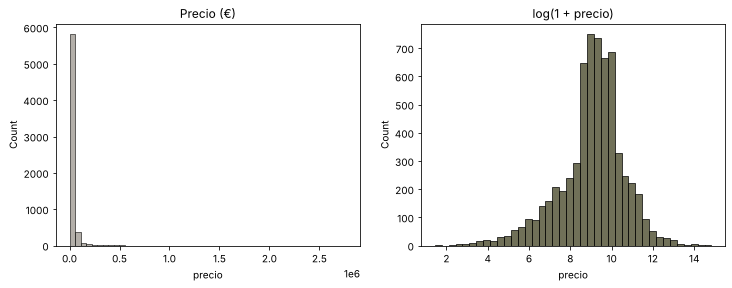

In [10]:
precio = contratos["precio"]
q1 = precio.quantile(0.25)
q3 = precio.quantile(0.75)
print("mediana:", round(precio.median()), "| media:", round(precio.mean()), "| asimetría:", round(precio.skew(), 1))
print("atípicos (Tukey):", (precio > q3 + 1.5 * (q3 - q1)).sum())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(precio, bins=50, color=COLORES["gris"], ax=ax[0])
ax[0].set_title("Precio (€)")
sns.histplot(np.log1p(precio), bins=40, color=COLORES["verde_serra"], ax=ax[1])
ax[1].set_title("log(1 + precio)")
plt.show()

**Qué saco.** La media (23.608 €) es más del doble de la mediana (9.842 €) y hay 740 atípicos. No los quito: son compras reales. Resumo con la mediana y, en las pruebas, uso el logaritmo.

**Para los datos y la presentación.** Para los datos: decisión de limpieza documentada (atípicos sí se quedan). Para la presentación: «hablo de medianas porque unos pocos contratos enormes inflan la media».

**Por qué lo hago.** Algunas pruebas suponen datos normales; antes de usarlas quiero saberlo.

**Por qué este código.** La prueba de Shapiro (semana 5) al precio y a su logaritmo. Uso solo 2025 (1.127 contratos) porque Shapiro da p-valores fiables hasta unos 5.000 datos.

<sub>Lo que uso: `len`, `range`, `round`... (semana 1), filtro con una condición (semana 2), `stats.shapiro` (semana 5), `np.log1p` (semana 5).</sub>

In [11]:
precio_2025 = contratos[contratos["ano"] == 2025]["precio"]
print(len(precio_2025), "contratos de 2025")
w, p = stats.shapiro(precio_2025)
print("precio | W =", round(w, 2), "| p =", round(p, 4))
w, p = stats.shapiro(np.log1p(precio_2025))
print("log(1 + precio) | W =", round(w, 2), "| p =", round(p, 4))

1127 contratos de 2025
precio | W = 0.33 | p = 0.0
log(1 + precio) | W = 0.98 | p = 0.0


**Qué saco.** Ninguno de los dos es normal (p < 0,05), pero el logaritmo se acerca mucho: W pasa de 0,33 a 0,98.

**Para los datos y la presentación.** Para los datos: en las pruebas de precio uso el logaritmo y la t de Welch, que no supone varianzas iguales. Para la presentación: no, es técnica.

**Por qué lo hago.** Las tablas se entienden mejor con un caso real. Elijo el Agrupamento de Escolas de Arganil, a 22 km de la fábrica.

**Por qué este código.** Un filtro con una condición y `sort_values` por fecha (semana 2). No hace falta nada más para leer su historia.

<sub>Lo que uso: filtro con una condición (semana 2), `sort_values` / `sort_index` (semana 2).</sub>

In [12]:
ejemplo = contratos[contratos["comprador"] == "Agrupamento de Escolas de Arganil"].sort_values("fecha")
ejemplo[["fecha", "producto", "objectocontrato", "proveedor", "precio"]]

,fecha,producto,objectocontrato,proveedor,precio
1162,2021-04-30,otra ropa,Contratação de vestuário personalizado para os...,"ARGOMAGAZINE-ARTES GRÁFICAS E PAPELARIA, LDA",5000.0
1200,2021-05-07,merchandising,Material Gráfico/2021: Contratação de material...,WAW DESIGN UNIPESSOAL LDA,6600.0
2100,2022-04-07,merchandising,Contratação de material gráfico personalizado ...,WAW DESIGN UNIPESSOAL LDA,6600.0
2113,2022-04-21,otra ropa,Contratação de aquisição de vestuário personal...,"ARGOMAGAZINE - ARTES GRÁFICA E PAPELARIA, LDA.",5000.0
3023,2023-03-24,merchandising,Contratação de aquisição de material gráfico p...,WAW DESIGN UNIPESSOAL LDA,8000.0
3140,2023-05-18,ropa de trabajo,Procedimento de contratação de aquisição de ve...,"ARGOMAGAZINE - ARTES GRÁFICA E PAPELARIA, LDA.",5000.0
3792,2023-12-28,merchandising,Aquisição de material gráfico personalizado pa...,WAW DESIGN UNIPESSOAL LDA,25000.0
4268,2024-04-10,merchandising,"Material Gráfico/2024, material gráfico person...",WAW DESIGN UNIPESSOAL LDA,25000.0
5430,2025-04-02,merchandising,Material Gráfico/2025: Contratação de material...,WAW DESIGN UNIPESSOAL LDA,25000.0


**Qué saco.** Nueve contratos en cinco años, casi todos entre marzo y mayo. Cada año de 2021 a 2023 compró ropa personalizada para los alumnos (5.000 €) y material gráfico personalizado. Es exactamente el cliente que busca la beira., y el momento de proponerle algo es antes de marzo.

**Para los datos y la presentación.** Para los datos: este comprador encabezará la lista. Para la presentación: es el ejemplo con el que abro, porque se entiende sin estadística.

## Problemas de calidad que encontré y qué hice

| Problema | Dónde | Qué pasaría si no lo trato | Qué hago |
|---|---|---|---|
| Columnas casi vacías que no uso | contratos (anuncio, concurrentes, enlace, PME) | ruido en la tabla | las quito |
| Municipio vacío (824) o mal escrito | contratos | se perderían cámaras de la región y entrarían organismos nacionales | no lo relleno; asigno el municipio por el nombre del comprador y por el lugar de sus contratos (sección 5) |
| El mismo comprador con varios nombres | contratos | un comprador contado varias veces | uso el NIF como clave y el nombre más repetido |
| Precio con cola larga y 740 atípicos | contratos | la media engaña | los dejo (son reales), resumo con la mediana y pruebo con el logaritmo |
| Precio no normal | contratos | pruebas mal aplicadas | logaritmo, chi-cuadrado y t de Welch |
| Contratos que no son ropa (protección, merchandising) | contratos | la lista mezclaría compradores que no son clientes | regla de ropa y fardamento y comprobación de H1 y H2 solo con ella (sección 5) |
| Proveedores sin NIF (personas) | contratos | datos personales en el repositorio | código SN1, SN2... en las tablas públicas |
| Importes como texto («1.215,24 €») | facturas | no se pueden sumar | función `a_numero` |
| Facturas anuladas (41) y notas de crédito (13) | facturas | facturación inflada | quito las anuladas y resto las notas de crédito |
| 2020 y 2021 incompletos (límite de descarga) | facturas | años que parecen malos sin serlo | fuera de las pruebas anuales |
| NIF y números de factura de clientes | facturas | datos internos expuestos | los clientes van en código (C1, C2...) y no salen NIF ni números |
| Junta de Freguesia de Alvoco das Várzeas | todas | conflicto de intereses | fuera de todas las tablas |

> **Resumo da secção (português).** Os contratos não têm duplicados nem preços impossíveis. Tiro as colunas vazias que não uso, transformo a data em data e crio o grupo «peças de equipa». O preço tem uma cauda muito longa (média de 23.608 € contra mediana de 9.842 €): não tiro os atípicos, que são compras reais, e trabalho com a mediana e com o logaritmo. A escola de Arganil é o exemplo do cliente que a beira. procura: compra todos os anos, entre Março e Maio. No fim fica a tabela dos problemas de qualidade e do que fiz a cada um.

# 4. El mercado público de ropa

Antes de elegir a nadie quiero entender el mercado: quién compra, qué compra, cuándo y si vuelve a comprar. Aquí están H1, H2 y H3.

**Por qué lo hago.** Quiero saber qué tipo de entidad pública compra más ropa y cuál hace pedidos del tamaño de la beira.

**Por qué este código.** Agrupo por tipo de comprador y junto en una tabla, con `pd.concat`, el número de compradores, de contratos, el gasto y el precio mediano. Podría hacer cuatro tablas, pero juntas se comparan de un vistazo.

<sub>Lo que uso: `groupby` (semana 2), `pd.concat` (semana 2), `unique` / `nunique` (semana 2), `agg`, `size`, `sum`, `mean`, `median`... (semana 2), `.columns =` (semana 2), `sort_values` / `sort_index` (semana 2).</sub>

In [13]:
grupo = contratos.groupby("tipo_comprador")
quien_compra = pd.concat([grupo["comprador_nif"].nunique(), grupo.size(), grupo["precio"].sum(), grupo["precio"].median()], axis=1)
quien_compra.columns = ["compradores", "contratos", "gasto_millones", "precio_mediano"]
quien_compra["gasto_millones"] = (quien_compra["gasto_millones"] / 1000000).round(1)
quien_compra.sort_values("contratos", ascending=False)

,compradores,contratos,gasto_millones,precio_mediano
tipo_comprador,,,,
otro,421,3252,89.6,9508.750
camara,268,2479,56.1,11987.710
escuela,128,414,2.2,3202.950
junta,74,233,2.6,7955.000
bomberos,3,4,0.1,22531.925


**Qué saco.** De 150,7 M€ en seis años, los «otros» organismos (ministerios, hospitales, universidades) gastan 89,6 M€ y las cámaras 56,1 M€. Las escuelas son 128 compradores pero gastan poco (2,2 M€) y en contratos pequeños.

**Para los datos y la presentación.** Para los datos: el tipo de comprador será un filtro en Tableau y en la app. Para la presentación: «las escuelas compran poco cada vez, justo el tamaño de la beira.».

**Por qué lo hago.** Veo que el precio cambia con el tipo de comprador, pero quiero comprobar que no es casualidad.

**Por qué este código.** Un diagrama de caja para verlo y dos pruebas para confirmarlo: ANOVA entre los cuatro tipos y t de Welch entre escuelas y cámaras (semana 5). Uso el logaritmo del precio porque no es normal (Shapiro, arriba) y Welch porque los grupos tienen tamaños y varianzas distintos. Quito los bomberos, que solo tienen 4 contratos.

<sub>Lo que uso: `len`, `range`, `round`... (semana 1), filtro con una condición (semana 2), `copy` (semana 2), `sns.boxplot` (semana 2), `head` (semana 2), `np.log1p` (semana 5), `plt.subplots`, `plt.xlabel`, `plt.show`... (semana 5), `stats.f_oneway` (semana 5), `stats.ttest_ind` (`equal_var=False`) (semana 5).</sub>

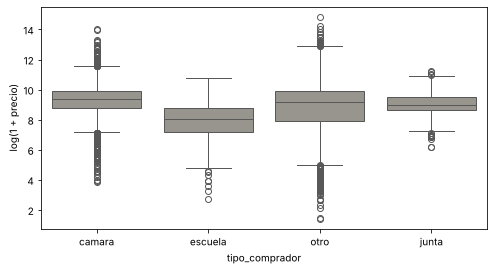

ANOVA entre los cuatro tipos | F = 116.7 | p = 0.0
escuelas frente a cámaras (Welch) | t = -21.3 | p = 0.0
sin_bomberos:
   idcontrato            tipoprocedimento  ... es_equipo log_precio
0     6196722  Ajuste Direto Regime Geral  ...         0   9.777130
1     6211102             Consulta Prévia  ...         0  10.142111
2     6212130             Consulta Prévia  ...         0  10.010407
3     6217700  Ajuste Direto Regime Geral  ...         0   9.224342
4     6222956  Ajuste Direto Regime Geral  ...         0   8.756368

[5 rows x 26 columns]


In [14]:
sin_bomberos = contratos[contratos["tipo_comprador"] != "bomberos"].copy()   # solo 4 contratos
sin_bomberos["log_precio"] = np.log1p(sin_bomberos["precio"])
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=sin_bomberos, x="tipo_comprador", y="log_precio", color=COLORES["gris"], ax=ax)
plt.ylabel("log(1 + precio)")
plt.show()

camara = sin_bomberos[sin_bomberos["tipo_comprador"] == "camara"]["log_precio"]
escuela = sin_bomberos[sin_bomberos["tipo_comprador"] == "escuela"]["log_precio"]
junta = sin_bomberos[sin_bomberos["tipo_comprador"] == "junta"]["log_precio"]
otro = sin_bomberos[sin_bomberos["tipo_comprador"] == "otro"]["log_precio"]
f, p = stats.f_oneway(camara, escuela, junta, otro)
print("ANOVA entre los cuatro tipos | F =", round(f, 1), "| p =", round(p, 4))
t, p = stats.ttest_ind(escuela, camara, equal_var=False)
print("escuelas frente a cámaras (Welch) | t =", round(t, 1), "| p =", round(p, 4))

# primeras filas de las tablas que crea esta celda
print("sin_bomberos:")
print(sin_bomberos.head())

**Qué saco.** El precio cambia con el tipo de comprador (F = 116,7; p < 0,001) y las escuelas compran más barato que las cámaras (t = −21,3; p < 0,001).

**Para los datos y la presentación.** Para los datos: confirma que separar por tipo de comprador tiene sentido. Para la presentación: el diagrama de caja, con una frase: escuelas, pedido pequeño; cámaras, pedido grande.

**Por qué lo hago.** Quiero ver qué prendas pide el mercado público y cuánto pesan las que hace la beira.

**Por qué este código.** Agrupo por prenda y ordeno de más a menos contratos; un gráfico de barras horizontal porque los nombres de las prendas son largos.

<sub>Lo que uso: `groupby` (semana 2), `pd.concat` (semana 2), `agg`, `size`, `sum`, `mean`, `median`... (semana 2), `.columns =` (semana 2), `sort_values` / `sort_index` (semana 2), `reset_index` (semana 2), `plt.subplots`, `plt.xlabel`, `plt.show`... (semana 5), `sns.barplot` (semana 5).</sub>

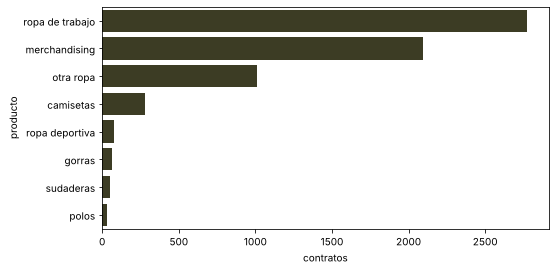

,contratos,precio_mediano
producto,,
ropa de trabajo,2775,10618.470
merchandising,2091,10678.500
otra ropa,1010,7195.000
camisetas,279,7875.000
ropa deportiva,79,9990.000
gorras,65,4608.200
sudaderas,54,13760.205
polos,29,7732.000


In [15]:
grupo = contratos.groupby("producto")
que_compran = pd.concat([grupo.size(), grupo["precio"].median()], axis=1)
que_compran.columns = ["contratos", "precio_mediano"]
que_compran = que_compran.sort_values("contratos", ascending=False)
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=que_compran.reset_index(), x="contratos", y="producto", color=COLORES["verde_serra"], ax=ax)
plt.show()
que_compran

**Qué saco.** Dominan la ropa de trabajo (2.775 contratos) y el merchandising (2.091). Las prendas de equipo (camisetas, ropa deportiva, polos, sudaderas y gorras) son 506 contratos: menos, pero son justo lo que hace la beira.

**Para los datos y la presentación.** Para los datos: `grupo` (prendas de equipo u otras) va a la base de datos. Para la presentación: la ropa de trabajo es la puerta grande; las prendas de equipo, la especialidad.

**Por qué lo hago.** H2: si las prendas de equipo se compran en primavera y verano, la beira. tiene que preparar las propuestas antes.

**Por qué este código.** Cruzo mes y grupo con `crosstab` y lo paso a % dentro de cada grupo, para comparar aunque haya muchas menos prendas de equipo. Para la prueba, son dos variables categóricas (grupo y temporada), así que uso chi-cuadrado, y la V de Cramér para saber si la diferencia es grande o pequeña. `melt` pasa la tabla a formato largo para dibujarla con seaborn.

<sub>Lo que uso: `lambda` (semana 1), `len`, `range`, `round`... (semana 1), `apply` (semana 2), `agg`, `size`, `sum`, `mean`, `median`... (semana 2), `reset_index` (semana 2), `melt` (semana 2), `head` (semana 2), `pd.crosstab` (semana 5), `plt.subplots`, `plt.xlabel`, `plt.show`... (semana 5), `sns.barplot` (semana 5), `chi2_contingency` (semana 5), `association` (semana 5).</sub>

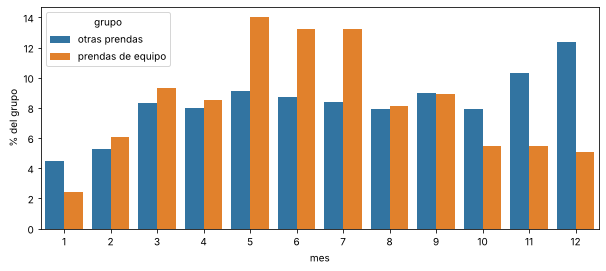

temporada          mayo a septiembre  resto del año
grupo                                              
otras prendas                   43.0           57.0
prendas de equipo               58.0           42.0
chi2 = 37.8 | p = 0.0 | V de Cramér = 0.08
largo:
   mes          grupo  porcentaje
0    1  otras prendas         4.5
1    2  otras prendas         5.3
2    3  otras prendas         8.3
3    4  otras prendas         8.0
4    5  otras prendas         9.1
grupo  otras prendas  prendas de equipo
mes                                    
1                4.5                2.4
2                5.3                6.1
3                8.3                9.3
4                8.0                8.5
5                9.1               14.0
6                8.7               13.2
7                8.4               13.2
8                7.9                8.1
9                9.0                8.9
10               7.9                5.5
11              10.3                5.5
12              12

,fecha,producto,grupo,temporada
0,2020-01-06,ropa de trabajo,otras prendas,resto del año
1,2020-01-08,ropa de trabajo,otras prendas,resto del año
2,2020-01-15,ropa de trabajo,otras prendas,resto del año
3,2020-01-16,otra ropa,otras prendas,resto del año
4,2020-01-16,merchandising,otras prendas,resto del año


In [16]:
meses_grupo = pd.crosstab(contratos["mes"], contratos["grupo"])
meses_grupo = meses_grupo.apply(lambda columna: columna / columna.sum() * 100).round(1)
largo = meses_grupo.reset_index().melt(id_vars="mes", var_name="grupo", value_name="porcentaje")
fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(data=largo, x="mes", y="porcentaje", hue="grupo", ax=ax)
plt.ylabel("% del grupo")
plt.show()

contratos["temporada"] = contratos["mes"].apply(lambda m: "mayo a septiembre" if m in [5, 6, 7, 8, 9] else "resto del año")
tabla = pd.crosstab(contratos["grupo"], contratos["temporada"])
print(tabla.apply(lambda fila: fila / fila.sum() * 100, axis=1).round(0))
chi2, p, gl, esperado = stats.chi2_contingency(tabla)
print("chi2 =", round(chi2, 1), "| p =", round(p, 4), "| V de Cramér =", round(association(tabla, method="cramer"), 2))

# primeras filas de las tablas que crea esta celda
print("largo:")
print(largo.head())
print(meses_grupo)
contratos[["fecha", "producto", "grupo", "temporada"]].head()

**Qué saco.** H2 se cumple: el 58 % de las prendas de equipo se compra de mayo a septiembre, frente al 43 % del resto (p < 0,001). La V de Cramér es baja (0,08): la diferencia es real pero pequeña. El pico es de mayo a julio.

**Para los datos y la presentación.** Para los datos: la temporada entra en el calendario de contactos (sección 6). Para la presentación: H2 sí, con matiz: «hay temporada, pero se compra todo el año».

**Por qué lo hago.** H1 es la hipótesis central: si quien compra un año vuelve al siguiente, puedo elegir a quién dirigirme mirando su historia.

**Por qué este código.** Hago una tabla comprador × año con `crosstab` (1 si compró) y formo pares «compra este año / compra el siguiente» para 2020-2024, solo con quien ya había comprado alguna vez (si no, contaría como «no vuelve» a quien aún no existía). Chi-cuadrado y V de Cramér, como en H2.

<sub>Lo que uso: `for` (semana 1), `len`, `range`, `round`... (semana 1), `lambda` (semana 1), `drop_duplicates` (semana 2), `groupby` (semana 2), `agg`, `size`, `sum`, `mean`, `median`... (semana 2), `loc` / `iloc` (semana 2), `.columns =` (semana 2), `pd.concat` (semana 2), `reset_index` (semana 2), `apply` (semana 2), `head` (semana 2), `shape` (semana 2), `pd.crosstab` (semana 5), `chi2_contingency` (semana 5), `association` (semana 5).</sub>

In [17]:
compras = contratos[["comprador_nif", "ano"]].drop_duplicates()
matriz = pd.crosstab(compras["comprador_nif"], compras["ano"])   # 1 si compró ese año
primer_ano = compras.groupby("comprador_nif")["ano"].min()

partes = []
for ano in range(2020, 2025):
    trozo = matriz.loc[primer_ano[primer_ano <= ano].index, [ano, ano + 1]]
    trozo.columns = ["compra_este_ano", "compra_el_siguiente"]
    partes.append(trozo)
pares = pd.concat(partes).reset_index(drop=True)

tabla = pd.crosstab(pares["compra_este_ano"], pares["compra_el_siguiente"])
print(tabla.apply(lambda fila: fila / fila.sum() * 100, axis=1).round(0))
chi2, p, gl, esperado = stats.chi2_contingency(tabla)
print(len(pares), "pares comprador-año | chi2 =", round(chi2, 1), "| p =", round(p, 4), "| V de Cramér =", round(association(tabla, method="cramer"), 2))

# primeras filas de las tablas que crea esta celda
print("compras:")
print(compras.head())
print(matriz.shape)
print(matriz.head())
print(pares.shape)
pares.head()

compra_el_siguiente     0     1
compra_este_ano                
0                    71.0  29.0
1                    38.0  62.0
2907 pares comprador-año | chi2 = 289.4 | p = 0.0 | V de Cramér = 0.32
compras:
   comprador_nif   ano
0      505330768  2020
1      504404830  2020
2      506876330  2020
3      503494933  2020
4      502176482  2020
(890, 6)
ano            2020  2021  2022  2023  2024  2025
comprador_nif                                    
500051054         1     1     1     1     1     1
500051062         1     1     1     1     1     1
500051070         1     1     1     1     1     1
500086826         1     1     1     1     1     1
500122237         1     1     1     1     1     1
(2907, 2)


,compra_este_ano,compra_el_siguiente
0,1,1
1,1,1
2,1,1
3,1,1
4,1,1


**Qué saco.** H1 se cumple con fuerza: el 62 % de los que compran un año vuelve al siguiente, frente al 29 % de los que no compraron (p < 0,001; V = 0,32). La tabla `matriz` tiene 890 compradores × 6 años y de ella salen 2.907 pares.

**Para los datos y la presentación.** Para los datos: la lista de la sección 5 se basa en esto. Para la presentación: es el resultado principal de la parte A: «quien compra, repite: 62 % frente a 29 %».

**Por qué lo hago.** Clubes y asociaciones casi no compran por el Portal BASE; si la beira. quiere venderles, tiene que poder llegar a ellos. Para H3 necesito sus datos de contacto.

**Por qué este código.** Leo las organizaciones del proyecto 1 y aplico la regla de exclusión con mi función, como en todas las tablas.

<sub>Lo que uso: `shape` (semana 2), `head` (semana 2).</sub>

In [18]:
organizaciones = sin_junta_excluida(leer("organizaciones"), "nombre")
print(organizaciones.shape)
organizaciones[["nombre", "municipio", "segmento", "email", "telefono", "web", "nivel_contacto"]].head()

(1596, 20)


,nombre,municipio,segmento,email,telefono,web,nivel_contacto
0,Bombeiros Voluntários de Aguiar da Beira,Aguiar da Beira,bomberos,NaN,3.512327e+11,http://www.bombeiros.pt/cb/?cb=915,solo web
1,Centro Social Paroquial de Cortiçada,Aguiar da Beira,asociacion,NaN,NaN,NaN,sin contacto
2,Complexo Desportivo Municipal de Aguiar da Beira,Aguiar da Beira,instalacion_deportiva,NaN,NaN,NaN,sin contacto
3,Câmara Municipal de Aguiar da Beira,Aguiar da Beira,autarquia,NaN,NaN,NaN,sin contacto
4,Escola Básica de Aguiar da Beira,Aguiar da Beira,escuela,eb1.aguiarbeira@escolas.min-edu.pt,3.512327e+11,NaN,email


**Qué saco.** Una fila por organización, con su tipo, sus datos de contacto y el nivel de contacto que los resume.

**Para los datos y la presentación.** Para los datos: es la tabla `organizaciones` de MySQL. Para la presentación: no.

**Por qué lo hago.** H3: ¿a clubes y asociaciones se llega por internet o hay que ir en persona?

**Por qué este código.** Un mapa de calor de tipo de organización × nivel de contacto enseña todo de una vez. Después junto clubes y asociaciones y los comparo con las escuelas con chi-cuadrado y V de Cramér, que es la prueba para dos variables categóricas.

<sub>Lo que uso: `lambda` (semana 1), `len`, `range`, `round`... (semana 1), `apply` (semana 2), `agg`, `size`, `sum`, `mean`, `median`... (semana 2), `sort_values` / `sort_index` (semana 2), `sns.heatmap` (semana 2), `isin` (semana 2), `copy` (semana 2), `map` (semana 2), `head` (semana 2), `pd.crosstab` (semana 5), `plt.subplots`, `plt.xlabel`, `plt.show`... (semana 5), `chi2_contingency` (semana 5), `association` (semana 5).</sub>

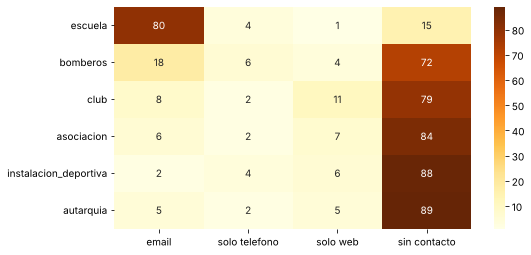

tiene_contacto           no    sí
grupo                            
clubes y asociaciones  82.0  18.0
escuelas               15.0  85.0
chi2 = 289.6 | p = 0.0 | V de Cramér = 0.56
contacto:
nivel_contacto         email  solo telefono  solo web  sin contacto
segmento                                                           
escuela                 80.0            4.0       1.0          15.0
bomberos                18.0            6.0       4.0          72.0
club                     8.0            2.0      11.0          79.0
asociacion               6.0            2.0       7.0          84.0
instalacion_deportiva    2.0            4.0       6.0          88.0
grupos:
  osm_tipo        osm_id  ...                  grupo tiene_contacto
1      way  1.264669e+09  ...  clubes y asociaciones             no
4      way  1.264669e+09  ...               escuelas             sí
5      way  1.264669e+09  ...               escuelas             sí
6      way  1.264669e+09  ...               escuelas  

In [19]:
contacto = pd.crosstab(organizaciones["segmento"], organizaciones["nivel_contacto"])
contacto = contacto.apply(lambda fila: fila / fila.sum() * 100, axis=1).round(0)
contacto = contacto[["email", "solo telefono", "solo web", "sin contacto"]].sort_values("sin contacto")
fig, ax = plt.subplots(figsize=(8, 4))
sns.heatmap(contacto, annot=True, fmt=".0f", cmap="YlOrBr", ax=ax)
plt.xlabel("")
plt.ylabel("")
plt.show()

grupos = organizaciones[organizaciones["segmento"].isin(["club", "asociacion", "escuela"])].copy()
grupos["grupo"] = grupos["segmento"].map({"club": "clubes y asociaciones", "asociacion": "clubes y asociaciones", "escuela": "escuelas"})
grupos["tiene_contacto"] = grupos["nivel_contacto"].apply(lambda nivel: "sí" if nivel != "sin contacto" else "no")
tabla = pd.crosstab(grupos["grupo"], grupos["tiene_contacto"])
print(tabla.apply(lambda fila: fila / fila.sum() * 100, axis=1).round(0))
chi2, p, gl, esperado = stats.chi2_contingency(tabla)
print("chi2 =", round(chi2, 1), "| p =", round(p, 4), "| V de Cramér =", round(association(tabla, method="cramer"), 2))

# primeras filas de las tablas que crea esta celda
print("contacto:")
print(contacto.head())
print("grupos:")
print(grupos.head())

**Qué saco.** H3 se cumple, y con fuerza (V = 0,56): solo el 18 % de clubes y asociaciones tiene algún contacto público, frente al 85 % de las escuelas.

**Para los datos y la presentación.** Para los datos: separa dos canales: entidades públicas por email y contratos, clubes por el terreno. Para la presentación: «a los clubes hay que ir en persona».

**Por qué lo hago.** La beira. quiere empezar cerca de casa. Quiero ver qué municipios cercanos tienen compra pública y organizaciones.

**Por qué este código.** Filtro los municipios a menos de `KM_CERCA` km (50, en `config.py`) y los ordeno por distancia. Es un filtro simple de la semana 2.

<sub>Lo que uso: `len`, `range`, `round`... (semana 1), filtro con una condición (semana 2), `sort_values` / `sort_index` (semana 2), `head` (semana 2).</sub>

In [20]:
municipios = leer("municipios")
cerca = municipios[municipios["km_a_la_base"] <= KM_CERCA].sort_values("km_a_la_base")
print(len(cerca), "municipios a menos de", KM_CERCA, "km")
# primeras filas de las tablas que crea esta celda
print("municipios:")
print(municipios.head())
cerca[["municipio", "km_a_la_base", "poblacion", "poblacion_5_24", "total_organizaciones", "contratos_publicos_ropa", "gasto_publico_ropa", "competencia_total"]]

30 municipios a menos de 50 km
municipios:
         municipio distrito  ...  graficas_publicidad  graficas_total
0          Arganil  Coimbra  ...                  0.0             1.0
1       Cantanhede  Coimbra  ...                  0.0             0.0
2          Coimbra  Coimbra  ...                  0.0             7.0
3  Condeixa-a-Nova  Coimbra  ...                  0.0             0.0
4  Figueira da Foz  Coimbra  ...                  0.0             0.0

[5 rows x 55 columns]


,municipio,km_a_la_base,poblacion,poblacion_5_24,total_organizaciones,contratos_publicos_ropa,gasto_publico_ropa,competencia_total
10,Oliveira do Hospital,3.0,19845,3419,30,4,18061.14,2
15,Tábua,14.0,11533,1990,18,1,11882.00,1
18,Carregal do Sal,15.0,9406,1650,14,2,25670.00,1
52,Seia,15.0,21745,3362,24,0,0.00,4
25,Nelas,19.0,13560,2503,24,3,2807.43,8
0,Arganil,22.0,11338,1794,43,10,82910.43,7
30,Santa Comba Dão,23.0,10951,1910,9,0,0.00,0
37,Tondela,26.0,26447,4475,50,2,33167.50,8
46,Gouveia,27.0,11905,1756,27,1,7434.25,1
48,Manteigas,28.0,2996,376,10,0,0.00,1


**Qué saco.** Hay 30 municipios a menos de 50 km. Seis no compraron ropa por el Portal BASE en 2020-2025 aunque tienen organizaciones (entre ellos Seia y Santa Comba Dão). Viseu es el que más organizaciones tiene (122).

**Para los datos y la presentación.** Para los datos: `km_a_la_base` es una columna clave de la lista. Para la presentación: el mapa de la región con el radio de 50 km.

**Por qué lo hago.** Quiero ver de un vistazo qué municipios cercanos gastan más en ropa.

**Por qué este código.** Un gráfico de barras ordenado es lo más directo para comparar 30 valores.

<sub>Lo que uso: `plt.subplots`, `plt.xlabel`, `plt.show`... (semana 5), `sns.barplot` (semana 5).</sub>

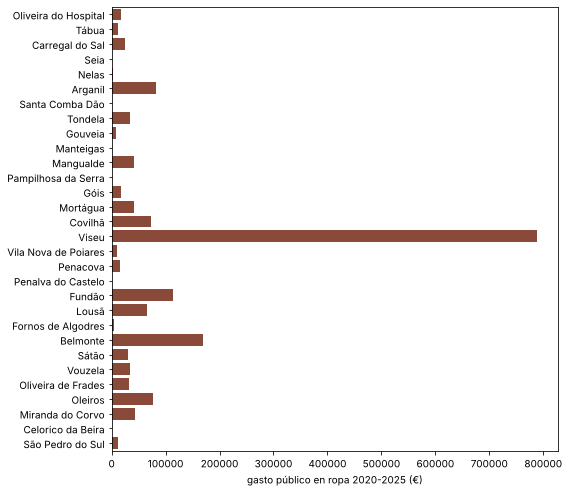

In [21]:
fig, ax = plt.subplots(figsize=(8, 8))
sns.barplot(data=cerca, x="gasto_publico_ropa", y="municipio", color=COLORES["terracota"], ax=ax)
plt.xlabel("gasto público en ropa 2020-2025 (€)")
plt.ylabel("")
plt.show()

**Qué saco.** Viseu (a 34 km) es el gran comprador cercano: 54 contratos y 788.012 €, aunque con mucha competencia. Oliveira do Hospital, Tábua y Seia compran poco por el Portal BASE: cerca de casa el público está en las organizaciones, no en los contratos.

**Para los datos y la presentación.** Para los datos: nada nuevo. Para la presentación: este gráfico explica por qué la beira. necesita dos canales.

**Por qué lo hago.** ¿Qué pesa más en lo que gasta un municipio, su tamaño o su cercanía? De eso depende por dónde empezar.

**Por qué este código.** Correlación de Pearson con su p-valor (semana 5) entre jóvenes de 5 a 24 años y gasto en ropa, y entre distancia y gasto. Uso el logaritmo del gasto porque tiene una cola muy larga; con la cola, una sola Viseu movería la correlación.

<sub>Lo que uso: `len`, `range`, `round`... (semana 1), `sns.scatterplot` (semana 2), `stats.pearsonr` (semana 5), `np.log1p` (semana 5), `plt.subplots`, `plt.xlabel`, `plt.show`... (semana 5).</sub>

jóvenes de 5 a 24 años y gasto en ropa | r = 0.34 | p = 0.005
distancia a la PAISAN y gasto en ropa | r = 0.12 | p = 0.336


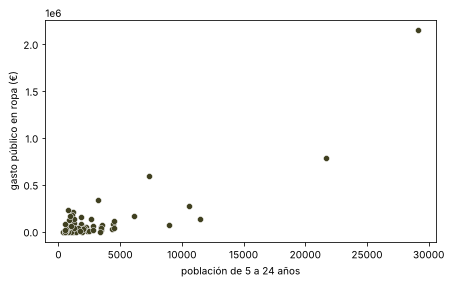

In [22]:
r, p = stats.pearsonr(municipios["poblacion_5_24"], np.log1p(municipios["gasto_publico_ropa"]))
print("jóvenes de 5 a 24 años y gasto en ropa | r =", round(r, 2), "| p =", round(p, 4))
r, p = stats.pearsonr(municipios["km_a_la_base"], np.log1p(municipios["gasto_publico_ropa"]))
print("distancia a la PAISAN y gasto en ropa | r =", round(r, 2), "| p =", round(p, 4))

fig, ax = plt.subplots(figsize=(7, 4))
sns.scatterplot(data=municipios, x="poblacion_5_24", y="gasto_publico_ropa", color=COLORES["verde_serra"], ax=ax)
plt.xlabel("población de 5 a 24 años")
plt.ylabel("gasto público en ropa (€)")
plt.show()

**Qué saco.** Los municipios con más jóvenes gastan más (r = 0,34; p = 0,005); la distancia no tiene relación con el gasto (r = 0,12; p = 0,34).

**Para los datos y la presentación.** Para los datos: la distancia sirve para ordenar la lista, no para descartar. Para la presentación: «pesa más el tamaño que la cercanía: Viseu y Covilhã importan aunque estén a más de 30 km».

> **Resumo da secção (português).** As escolas compram pouco de cada vez (mediana de 3.203 €), o tamanho da beira. H1 cumpre-se: 62 % de quem compra num ano volta a comprar no seguinte, contra 29 % de quem não comprou. H2 cumpre-se mas com efeito pequeno: as peças de equipa compram-se mais de Maio a Setembro. H3 cumpre-se com força: só 18 % dos clubes e associações têm contacto público, contra 85 % das escolas, por isso aos clubes chega-se no terreno. O tamanho do concelho pesa mais do que a distância.

# 5. A quién dirigirse: la lista

Con H1 confirmada, la lista sale de la historia de compra: entidades de la región que compran ropa en dos años o más, ordenadas por cercanía y con su mes habitual. Antes tengo que saber en qué municipio está cada comprador.

**Por qué lo hago.** La columna `municipio` de los contratos dice dónde se entrega, viene vacía en 824 filas y a veces mal escrita. Con ella sola perdía cámaras de la región (Covilhã, Seia) y entraban organismos nacionales. Necesito el municipio de cada comprador, no de cada contrato.

**Por qué este código.** Combino dos pistas con tres funciones que defino aquí (y están también en `src/funciones.py`): `concelho_por_nombre` busca el municipio en el nombre («Município de Seia»), `lugar_del_contrato` traduce el lugar de cada contrato y `elegir_concelho` decide (si la mayoría de sus contratos es fuera, queda fuera; si no, manda el nombre). `normalizar` quita acentos y signos para comparar textos. Es más trabajo que usar la columna tal cual, pero es la única forma de no perder compradores.

<sub>Lo que uso: `def` y `return` (semana 1), `lower`, `replace`, `split`, `join`, `strip`, `startswith`, `endswith` (semana 1), `for` (semana 1), `items` y `get` (semana 1), `if` / `else` (semana 1), `len`, `range`, `round`... (semana 1), comprensión de listas y diccionarios (semana 1), `lambda` (semana 1), `groupby` (semana 2), `agg`, `size`, `sum`, `mean`, `median`... (semana 2), `reset_index` (semana 2), `.columns =` (semana 2), `sort_values` / `sort_index` (semana 2), `drop_duplicates` (semana 2), `merge` (semana 2), `dropna` / `fillna` (semana 2), `apply` (semana 2), filtro con una condición (semana 2), `head` (semana 2), `isin` (semana 2).</sub>

In [23]:
def normalizar(texto):
    """Minúsculas, sin acentos ni signos y con un espacio a cada lado, para buscar palabras enteras."""
    texto = str(texto).lower()
    for letra, cambio in ACENTOS.items():
        texto = texto.replace(letra, cambio)
    for signo in SIGNOS:
        texto = texto.replace(signo, " ")
    return " " + " ".join(texto.split()) + " "


def concelho_por_nombre(nombre, nombres_concelho):
    """El municipio que aparece en el nombre del comprador, si solo hay uno; si no, texto vacío.

    nombres_concelho es un diccionario {nombre normalizado: nombre del municipio}.
    """
    texto = normalizar(nombre)
    hallados = []
    for clave, municipio in nombres_concelho.items():
        if " de" + clave in texto or " da" + clave in texto or " do" + clave in texto or texto.endswith(clave):
            hallados.append(municipio)
    if len(hallados) == 1:
        return hallados[0]
    return ""


def lugar_del_contrato(lugar, nombres_concelho):
    """El municipio de la región que dice la columna municipio del contrato; «fuera» si es otro; texto vacío si no dice nada."""
    if lugar == "":
        return ""
    return nombres_concelho.get(normalizar(lugar.split("\n")[0]), "fuera")


def elegir_concelho(lugar, por_nombre):
    """Fuera si la mayoría de sus contratos está fuera; si no, manda el nombre y después el lugar."""
    if lugar == "fuera":
        return ""
    if por_nombre != "":
        return por_nombre
    return lugar


nombres_concelho = {normalizar(m): m for m in municipios["municipio"]}


# 1. el nombre más repetido de cada comprador y su tipo
conteo = contratos.groupby(["comprador_nif", "comprador"]).size().reset_index()
conteo.columns = ["comprador_nif", "comprador", "veces"]
compradores = conteo.sort_values(["veces", "comprador"], ascending=[False, True]).drop_duplicates("comprador_nif")[["comprador_nif", "comprador"]]
tipos = contratos[["comprador_nif", "tipo_comprador"]].drop_duplicates("comprador_nif")
compradores = compradores.merge(tipos, on="comprador_nif")

# 2. el lugar de la mitad o más de sus contratos (solo contratos con lugar)
contratos["lugar"] = contratos["municipio"].fillna("").apply(lambda lugar: lugar_del_contrato(lugar, nombres_concelho))
lugares = contratos[contratos["lugar"] != ""].groupby(["comprador_nif", "lugar"]).size().reset_index()
lugares.columns = ["comprador_nif", "lugar", "veces"]
total = lugares.groupby("comprador_nif")["veces"].sum().reset_index()
total.columns = ["comprador_nif", "total"]
lugares = lugares.merge(total, on="comprador_nif")
lugares["parte"] = lugares["veces"] / lugares["total"]
lugares = lugares[lugares["parte"] >= 0.5].sort_values(["parte", "lugar"], ascending=[False, True]).drop_duplicates("comprador_nif")
compradores = compradores.merge(lugares[["comprador_nif", "lugar"]], on="comprador_nif", how="left")
compradores["lugar"] = compradores["lugar"].fillna("")

# 3. el municipio: primero el nombre, después el lugar
compradores["por_nombre"] = compradores["comprador"].apply(lambda nombre: concelho_por_nombre(nombre, nombres_concelho))
compradores["concelho"] = compradores.apply(lambda fila: elegir_concelho(fila["lugar"], fila["por_nombre"]), axis=1)
print("compradores en los 66 municipios:", (compradores["concelho"] != "").sum(), "de", len(compradores))
ejemplos = ["Município da Covilhã", "Município de Seia", "Município de Oliveira do Hospital", "Instituto do Emprego e da Formação Profissional, I. P."]
# primeras filas de las tablas que crea esta celda
print("conteo:")
print(conteo.head())
print("tipos:")
print(tipos.head())
print("lugares:")
print(lugares.head())
print("total:")
print(total.head())
compradores[compradores["comprador"].isin(ejemplos)][["comprador", "lugar", "por_nombre", "concelho"]]

compradores en los 66 municipios: 113 de 890
conteo:
   comprador_nif                   comprador  veces
0      500051054  CÂMARA MUNICIPAL DE ALMADA      2
1      500051054  Câmara Municipal de Almada      1
2      500051054         Município de Almada     34
3      500051062         Município de Sintra     42
4      500051070         Município de Lisboa     77
tipos:
   comprador_nif tipo_comprador
0      505330768         camara
1      504404830        escuela
2      506876330         camara
3      503494933           otro
4      502176482          junta
lugares:
     comprador_nif            lugar  veces  total  parte
401      506809307  Aguiar da Beira      1      1    1.0
217      504260936          Almeida      1      1    1.0
351      506625419          Almeida      5      5    1.0
429      506843190          Armamar      2      2    1.0
370      506695956         Belmonte      7      7    1.0
total:
   comprador_nif  total
0      500051054     36
1      500051062     40
2     

,comprador,lugar,por_nombre,concelho
4,Instituto do Emprego e da Formação Profissiona...,fuera,,
570,Município de Seia,,Seia,Seia
783,Município da Covilhã,,Covilhã,Covilhã
816,Município de Oliveira do Hospital,Oliveira do Hospital,Oliveira do Hospital,Oliveira do Hospital


**Qué saco.** Quedan 113 compradores en los 66 municipios. Entran Covilhã y Seia, que tenían el lugar vacío, y sale el IEFP, que compra para todo el país. Con la columna sola eran 99.

**Para los datos y la presentación.** Para los datos: `compradores` con su municipio es la tabla `compradores` de MySQL. Para la presentación: «113 entidades públicas de la región compran ropa».

**Por qué lo hago.** Este es el resultado principal de la parte A: la lista de entidades a las que dirigirse, dónde están y cuándo suelen comprar.

**Por qué este código.** Para cada comprador cuento años con compra, contratos, precio mediano y último año (`groupby` y `pd.concat`). El mes habitual lo saco contando compras por mes, ordenando y quedándome con el primero (`drop_duplicates`): es la moda sin usar nada que no se diera en clase. Si dos meses empatan, ordeno también por el mes y gana el más temprano; sin ese desempate, cada ordenador podía elegir uno distinto. Filtro los que compraron en dos años o más, porque por H1 son los que más vuelven.

<sub>Lo que uso: `len`, `range`, `round`... (semana 1), `groupby` (semana 2), `pd.concat` (semana 2), `unique` / `nunique` (semana 2), `agg`, `size`, `sum`, `mean`, `median`... (semana 2), `.columns =` (semana 2), `reset_index` (semana 2), filtro con una condición (semana 2), `rename` (semana 2), `merge` (semana 2), `sort_values` / `sort_index` (semana 2), `drop_duplicates` (semana 2), `value_counts` (semana 2), `head` (semana 2).</sub>

In [24]:
grupo = contratos.groupby("comprador_nif")
entidades = pd.concat([grupo["ano"].nunique(), grupo.size(), grupo["precio"].median(), grupo["ano"].max()], axis=1)
entidades.columns = ["anos_con_compra", "contratos", "precio_mediano", "ultimo_ano"]
entidades = entidades.reset_index()

quien = compradores[compradores["concelho"] != ""][["comprador_nif", "comprador", "tipo_comprador", "concelho"]]
quien = quien.rename(columns={"concelho": "municipio"}).merge(municipios[["municipio", "km_a_la_base"]], on="municipio")

conteo = contratos.groupby(["comprador_nif", "mes"]).size().reset_index()
conteo.columns = ["comprador_nif", "mes_habitual", "veces"]
mes_habitual = conteo.sort_values(["veces", "mes_habitual"], ascending=[False, True]).drop_duplicates("comprador_nif")[["comprador_nif", "mes_habitual"]]

entidades = entidades.merge(quien, on="comprador_nif").merge(mes_habitual, on="comprador_nif")
print(len(entidades), "entidades públicas de la región compraron ropa en 2020-2025")
repiten = entidades[entidades["anos_con_compra"] >= 2].sort_values(["km_a_la_base", "comprador"])
print(len(repiten), "compraron en dos años o más |", (repiten["ultimo_ano"] >= 2024).sum(), "de ellas compraron en 2024 o 2025")
print(repiten["tipo_comprador"].value_counts())
# primeras filas de las tablas que crea esta celda
print("entidades:")
print(entidades.head())
print("conteo:")
print(conteo.head())
print(quien.head())
print(mes_habitual.head())
repiten[["comprador", "municipio", "tipo_comprador", "km_a_la_base", "anos_con_compra", "ultimo_ano", "precio_mediano", "mes_habitual"]].head(15)

113 entidades públicas de la región compraron ropa en 2020-2025
63 compraron en dos años o más | 55 de ellas compraron en 2024 o 2025
tipo_comprador
camara     34
otro       19
escuela    10
Name: count, dtype: int64
entidades:
   comprador_nif  anos_con_compra  ...  km_a_la_base  mes_habitual
0      500839166                3  ...          51.0             6
1      500980896                1  ...           3.0             3
2      501121030                2  ...          75.0             8
3      501121528                4  ...          42.0             8
4      501131140                5  ...          54.0             8

[5 rows x 10 columns]
conteo:
   comprador_nif  mes_habitual  veces
0      500051054             1      1
1      500051054             2      2
2      500051054             5      1
3      500051054             6      5
4      500051054             7      1
   comprador_nif                comprador  ... municipio km_a_la_base
0      501617582  Universidade de Coimbra

,comprador,municipio,tipo_comprador,km_a_la_base,anos_con_compra,ultimo_ano,precio_mediano,mes_habitual
108,Agrupamento de Escolas de Arganil,Arganil,escuela,22.0,5,2025,6600.000,4
73,Comunidade Intermunicipal Viseu Dão Lafões,Tondela,otro,26.0,2,2025,19930.000,6
105,Agrupamento de Escolas de Mangualde,Mangualde,escuela,28.0,3,2023,996.120,4
8,Município de Mangualde,Mangualde,camara,28.0,2,2025,59310.500,7
92,"Escola Secundária Campos de Melo, Covilhã",Covilhã,escuela,32.0,2,2022,706.700,5
67,Município de Mortágua,Mortágua,camara,32.0,3,2025,4692.500,10
16,Universidade da Beira Interior,Covilhã,otro,32.0,3,2025,16417.500,3
79,"Centro Hospitalar Tondela-Viseu, E. P. E.",Viseu,otro,34.0,5,2025,5045.325,1
112,Instituto Politécnico de Viseu,Viseu,otro,34.0,2,2025,3700.000,11
52,Município de Viseu,Viseu,camara,34.0,6,2025,13435.000,7


**Qué saco.** En la región, 113 entidades compraron ropa; 63 lo hicieron en dos años o más (34 cámaras, 19 organismos y 10 escuelas) y 55 compraron en 2024 o 2025. Abre la lista el Agrupamento de Escolas de Arganil (22 km, cinco años, sobre todo en abril).

**Para los datos y la presentación.** Para los datos: `repiten` es la base de `lista_beira`. Para la presentación: «63 entidades, de la más cercana a la más lejana; a cada una se le escribe antes de su mes habitual».

**Por qué lo hago.** La lista es de la región, pero H1 la probé con todo el país. Quiero comprobar que se cumple también aquí y cada año.

**Por qué este código.** Rehago los pares de H1 guardando el año, calculo la tasa por año con `pivot_table` y repito chi-cuadrado y V de Cramér solo con los compradores de la región. Separar por año dice si es estable o depende de un año raro.

<sub>Lo que uso: `for` (semana 1), `len`, `range`, `round`... (semana 1), `lambda` (semana 1), `loc` / `iloc` (semana 2), `reset_index` (semana 2), `.columns =` (semana 2), `pd.concat` (semana 2), `pivot_table` (semana 2), `isin` (semana 2), filtro con una condición (semana 2), `apply` (semana 2), `agg`, `size`, `sum`, `mean`, `median`... (semana 2), `head` (semana 2), `pd.crosstab` (semana 5), `chi2_contingency` (semana 5), `association` (semana 5).</sub>

In [25]:
partes = []
for ano in range(2020, 2025):
    trozo = matriz.loc[primer_ano[primer_ano <= ano].index, [ano, ano + 1]].reset_index()
    trozo.columns = ["comprador_nif", "compra_este_ano", "compra_el_siguiente"]
    trozo["ano"] = ano
    partes.append(trozo)
pares_ano = pd.concat(partes).reset_index(drop=True)

h1_por_ano = pares_ano.pivot_table(index="ano", columns="compra_este_ano", values="compra_el_siguiente", aggfunc="mean").round(2)
h1_por_ano.columns = ["vuelve si no compró", "vuelve si compró"]
print("todo el país, por año:")
print(h1_por_ano)

region = pares_ano[pares_ano["comprador_nif"].isin(compradores[compradores["concelho"] != ""]["comprador_nif"])]
tabla = pd.crosstab(region["compra_este_ano"], region["compra_el_siguiente"])
print(tabla.apply(lambda fila: fila / fila.sum() * 100, axis=1).round(0))
chi2, p, gl, esperado = stats.chi2_contingency(tabla)
print(len(region), "pares en la región | chi2 =", round(chi2, 1), "| p =", round(p, 4), "| V de Cramér =", round(association(tabla, method="cramer"), 2))

h1_region = region.pivot_table(index="ano", columns="compra_este_ano", values="compra_el_siguiente", aggfunc="mean").round(2)
h1_region.columns = ["vuelve si no compró", "vuelve si compró"]
print("solo la región, por año:")
print(h1_region)

# primeras filas de las tablas que crea esta celda
print("pares_ano:")
print(pares_ano.head())
print("region:")
print(region.head())

todo el país, por año:
      vuelve si no compró  vuelve si compró
ano                                        
2020                  NaN              0.55
2021                 0.34              0.59
2022                 0.32              0.63
2023                 0.31              0.66
2024                 0.22              0.65
compra_el_siguiente     0     1
compra_este_ano                
0                    71.0  29.0
1                    46.0  54.0
341 pares en la región | chi2 = 19.7 | p = 0.0 | V de Cramér = 0.25
solo la región, por año:
      vuelve si no compró  vuelve si compró
ano                                        
2020                  NaN              0.39
2021                 0.41              0.52
2022                 0.28              0.47
2023                 0.32              0.65
2024                 0.21              0.61
pares_ano:
   comprador_nif  compra_este_ano  compra_el_siguiente   ano
0      500051054                1                    1  2020
1      

**Qué saco.** H1 se mantiene cada año en el país (vuelve entre el 55 % y el 66 % de los que compraron) y en la región (54 % frente a 29 %; p < 0,001; V = 0,25), aunque con solo 341 pares los porcentajes por año saltan más.

**Para los datos y la presentación.** Para los datos: la lista de la región se apoya en un patrón que se repite. Para la presentación: una línea: «también en la región: 54 % frente a 29 %».

**Por qué lo hago.** Para decidir por qué entidad empezar quiero ver la historia de cada una año a año: qué había comprado hasta entonces y si compró al año siguiente.

**Por qué este código.** La función `filas_del_ano` hace una fila por comprador y año usando solo el pasado. La llamo para cada año de 2020 a 2025 con una comprensión de lista y junto todo con `concat`. En 2025 no hay respuesta, porque 2026 no ha terminado.

<sub>Lo que uso: `def` y `return` (semana 1), `lambda` (semana 1), `if` / `else` (semana 1), comprensión de listas y diccionarios (semana 1), `len`, `range`, `round`... (semana 1), filtro con una condición (semana 2), `groupby` (semana 2), `pd.concat` (semana 2), `agg`, `size`, `sum`, `mean`, `median`... (semana 2), `unique` / `nunique` (semana 2), `.columns =` (semana 2), `reset_index` (semana 2), `merge` (semana 2), `dropna` / `fillna` (semana 2), `apply` (semana 2), `isin` (semana 2), `astype` (semana 2), `drop` (semana 2), `drop_duplicates` (semana 2), `shape` (semana 2), `head` (semana 2).</sub>

In [26]:
def filas_del_ano(tabla, ano):
    """Una fila por comprador que ya había comprado alguna vez hasta ese año, con lo que había hecho hasta entonces."""
    grupo = tabla[tabla["ano"] <= ano].groupby("comprador_nif")   # hasta ese año
    filas = pd.concat([grupo.size(), grupo["precio"].sum(), grupo["ano"].nunique(),
                       grupo["ano"].min(), grupo["ano"].max(), grupo["es_equipo"].mean()], axis=1)
    filas.columns = ["contratos_acum", "gasto_acum", "anos_con_compra", "primer_ano", "ultimo_ano", "pct_equipo"]
    filas = filas.reset_index()

    este = tabla[tabla["ano"] == ano].groupby("comprador_nif")   # solo ese año
    este_ano = pd.concat([este.size(), este["precio"].sum()], axis=1)
    este_ano.columns = ["contratos_este_ano", "gasto_este_ano"]
    este_ano = este_ano.reset_index()
    filas = filas.merge(este_ano, on="comprador_nif", how="left")
    filas["contratos_este_ano"] = filas["contratos_este_ano"].fillna(0)
    filas["gasto_este_ano"] = filas["gasto_este_ano"].fillna(0)
    filas["compro_este_ano"] = filas["contratos_este_ano"].apply(lambda n: 1 if n > 0 else 0)
    filas["anos_desde_ultima"] = ano - filas["ultimo_ano"]
    filas["antiguedad"] = ano - filas["primer_ano"]
    filas["ano"] = ano
    if ano < 2025:   # en 2025 no hay respuesta: 2026 todavía no ha terminado
        siguiente = tabla[tabla["ano"] == ano + 1]["comprador_nif"].unique()
        filas["compra_siguiente"] = filas["comprador_nif"].isin(siguiente).astype(int)
    return filas.drop(columns=["primer_ano", "ultimo_ano"])


nombres = contratos[["comprador_nif", "comprador", "tipo_comprador"]].drop_duplicates("comprador_nif")
panel = pd.concat([filas_del_ano(contratos, ano) for ano in range(2020, 2026)]).reset_index(drop=True)
panel = panel.merge(nombres, on="comprador_nif")
print(panel.shape)
print(panel.groupby("ano")["compra_siguiente"].agg(["count", "mean"]).round(2))

# primeras filas de las tablas que crea esta celda
print("nombres:")
print(nombres.head())
panel.head()

(3797, 14)
      count  mean
ano              
2020    326  0.55
2021    469  0.51
2022    594  0.51
2023    720  0.52
2024    798  0.46
2025      0   NaN
nombres:
   comprador_nif  ... tipo_comprador
0      505330768  ...         camara
1      504404830  ...        escuela
2      506876330  ...         camara
3      503494933  ...           otro
4      502176482  ...          junta

[5 rows x 3 columns]


,comprador_nif,contratos_acum,gasto_acum,anos_con_compra,pct_equipo,contratos_este_ano,gasto_este_ano,compro_este_ano,anos_desde_ultima,antiguedad,ano,compra_siguiente,comprador,tipo_comprador
0,500051054,4,45076.66,1,0.0,4.0,45076.66,1,0,0,2020,1.0,Município de Almada,camara
1,500051062,8,133144.40,1,0.0,8.0,133144.40,1,0,0,2020,1.0,Município de Sintra,camara
2,500051070,20,1735781.48,1,0.0,20.0,1735781.48,1,0,0,2020,1.0,Município de Lisboa,camara
3,500086826,2,47324.60,1,0.0,2.0,47324.60,1,0,0,2020,1.0,"Docapesca - Portos e Lotas, S. A.",otro
4,500122237,1,2175.00,1,0.0,1.0,2175.00,1,0,0,2020,1.0,Fundação INATEL,otro


**Qué saco.** Salen 3.797 filas comprador-año. Cada año vuelve a comprar cerca de la mitad (del 46 % al 55 %).

**Para los datos y la presentación.** Para los datos: `panel` sirve para los grupos de compra de abajo. Para la presentación: no directamente.

**Por qué lo hago.** Quiero comprobar con un caso conocido que las filas están bien hechas.

**Por qué este código.** Filtro la escuela de Arganil en `panel`: conozco sus nueve contratos, así que sé qué tiene que salir.

<sub>Lo que uso: filtro con una condición (semana 2).</sub>

In [27]:
panel[panel["comprador"] == "Agrupamento de Escolas de Arganil"][["ano", "contratos_este_ano", "gasto_este_ano", "contratos_acum", "anos_con_compra", "compra_siguiente"]]

,ano,contratos_este_ano,gasto_este_ano,contratos_acum,anos_con_compra,compra_siguiente
752,2021,2.0,11600.0,2,1,1.0
1334,2022,2.0,11600.0,4,2,1.0
2046,2023,3.0,38000.0,7,3,1.0
2838,2024,1.0,25000.0,8,4,1.0
3719,2025,1.0,25000.0,9,5,NaN


**Qué saco.** Sus nueve contratos son cinco filas, una por año desde su primera compra. En 2021 firmó 2 contratos por 11.600 € y en 2022 volvió, así que `compra_siguiente` vale 1. La fila de 2025 está vacía.

**Para los datos y la presentación.** Para los datos: la tabla es correcta. Para la presentación: no.

## ¿Y si solo cuento la ropa y el fardamento?

La categoría de producto del Portal BASE mezcla ropa con equipo de protección y merchandising. Antes de cerrar la lista compruebo que H1 y H2 aguantan solo con los contratos que son de verdad ropa o fardamento.

**Por qué lo hago.** Necesito una regla para separar la ropa y el fardamento del resto. Antes de aplicarla a 6.382 contratos la pruebo con cinco casos que conozco.

**Por qué este código.** La regla es la función `es_ropa_o_fardamento`, que uso con `contiene`, y las palabras que busca están en `config.py`: dice «sí» si el texto nombra ropa o fardamento y «no» si nombra algo que no es ropa (incendios, material sanitario, alquiler) o si es solo protección. Busco palabras enteras con `normalizar`, para que « fardament» encuentre «fardamento» pero no «enfardamento». No uso nada más complejo porque el texto del contrato es lo único que dice qué se compró.

<sub>Lo que uso: `def` y `return` (semana 1), `for` (semana 1), `if` / `else` (semana 1).</sub>

In [28]:
def contiene(texto, palabras):
    """True si alguna de las palabras está en el texto."""
    for palabra in palabras:
        if palabra in texto:
            return True
    return False


def es_ropa_o_fardamento(objeto, descripcion):
    """«sí» si el contrato es de ropa o fardamento; «no» si no lo es o si es solo equipo de protección."""
    texto = normalizar(objeto) + normalizar(descripcion)
    if contiene(texto, NO_ES_ROPA) or not contiene(texto, ROPA):
        return "no"
    if contiene(texto, PROTECCION) and not contiene(texto, FARDAMENTO):
        return "no"
    return "sí"


print(es_ropa_o_fardamento("Aquisição de T-shirts para o Trail", ""))
print(es_ropa_o_fardamento("Aquisição de brindes", ""))
print(es_ropa_o_fardamento("Aquisição de fardamento para a GNR", ""))
print(es_ropa_o_fardamento("Aquisição de fardamento", "Município de Oliveira do Hospital"))
print(es_ropa_o_fardamento("Aquisição de equipamentos de proteção individual", ""))

sí
no
sí
sí
no


**Qué saco.** Los cinco casos salen como esperaba: sí, no, sí, sí y no.

**Para los datos y la presentación.** Para los datos: la regla funciona en los casos claros. Para la presentación: no; sí en los límites, porque la regla no se ha medido con una muestra etiquetada.

**Por qué lo hago.** Ahora aplico la regla a todos los contratos y miro cuánto del mercado es ropa o fardamento.

**Por qué este código.** `apply` con `axis=1` porque la regla lee dos columnas de cada fila. Miro también el gasto, porque pocos contratos grandes pueden pesar mucho.

<sub>Lo que uso: `lambda` (semana 1), `apply` (semana 2), `groupby` (semana 2), `agg`, `size`, `sum`, `mean`, `median`... (semana 2), `.columns =` (semana 2), filtro con una condición (semana 2), `unique` / `nunique` (semana 2), `value_counts` (semana 2).</sub>

In [29]:
contratos["ropa_fardamento"] = contratos.apply(lambda fila: es_ropa_o_fardamento(fila["objectocontrato"], fila["desccontrato"]), axis=1)

resumen = contratos.groupby("ropa_fardamento")["precio"].agg(["size", "sum", "median"])
resumen.columns = ["contratos", "gasto", "mediana"]
resumen["pct_contratos"] = (resumen["contratos"] / resumen["contratos"].sum() * 100).round(1)
resumen["pct_gasto"] = (resumen["gasto"] / resumen["gasto"].sum() * 100).round(1)
resumen["mediana"] = resumen["mediana"].round(0)
ropa = contratos[contratos["ropa_fardamento"] == "sí"]
print("compradores con al menos un contrato de ropa o fardamento:", ropa["comprador_nif"].nunique())
print(ropa["tipo_comprador"].value_counts())
resumen[["contratos", "pct_contratos", "pct_gasto", "mediana"]]

compradores con al menos un contrato de ropa o fardamento: 615
tipo_comprador
otro        1455
camara      1139
escuela      254
junta        129
bomberos       3
Name: count, dtype: int64


,contratos,pct_contratos,pct_gasto,mediana
ropa_fardamento,,,,
no,3402,53.3,44.6,9297.0
sí,2980,46.7,55.4,10430.0


**Qué saco.** El 46,7 % de los contratos (2.980) es ropa o fardamento, de 615 compradores, y se lleva el 55,4 % del gasto.

**Para los datos y la presentación.** Para los datos: la columna `ropa_fardamento` va a la base de datos y es un filtro en Tableau y en la app. Para la presentación: «menos de la mitad de los contratos es ropa de verdad».

**Por qué lo hago.** H1 y H2 salen en las conclusiones y las calculé con todos los contratos; si cambian con solo la ropa y el fardamento, lo tengo que decir.

**Por qué este código.** Repito exactamente las dos pruebas (chi-cuadrado y V de Cramér) con la tabla `ropa`. Misma prueba, otra entrada: así la comparación es justa.

<sub>Lo que uso: `for` (semana 1), `len`, `range`, `round`... (semana 1), `lambda` (semana 1), `drop_duplicates` (semana 2), `groupby` (semana 2), `agg`, `size`, `sum`, `mean`, `median`... (semana 2), `loc` / `iloc` (semana 2), `.columns =` (semana 2), `pd.concat` (semana 2), `reset_index` (semana 2), `apply` (semana 2), `head` (semana 2), `pd.crosstab` (semana 5), `chi2_contingency` (semana 5), `association` (semana 5).</sub>

In [30]:
compras = ropa[["comprador_nif", "ano"]].drop_duplicates()
matriz = pd.crosstab(compras["comprador_nif"], compras["ano"])
primer_ano = compras.groupby("comprador_nif")["ano"].min()
partes = []
for ano in range(2020, 2025):
    trozo = matriz.loc[primer_ano[primer_ano <= ano].index, [ano, ano + 1]]
    trozo.columns = ["compra_este_ano", "compra_el_siguiente"]
    partes.append(trozo)
pares = pd.concat(partes).reset_index(drop=True)
tabla = pd.crosstab(pares["compra_este_ano"], pares["compra_el_siguiente"])
chi2, p, gl, esperado = stats.chi2_contingency(tabla)
print("H1 con ropa y fardamento")
print(tabla.apply(lambda fila: fila / fila.sum() * 100, axis=1).round(0))
print(len(pares), "pares | chi2 =", round(chi2, 1), "| p =", round(p, 4), "| V de Cramér =", round(association(tabla, method="cramer"), 2))

tabla = pd.crosstab(ropa["grupo"], ropa["temporada"])
chi2, p, gl, esperado = stats.chi2_contingency(tabla)
print("H2 con ropa y fardamento")
print(tabla.apply(lambda fila: fila / fila.sum() * 100, axis=1).round(0))
print("chi2 =", round(chi2, 1), "| p =", round(p, 4), "| V de Cramér =", round(association(tabla, method="cramer"), 2))

# primeras filas de las tablas que crea esta celda
print("compras:")
print(compras.head())
print("matriz:")
print(matriz.head())
print("pares:")
print(pares.head())

H1 con ropa y fardamento
compra_el_siguiente     0     1
compra_este_ano                
0                    73.0  27.0
1                    47.0  53.0
1883 pares | chi2 = 121.7 | p = 0.0 | V de Cramér = 0.26
H2 con ropa y fardamento
temporada          mayo a septiembre  resto del año
grupo                                              
otras prendas                   43.0           57.0
prendas de equipo               59.0           41.0
chi2 = 37.1 | p = 0.0 | V de Cramér = 0.11
compras:
   comprador_nif   ano
0      505330768  2020
1      504404830  2020
2      506876330  2020
6      501306269  2020
7      510834817  2020
matriz:
ano            2020  2021  2022  2023  2024  2025
comprador_nif                                    
500051054         1     1     1     1     0     0
500051062         1     1     1     1     1     1
500051070         1     1     1     1     1     1
500086826         0     0     1     1     0     0
500122237         0     1     1     0     1     1
pares:
  

**Qué saco.** H1 se mantiene: 53 % frente a 27 % (la V baja de 0,32 a 0,26). H2 también: 59 % frente a 43 % (V = 0,11), con efecto pequeño.

**Para los datos y la presentación.** Para los datos: las conclusiones aguantan. Para la presentación: una línea en la diapositiva de límites.

## La lista final

**Por qué lo hago.** En la lista hay 63 entidades y no puedo visitar a todas a la vez. Quiero una forma sencilla de decidir por cuál empezar.

**Por qué este código.** En lugar de un modelo de predicción, que probé y apenas mejoraba a la regla «compró este año», uso una regla que cabe en una frase: `poner_grupo` da a cada entidad un grupo según si compró ese año y cuántos años lleva comprando. Después mido la tasa de vuelta de cada grupo con los años 2021-2024 (en 2020 todos parecerían nuevos).

<sub>Lo que uso: `def` y `return` (semana 1), `if` / `else` (semana 1), `lambda` (semana 1), `apply` (semana 2), filtro con una condición (semana 2), `pivot_table` (semana 2), `groupby` (semana 2), `agg`, `size`, `sum`, `mean`, `median`... (semana 2), `.columns =` (semana 2), `sort_values` / `sort_index` (semana 2).</sub>

In [31]:
def poner_grupo(compro, anos):
    """Grupo del comprador según si compró este año y cuántos años lleva comprando."""
    if compro == 1 and anos >= 3:
        return "A. fiel"
    if compro == 1 and anos == 2:
        return "B. repite"
    if compro == 1:
        return "C. nuevo"
    if anos >= 2:
        return "D. en pausa"
    return "E. puntual"


panel["grupo_compra"] = panel.apply(lambda fila: poner_grupo(fila["compro_este_ano"], fila["anos_con_compra"]), axis=1)
historia = panel[(panel["ano"] >= 2021) & (panel["ano"] <= 2024)]
print(historia.pivot_table(index="grupo_compra", columns="ano", values="compra_siguiente", aggfunc="mean").round(2))
tasas = historia.groupby("grupo_compra")["compra_siguiente"].agg(["size", "mean"]).round(2)
tasas.columns = ["casos", "tasa_vuelta"]
tasas.sort_values("tasa_vuelta", ascending=False)

ano           2021  2022  2023  2024
grupo_compra                        
A. fiel        NaN  0.86  0.84  0.75
B. repite     0.69  0.67  0.59  0.58
C. nuevo      0.45  0.38  0.40  0.41
D. en pausa    NaN  0.53  0.40  0.32
E. puntual    0.34  0.26  0.28  0.17


,casos,tasa_vuelta
grupo_compra,,
A. fiel,602,0.80
B. repite,496,0.64
C. nuevo,472,0.41
D. en pausa,257,0.39
E. puntual,754,0.25


**Qué saco.** Los fieles (compraron ese año y llevan tres años o más) vuelven al año siguiente en el 80 % de los casos (86 %, 84 % y 75 % según el año); los que repiten, en el 64 %; los nuevos, en el 41 %; los que están en pausa, en el 39 %, y los puntuales, en el 25 %. Las tasas bajan algo con los años, pero el orden de los grupos no cambia nunca.

**Para los datos y la presentación.** Para los datos: `grupo_compra` y `tasa_vuelta` son columnas de `lista_beira` y filtros en Tableau y en la app. Para la presentación: «se empieza por los fieles: vuelven ocho de cada diez».

**Por qué lo hago.** Junto todo en la lista final: las 63 entidades, su grupo al final de 2025, la tasa de vuelta de su grupo y si compran ropa o fardamento.

**Por qué este código.** Uno las tablas con `merge` por el NIF del comprador, ordeno por grupo y distancia y la guardo con `to_csv`. La columna de ropa avisa de las que solo compraron protección o merchandising, sin quitarlas de la lista.

<sub>Lo que uso: `lambda` (semana 1), `len`, `range`, `round`... (semana 1), `reset_index` (semana 2), filtro con una condición (semana 2), `groupby` (semana 2), `agg`, `size`, `sum`, `mean`, `median`... (semana 2), `.columns =` (semana 2), `merge` (semana 2), `dropna` / `fillna` (semana 2), `astype` (semana 2), `apply` (semana 2), `sort_values` / `sort_index` (semana 2), `value_counts` (semana 2), `head` (semana 2), `to_csv` (semana 4).</sub>

In [32]:
tasas_todos = tasas[["tasa_vuelta"]].reset_index()
grupo_2025 = panel[panel["ano"] == 2025][["comprador_nif", "grupo_compra"]]
ropa_por_comprador = ropa.groupby("comprador_nif").size().reset_index()
ropa_por_comprador.columns = ["comprador_nif", "contratos_ropa"]

lista_final = repiten.merge(grupo_2025, on="comprador_nif", how="left").merge(tasas_todos, on="grupo_compra", how="left")
lista_final = lista_final.merge(ropa_por_comprador, on="comprador_nif", how="left")
lista_final["contratos_ropa"] = lista_final["contratos_ropa"].fillna(0).astype(int)
lista_final["compra_ropa_fardamento"] = lista_final["contratos_ropa"].apply(lambda n: "sí" if n > 0 else "no")
lista_final = sin_junta_excluida(lista_final, "comprador").sort_values(["grupo_compra", "km_a_la_base", "comprador"])

COLUMNAS = ["comprador", "municipio", "tipo_comprador", "km_a_la_base", "anos_con_compra", "ultimo_ano", "precio_mediano",
            "mes_habitual", "grupo_compra", "tasa_vuelta", "compra_ropa_fardamento", "contratos_ropa"]
lista_final[COLUMNAS].to_csv(RESULTADOS + "lista_entidades_beira.csv", index=False)
print(tasas_todos)
print(len(lista_final), "entidades en la lista")
print(lista_final["grupo_compra"].value_counts().sort_index())
print(lista_final["compra_ropa_fardamento"].value_counts())
# primeras filas de las tablas que crea esta celda
print("grupo_2025:")
print(grupo_2025.head())
print("ropa_por_comprador:")
print(ropa_por_comprador.head())
lista_final[COLUMNAS].head(15)

  grupo_compra  tasa_vuelta
0      A. fiel         0.80
1    B. repite         0.64
2     C. nuevo         0.41
3  D. en pausa         0.39
4   E. puntual         0.25
63 entidades en la lista
grupo_compra
A. fiel        34
B. repite       9
D. en pausa    20
Name: count, dtype: int64
compra_ropa_fardamento
sí    49
no    14
Name: count, dtype: int64
grupo_2025:
      comprador_nif grupo_compra
2907      500051054      A. fiel
2908      500051062      A. fiel
2909      500051070      A. fiel
2910      500086826      A. fiel
2911      500122237      A. fiel
ropa_por_comprador:
   comprador_nif  contratos_ropa
0      500051054              10
1      500051062              23
2      500051070              43
3      500086826               2
4      500122237               5


,comprador,municipio,tipo_comprador,km_a_la_base,anos_con_compra,ultimo_ano,precio_mediano,mes_habitual,grupo_compra,tasa_vuelta,compra_ropa_fardamento,contratos_ropa
0,Agrupamento de Escolas de Arganil,Arganil,escuela,22.0,5,2025,6600.000,4,A. fiel,0.8,sí,3
5,Município de Mortágua,Mortágua,camara,32.0,3,2025,4692.500,10,A. fiel,0.8,sí,3
6,Universidade da Beira Interior,Covilhã,otro,32.0,3,2025,16417.500,3,A. fiel,0.8,no,0
7,"Centro Hospitalar Tondela-Viseu, E. P. E.",Viseu,otro,34.0,5,2025,5045.325,1,A. fiel,0.8,sí,5
9,Município de Viseu,Viseu,camara,34.0,6,2025,13435.000,7,A. fiel,0.8,sí,3
11,Agrupamento de Escolas de Vila Nova de Poiares,Vila Nova de Poiares,escuela,37.0,5,2025,974.800,12,A. fiel,0.8,sí,5
14,Associação Para a Recuperação de Cidadãos Inad...,Lousã,otro,42.0,6,2025,13195.075,3,A. fiel,0.8,sí,6
15,Município da Lousã,Lousã,camara,42.0,4,2025,6450.000,8,A. fiel,0.8,sí,4
16,Município de Belmonte,Belmonte,camara,43.0,4,2025,18540.000,11,A. fiel,0.8,no,0
17,Agrupamento de Escolas de Sátão,Sátão,escuela,44.0,5,2025,954.250,12,A. fiel,0.8,sí,11


**Qué saco.** Las 63 entidades se reparten en 34 fieles (en su grupo vuelve el 80 %), 9 que repiten (64 %) y 20 en pausa (39 %). 49 compran ropa o fardamento y 14 solo compraron otras cosas.

**Para los datos y la presentación.** Para los datos: `resultados/lista_entidades_beira.csv`, la tabla de la app y de Tableau. Para la presentación: es la diapositiva central: «34 fieles, de la más cercana a la más lejana; se les propone antes de su mes habitual».

## ¿Por qué municipio del piloto empezar?

El piloto de la beira. son seis municipios cercanos. Los contratos dicen poco de ellos (compran poco por el Portal BASE), así que los comparo con todo lo que tengo.

**Por qué lo hago.** Quiero comparar los seis municipios del piloto en una sola tabla, una fila por municipio.

**Por qué este código.** Junto con `merge` lo que tengo de cada uno: compradores de ropa, alumnos, organizaciones con email, clubes y asociaciones, y competencia por cada 10.000 habitantes. Los pedidos de la beira. los leo con `try` / `except`, porque ese archivo es interno y en GitHub no está.

<sub>Lo que uso: `for` (semana 1), `try` / `except` (semana 1), `lower`, `replace`, `split`, `join`, `strip`, `startswith`, `endswith` (semana 1), `len`, `range`, `round`... (semana 1), `merge` (semana 2), filtro con una condición (semana 2), `groupby` (semana 2), `pd.concat` (semana 2), `unique` / `nunique` (semana 2), `agg`, `size`, `sum`, `mean`, `median`... (semana 2), `reset_index` (semana 2), `.columns =` (semana 2), `dropna` / `fillna` (semana 2), `pd.read_csv` (semana 2), `.str` (semana 2), `isna` / `duplicated` (semana 2), `head` (semana 2).</sub>

In [33]:
ropa_lugar = ropa.merge(compradores[["comprador_nif", "concelho"]], on="comprador_nif")
ropa_lugar = ropa_lugar[ropa_lugar["concelho"] != ""]
grupo = ropa_lugar.groupby("concelho")
compras_concelho = pd.concat([grupo["comprador_nif"].nunique(), grupo.size(), grupo["precio"].sum()], axis=1).reset_index()
compras_concelho.columns = ["municipio", "compradores_ropa", "contratos_ropa", "gasto_ropa"]

alumnos = leer("alunos_concelho")
alumnos = alumnos[(alumnos["nivel"] == "total") & (alumnos["ano_letivo"] == alumnos["ano_letivo"].max())][["municipio", "alunos"]]
competencia = leer("competencia_por_municipio")[["municipio", "confecciones_ine", "impresion_ine"]]
registro = leer("asociaciones_registro").groupby("municipio").size().reset_index()
registro.columns = ["municipio", "asociaciones_registro"]

prioridad = municipios[["municipio", "piloto", "poblacion", "km_a_la_base", "con_email", "club", "asociacion"]]
prioridad = prioridad.merge(compras_concelho, on="municipio", how="left")
prioridad = prioridad.merge(alumnos, on="municipio", how="left").merge(competencia, on="municipio", how="left").merge(registro, on="municipio", how="left")
for columna in ["compradores_ropa", "contratos_ropa", "gasto_ropa"]:
    prioridad[columna] = prioridad[columna].fillna(0)
prioridad["competencia_10000"] = ((prioridad["confecciones_ine"] + prioridad["impresion_ine"]) / prioridad["poblacion"] * 10000).round(1)
prioridad["clubes_osm"] = prioridad["club"] + prioridad["asociacion"]

try:
    pedidos = pd.read_csv(INTERNO + "pedidos_beira.csv")
    pedidos.columns = pedidos.columns.str.lower()
    pedidos = sin_junta_excluida(pedidos, "cliente")
    clientes = pedidos.groupby("municipio").size().reset_index()
    clientes.columns = ["municipio", "clientes_beira"]
    prioridad = prioridad.merge(clientes, on="municipio", how="left")
    prioridad["clientes_beira"] = prioridad["clientes_beira"].fillna(0)
    print("pedidos de la beira.:", len(pedidos), "| sin municipio:", pedidos["municipio"].isna().sum(), "| sin cantidad:", pedidos["cantidad"].isna().sum())
except Exception:   # el archivo es interno: en GitHub no está
    prioridad["clientes_beira"] = 0
    print("falta data/interno/pedidos_beira.csv: la columna clientes_beira queda a 0")

piloto = prioridad[prioridad["piloto"]].reset_index(drop=True)
# primeras filas de las tablas que crea esta celda
print("ropa_lugar:")
print(ropa_lugar.head())
print("compras_concelho:")
print(compras_concelho.head())
print("alumnos:")
print(alumnos.head())
print("competencia:")
print(competencia.head())
print("registro:")
print(registro.head())
print("prioridad:")
print(prioridad.head())
piloto[["municipio", "poblacion", "km_a_la_base", "compradores_ropa", "contratos_ropa", "alunos", "con_email", "clubes_osm", "asociaciones_registro", "competencia_10000", "clientes_beira"]]

pedidos de la beira.: 5 | sin municipio: 2 | sin cantidad: 5
ropa_lugar:
    idcontrato            tipoprocedimento  ... ropa_fardamento         concelho
0      6196722  Ajuste Direto Regime Geral  ...              sí          Covilhã
23     6350404  Ajuste Direto Regime Geral  ...              sí  Figueira da Foz
27     6355100  Ajuste Direto Regime Geral  ...              sí  Condeixa-a-Nova
42     6418128  Ajuste Direto Regime Geral  ...              sí            Viseu
45     6423741             Consulta Prévia  ...              sí            Lousã

[5 rows x 29 columns]
compras_concelho:
        municipio  compradores_ropa  contratos_ropa  gasto_ropa
0         Almeida                 1               1     7732.00
1         Arganil                 1               3    15000.00
2      Cantanhede                 2               2     8550.96
3  Castelo Branco                 2               3    40304.40
4         Cinfães                 2               2    20675.25
alumnos:
       

,municipio,poblacion,km_a_la_base,compradores_ropa,contratos_ropa,alunos,con_email,clubes_osm,asociaciones_registro,competencia_10000,clientes_beira
0,Arganil,11338,22.0,1.0,3.0,1760.0,11,10,18.0,4.4,0.0
1,Oliveira do Hospital,19845,3.0,3.0,4.0,2733.0,17,2,17.0,9.6,3.0
2,Tábua,11533,14.0,1.0,1.0,1384.0,6,1,18.0,9.5,0.0
3,Carregal do Sal,9406,15.0,0.0,0.0,1201.0,7,2,NaN,5.3,0.0
4,Nelas,13560,19.0,1.0,1.0,1802.0,9,1,NaN,2.9,0.0
5,Seia,21745,15.0,1.0,1.0,2445.0,9,2,NaN,7.8,0.0


**Qué saco.** Las diferencias en contratos son mínimas (de 0 a 3 compradores de ropa por municipio). Oliveira do Hospital destaca por cercanía (3 km), alumnos (2.733), organizaciones con email (17) y clientes de la beira. (3).

**Para los datos y la presentación.** Para los datos: tabla de contexto del piloto. Para la presentación: la tabla de los seis municipios.

**Por qué lo hago.** Quiero ordenar los seis municipios con un índice sencillo y ver si el orden aguanta.

**Por qué este código.** Escalo cinco indicadores de 0 a 1 con `MinMaxScaler` (semana 7), doy la vuelta a distancia y competencia (cuanto menos, mejor) y hago la media, todos con el mismo peso, porque cualquier peso sería inventado. Después repito quitando cada indicador uno a uno. Aquí `fit` y `transform` van sobre los mismos datos porque no hay nada que predecir.

<sub>Lo que uso: `for` (semana 1), `len`, `range`, `round`... (semana 1), comprensión de listas y diccionarios (semana 1), `pd.DataFrame` / `pd.Series` (semana 2), `agg`, `size`, `sum`, `mean`, `median`... (semana 2), `sort_values` / `sort_index` (semana 2), `drop` (semana 2), `MinMaxScaler` (`fit` y `transform`) (semana 7).</sub>

In [34]:
A_FAVOR = ["compradores_ropa", "alunos", "con_email"]
EN_CONTRA = ["km_a_la_base", "competencia_10000"]
INDICADORES = A_FAVOR + EN_CONTRA

escalador_p = MinMaxScaler()
escalador_p.fit(piloto[INDICADORES])
escalado = pd.DataFrame(escalador_p.transform(piloto[INDICADORES]), columns=INDICADORES)
for columna in EN_CONTRA:
    escalado[columna] = 1 - escalado[columna]
escalado["municipio"] = piloto["municipio"]
escalado["indice"] = escalado[INDICADORES].sum(axis=1) / len(INDICADORES)

for quitado in INDICADORES:
    resto = [columna for columna in INDICADORES if columna != quitado]
    escalado["sin_ese"] = escalado[resto].sum(axis=1) / len(resto)
    print("sin", quitado, ":", escalado.sort_values("sin_ese", ascending=False)["municipio"].tolist())

escalado.drop(columns="sin_ese").sort_values("indice", ascending=False).round(2)

sin compradores_ropa : ['Oliveira do Hospital', 'Nelas', 'Seia', 'Arganil', 'Carregal do Sal', 'Tábua']
sin alunos : ['Oliveira do Hospital', 'Nelas', 'Arganil', 'Seia', 'Carregal do Sal', 'Tábua']
sin con_email : ['Oliveira do Hospital', 'Nelas', 'Seia', 'Arganil', 'Carregal do Sal', 'Tábua']
sin km_a_la_base : ['Oliveira do Hospital', 'Nelas', 'Arganil', 'Seia', 'Carregal do Sal', 'Tábua']
sin competencia_10000 : ['Oliveira do Hospital', 'Seia', 'Nelas', 'Arganil', 'Tábua', 'Carregal do Sal']


,compradores_ropa,alunos,con_email,km_a_la_base,competencia_10000,municipio,indice
1,1.00,1.00,1.00,1.00,0.00,Oliveira do Hospital,0.80
4,0.33,0.39,0.27,0.16,1.00,Nelas,0.43
5,0.33,0.81,0.27,0.37,0.27,Seia,0.41
0,0.33,0.36,0.45,0.00,0.78,Arganil,0.39
3,0.00,0.00,0.09,0.37,0.64,Carregal do Sal,0.22
2,0.33,0.12,0.00,0.42,0.01,Tábua,0.18


**Qué saco.** Oliveira do Hospital queda primera en todas las comprobaciones (0,80); Carregal do Sal y Tábua, siempre en los dos últimos puestos. Nelas, Seia y Arganil están casi empatados y cambian de orden según el indicador que se quite: ahí los datos no deciden.

**Para los datos y la presentación.** Para los datos: nada que guardar. Para la presentación: «se empieza en Oliveira do Hospital; el resto del orden sale del trabajo de campo».

> **Resumo da secção (português).** Atribuo a cada comprador o seu concelho pelo nome e pelo lugar dos contratos (113 entidades na região). A lista são as 63 que compram roupa em dois anos ou mais, da mais perto à mais longe, com o mês habitual: abre a escola de Arganil. H1 também se cumpre na região (54 % contra 29 %). Só com roupa e fardamento (47 % dos contratos), H1 e H2 mantêm-se. Em vez de um modelo, uso uma regra simples para escolher por onde começar: 34 fiéis, das quais voltam a comprar 80 %. No piloto, começa-se por Oliveira do Hospital.

# 6. Cómo y cuándo llegar

Ya sé a quién. Ahora necesito saber cómo compran esas entidades, contra cuántas empresas compite la beira., si la fábrica llega a tiempo y en qué mes conviene escribirles. Al final todo se junta en la lista ampliada.

**Por qué lo hago.** El procedimiento dice cómo se entra en un contrato: en el ajuste directo la entidad elige a una empresa; en la consulta previa invita a varias; en el concurso compite cualquiera.

**Por qué este código.** La función `procedimiento` junta los ocho procedimientos del Portal BASE en cuatro grupos, porque ocho categorías con pocos casos no se leen. Después uno los contratos con el municipio de cada comprador para tener los de la región (`region_c`) y cruzo tipo de comprador × procedimiento en % de cada fila.

<sub>Lo que uso: `def` y `return` (semana 1), `lower`, `replace`, `split`, `join`, `strip`, `startswith`, `endswith` (semana 1), `if` / `else` (semana 1), `len`, `range`, `round`... (semana 1), `lambda` (semana 1), `apply` (semana 2), `merge` (semana 2), filtro con una condición (semana 2), `unique` / `nunique` (semana 2), `agg`, `size`, `sum`, `mean`, `median`... (semana 2), `groupby` (semana 2), `.columns =` (semana 2), `head` (semana 2), `sort_values` / `sort_index` (semana 2), `pd.crosstab` (semana 5).</sub>

In [35]:
def procedimiento(texto):
    """Junta los procedimientos del Portal BASE en cuatro grupos."""
    texto = texto.lower()
    if "ajuste" in texto:
        return "ajuste directo"
    if "consulta" in texto:
        return "consulta previa"
    if "concurso" in texto:
        return "concurso"
    return "otro"


contratos["procedimiento"] = contratos["tipoprocedimento"].apply(procedimiento)
region_c = contratos.merge(compradores[["comprador_nif", "concelho"]], on="comprador_nif")
region_c = region_c[region_c["concelho"] != ""]
print("contratos de la región:", len(region_c), "| compradores:", region_c["comprador_nif"].nunique())
print("contratos de menos de 20.000 €:", round((contratos["precio"] < 20000).mean() * 100), "% (todos) |", round((region_c["precio"] < 20000).mean() * 100), "% (región)")

por_tipo = pd.crosstab(region_c["tipo_comprador"], region_c["procedimiento"])
print("procedimiento por tipo de comprador en la región (% de cada fila):")
print(por_tipo.apply(lambda fila: fila / fila.sum() * 100, axis=1).round(0))

como_compran = contratos.groupby("procedimiento")["precio"].agg(["size", "median"])
como_compran.columns = ["contratos", "precio_mediano"]
como_compran["pct_todos"] = (como_compran["contratos"] / len(contratos) * 100).round(0)
como_compran["pct_region"] = (region_c.groupby("procedimiento").size() / len(region_c) * 100).round(0)
como_compran["precio_mediano"] = como_compran["precio_mediano"].round(0)
# primeras filas de las tablas que crea esta celda
print("region_c:")
print(region_c.head())
como_compran.sort_values("contratos", ascending=False)

contratos de la región: 542 | compradores: 113
contratos de menos de 20.000 €: 77 % (todos) | 78 % (región)
procedimiento por tipo de comprador en la región (% de cada fila):
procedimiento   ajuste directo  concurso  consulta previa  otro
tipo_comprador                                                 
camara                    37.0      14.0             49.0   0.0
escuela                   80.0       3.0             17.0   0.0
junta                     75.0       0.0             25.0   0.0
otro                      57.0      12.0             30.0   1.0
region_c:
    idcontrato            tipoprocedimento  ...    procedimiento         concelho
0      6196722  Ajuste Direto Regime Geral  ...   ajuste directo          Covilhã
8      6233637  Ajuste Direto Regime Geral  ...   ajuste directo          Coimbra
32     6350404  Ajuste Direto Regime Geral  ...   ajuste directo  Figueira da Foz
37     6355100  Ajuste Direto Regime Geral  ...   ajuste directo  Condeixa-a-Nova
54     6392441       

,contratos,precio_mediano,pct_todos,pct_region
procedimiento,,,,
ajuste directo,3226,8268.0,51.0,48.0
consulta previa,1848,13222.0,29.0,39.0
concurso,1115,23952.0,17.0,12.0
otro,193,875.0,3.0,0.0


**Qué saco.** La mitad de los contratos es ajuste directo (51 % en el país, 48 % en la región), con un precio mediano de 8.268 €. El 77 % de los contratos es de menos de 20.000 €. En la región, las escuelas compran por ajuste directo en el 80 % de los contratos y las juntas en el 75 %; las cámaras usan más la consulta previa (49 %).

**Para los datos y la presentación.** Para los datos: `procedimiento` va a la base de datos y a Tableau. Para la presentación: «a las escuelas se llega dándose a conocer antes del pedido, porque eligen directamente a quién comprar».

**Por qué lo hago.** Quiero comprobar con una prueba si las escuelas usan más el ajuste directo que las cámaras.

**Por qué este código.** Es la misma prueba que H1 a H3 (dos variables categóricas): chi-cuadrado y V de Cramér. Uso todo el país porque en la región solo hay 69 contratos de escuelas.

<sub>Lo que uso: `lambda` (semana 1), `len`, `range`, `round`... (semana 1), `isin` (semana 2), `.columns =` (semana 2), `apply` (semana 2), `agg`, `size`, `sum`, `mean`, `median`... (semana 2), `head` (semana 2), `pd.crosstab` (semana 5), `chi2_contingency` (semana 5), `association` (semana 5).</sub>

In [36]:
dos = contratos[contratos["tipo_comprador"].isin(["escuela", "camara"])]
tabla = pd.crosstab(dos["tipo_comprador"], dos["procedimiento"] == "ajuste directo")
tabla.columns = ["otro procedimiento", "ajuste directo"]
print(tabla.apply(lambda fila: fila / fila.sum() * 100, axis=1).round(0))
chi2, p, gl, esperado = stats.chi2_contingency(tabla)
print("chi2 =", round(chi2, 1), "| p =", round(p, 4), "| V de Cramér =", round(association(tabla, method="cramer"), 2))
# primeras filas de las tablas que crea esta celda
print("dos:")
print(dos.head())
tabla

                otro procedimiento  ajuste directo
tipo_comprador                                    
camara                        47.0            53.0
escuela                       35.0            65.0
chi2 = 22.7 | p = 0.0 | V de Cramér = 0.09
dos:
   idcontrato            tipoprocedimento  ... ropa_fardamento    procedimiento
0     6196722  Ajuste Direto Regime Geral  ...              sí   ajuste directo
1     6211102             Consulta Prévia  ...              sí  consulta previa
2     6212130             Consulta Prévia  ...              sí  consulta previa
5     6221790  Ajuste Direto Regime Geral  ...              no   ajuste directo
6     6229743             Consulta Prévia  ...              sí  consulta previa

[5 rows x 29 columns]


,otro procedimiento,ajuste directo
tipo_comprador,,
camara,1172,1307
escuela,143,271


**Qué saco.** Sí: escuelas 65 %, cámaras 53 % (chi2 = 22,7; p < 0,001). La diferencia es real pero pequeña (V = 0,09). En la región es mucho más marcada (80 % frente a 37 %), con pocos contratos.

**Para los datos y la presentación.** Para los datos: nada nuevo. Para la presentación: refuerza el mensaje de las escuelas.

**Por qué lo hago.** Quiero saber contra cuántas empresas compite la beira. en cada procedimiento.

**Por qué este código.** El Portal BASE guarda las empresas que se presentaron en un solo texto, una por línea. Contar las líneas con `split` es la forma más simple de saber cuántas hay; si la lista viene vacía, cuento 0.

<sub>Lo que uso: `lambda` (semana 1), `len`, `range`, `round`... (semana 1), comprensión de listas y diccionarios (semana 1), `lower`, `replace`, `split`, `join`, `strip`, `startswith`, `endswith` (semana 1), `dropna` / `fillna` (semana 2), `apply` (semana 2), `head` (semana 2), `merge` (semana 2), `groupby` (semana 2), `agg`, `size`, `sum`, `mean`, `median`... (semana 2), filtro con una condición (semana 2), `isin` (semana 2).</sub>

In [37]:
originales = leer("contratos_pais")[["idcontrato", "concorrentes"]]
originales["concorrentes"] = originales["concorrentes"].fillna("")
originales["competidores"] = originales["concorrentes"].apply(lambda texto: len([linea for linea in texto.split("\n") if linea != ""]))
print(originales[["idcontrato", "competidores"]].head())

con_competidores = contratos.merge(originales[["idcontrato", "competidores"]], on="idcontrato")
competencia_proc = con_competidores.groupby("procedimiento")["competidores"].agg(["median", "mean"]).round(1)
competencia_proc["pct_sin_lista"] = (con_competidores[con_competidores["competidores"] == 0].groupby("procedimiento").size() / con_competidores.groupby("procedimiento").size() * 100).round(0)
region_comp = con_competidores[con_competidores["comprador_nif"].isin(region_c["comprador_nif"])]
competencia_proc["mediana_region"] = region_comp.groupby("procedimiento")["competidores"].median()
# primeras filas de las tablas que crea esta celda
print("con_competidores:")
print(con_competidores.head())
print("region_comp:")
print(region_comp.head())
competencia_proc

   idcontrato  competidores
0     6196722             1
1     6211102             0
2     6212130             0
3     6217700             0
4     6222956             0
con_competidores:
   idcontrato            tipoprocedimento  ...    procedimiento competidores
0     6196722  Ajuste Direto Regime Geral  ...   ajuste directo            1
1     6211102             Consulta Prévia  ...  consulta previa            0
2     6212130             Consulta Prévia  ...  consulta previa            0
3     6217700  Ajuste Direto Regime Geral  ...   ajuste directo            0
4     6222956  Ajuste Direto Regime Geral  ...   ajuste directo            0

[5 rows x 30 columns]
region_comp:
    idcontrato            tipoprocedimento  ...    procedimiento competidores
0      6196722  Ajuste Direto Regime Geral  ...   ajuste directo            1
8      6233637  Ajuste Direto Regime Geral  ...   ajuste directo            0
32     6350404  Ajuste Direto Regime Geral  ...   ajuste directo            0
37  

,median,mean,pct_sin_lista,mediana_region
procedimiento,,,,
ajuste directo,0.0,0.2,78.0,0.0
concurso,6.0,7.4,9.0,9.0
consulta previa,2.0,1.9,15.0,2.0
otro,0.0,0.3,78.0,0.0


**Qué saco.** En el ajuste directo el 78 % de los contratos no trae lista de concurrentes: la entidad invita a una sola empresa. En la consulta previa responden de mediana 2 empresas y en el concurso 6.

**Para los datos y la presentación.** Para los datos: `competidores` es una columna de `contratos` y un KPI del dashboard. Para la presentación: «en el ajuste directo no se compite en precio: se compite por ser la empresa en la que la entidad piensa».

**Por qué lo hago.** Una fábrica pequeña no llega a todo. Si el plazo de entrega de los contratos es menor que lo que tarda la PAISAN, no vale la pena presentarse.

**Por qué este código.** Leo el plazo de la PAISAN del archivo interno con `try` / `except`: si no está (en GitHub no está), uso las dos semanas que confirmó la fábrica. Después marco cada contrato como «llega a tiempo» si su plazo es igual o mayor, y lo resumo por tipo de comprador.

<sub>Lo que uso: `try` / `except` (semana 1), `lower`, `replace`, `split`, `join`, `strip`, `startswith`, `endswith` (semana 1), `len`, `range`, `round`... (semana 1), `pd.read_csv` (semana 2), `.columns =` (semana 2), `.str` (semana 2), `head` (semana 2), filtro con una condición (semana 2), `loc` / `iloc` (semana 2), `agg`, `size`, `sum`, `mean`, `median`... (semana 2), `groupby` (semana 2).</sub>

In [38]:
try:
    capacidad = pd.read_csv(INTERNO + "capacidad_paisan.csv")
    capacidad.columns = capacidad.columns.str.lower()
    print(capacidad.head())
    semanas = float(capacidad[capacidad["dato"] == "plazo_produccion_semanas"]["valor"].iloc[0])
except Exception:   # el archivo es interno: si no está, se usan las dos semanas que confirmó la PAISAN
    semanas = 2
dias = semanas * 7
print("plazo de la PAISAN:", dias, "días")

contratos["llega_a_tiempo"] = contratos["prazoexecucao"] >= dias
region_c["llega_a_tiempo"] = region_c["prazoexecucao"] >= dias
print("plazo mediano de todos los contratos:", contratos["prazoexecucao"].median(), "días")
print("la PAISAN llega a tiempo en el", round(contratos["llega_a_tiempo"].mean() * 100), "% de todos los contratos,",
      round(region_c["llega_a_tiempo"].mean() * 100), "% de los de la región y",
      round(region_c[region_c["ropa_fardamento"] == "sí"]["llega_a_tiempo"].mean() * 100), "% de los de ropa y fardamento de la región")

plazos = contratos.groupby("tipo_comprador")["prazoexecucao"].agg(["size", "median"])
plazos.columns = ["contratos", "plazo_mediano_dias"]
plazos["pct_llega_a_tiempo"] = (contratos.groupby("tipo_comprador")["llega_a_tiempo"].mean() * 100).round(0)
plazos

                       dato                                              valor
0  plazo_produccion_semanas                                                  2
1       piezas_en_2_semanas                                                NaN
2      pedido_minimo_piezas                                                NaN
3                     notas  Plazo confirmado por el João. Piezas y pedido ...
plazo de la PAISAN: 14.0 días
plazo mediano de todos los contratos: 30.0 días
la PAISAN llega a tiempo en el 84 % de todos los contratos, 86 % de los de la región y 93 % de los de ropa y fardamento de la región


,contratos,plazo_mediano_dias,pct_llega_a_tiempo
tipo_comprador,,,
bomberos,4,45.0,100.0
camara,2479,30.0,80.0
escuela,414,57.5,87.0
junta,233,30.0,81.0
otro,3252,30.0,87.0


**Qué saco.** El plazo mediano de los contratos es de 30 días, el doble de lo que necesita la PAISAN. Con dos semanas llega a tiempo en el 84 % de los contratos del país, el 86 % de los de la región y el 93 % de los de ropa y fardamento de la región. Las escuelas dan más margen (57,5 días de mediana).

**Para los datos y la presentación.** Para los datos: `plazo_dias` en la base de datos. Para la presentación: «el plazo no frena a la beira.».

**Por qué lo hago.** Si dos o tres empresas se llevaran casi todo en la región, entrar sería difícil. Quiero ver si alguien domina.

**Por qué este código.** Agrupo los contratos de la región por proveedor (`proveedor_id`: el NIF o, si no es público, el nombre, porque la misma empresa aparece escrita de varias formas) y miro qué parte se llevan los diez primeros.

<sub>Lo que uso: `len`, `range`, `round`... (semana 1), `groupby` (semana 2), `agg`, `size`, `sum`, `mean`, `median`... (semana 2), `.columns =` (semana 2), `unique` / `nunique` (semana 2), `.str` (semana 2), `sort_values` / `sort_index` (semana 2), `reset_index` (semana 2), `head` (semana 2), `value_counts` (semana 2).</sub>

In [39]:
vendedores = region_c.groupby("proveedor_id")["precio"].agg(["size", "sum"])
vendedores.columns = ["contratos", "gasto"]
vendedores["compradores"] = region_c.groupby("proveedor_id")["comprador_nif"].nunique()
vendedores["proveedor"] = region_c.groupby("proveedor_id")["proveedor"].min().str.replace("&amp", "&")
vendedores = vendedores.sort_values("contratos", ascending=False).reset_index(drop=True)
vendedores["gasto"] = vendedores["gasto"].round(0)
print("proveedores distintos en la región:", len(vendedores), "para", len(region_c), "contratos")
print("los 10 primeros se llevan el", round(vendedores["contratos"].head(10).sum() / len(region_c) * 100), "% de los contratos")
print("tipo de proveedor (% de contratos de la región):")
print((region_c["tipo_proveedor"].value_counts() / len(region_c) * 100).round(0))
vendedores[["proveedor", "contratos", "gasto", "compradores"]].head(10)

proveedores distintos en la región: 268 para 542 contratos
los 10 primeros se llevan el 23 % de los contratos
tipo de proveedor (% de contratos de la región):
tipo_proveedor
otro               82.0
personalizacion     6.0
publicidad          4.0
grafica             4.0
bordados            2.0
estampagem          1.0
fardamento          1.0
Name: count, dtype: float64


,proveedor,contratos,gasto,compradores
0,"H. R. Protecção, Sa",29,635526.0,13
1,MUNDIFATO - RIBEIRO &,17,279580.0,5
2,Farinha &,12,79858.0,3
3,"VIA RAPIDA, LDA",11,180161.0,4
4,Lousatextil,11,128684.0,7
5,"PROGLOBAL COMERCIO DE PRODUTOS LICENCIADOS, LDA.",10,277629.0,6
6,"MAXIFARDAS, LDA",9,72128.0,6
7,Enerre lda,9,221760.0,5
8,"PARTNERS STEALTH, LDA",7,62462.0,4
9,"António Cartaxo Unipessoal, Lda.",7,30302.0,1


**Qué saco.** El mercado está muy repartido: 268 proveedores para 542 contratos, y los diez primeros se llevan el 23 %. El primero tiene el 5 %. Las empresas de personalización, bordado y fardamento solo firman uno de cada diez contratos.

**Para los datos y la presentación.** Para los datos: la tabla `proveedores`. Para la presentación: «nadie domina: hay sitio para una marca local».

**Por qué lo hago.** H1 dice que las entidades vuelven a comprar. Ahora quiero saber si vuelven al mismo proveedor: si cambian a menudo, la beira. puede entrar.

**Por qué este código.** Ordeno los contratos de cada comprador por fecha y con `duplicated` marco si el par comprador-proveedor ya había salido antes. Es una forma de hacerlo sin `shift` ni `rank`, que no se dieron en clase.

<sub>Lo que uso: `len`, `range`, `round`... (semana 1), `sort_values` / `sort_index` (semana 2), `isna` / `duplicated` (semana 2), `head` (semana 2), `isin` (semana 2), `pd.DataFrame` / `pd.Series` (semana 2), `agg`, `size`, `sum`, `mean`, `median`... (semana 2), `groupby` (semana 2), `unique` / `nunique` (semana 2).</sub>

In [40]:
orden = contratos.sort_values(["comprador_nif", "fecha"])
orden["proveedor_repetido"] = orden.duplicated(["comprador_nif", "proveedor_id"])
orden["no_es_el_primero"] = orden.duplicated("comprador_nif")
siguientes = orden[orden["no_es_el_primero"]]
print(siguientes[["comprador_nif", "fecha", "proveedor_repetido"]].head())

en_region = siguientes["comprador_nif"].isin(region_c["comprador_nif"])
en_lista = siguientes["comprador_nif"].isin(lista_final["comprador_nif"])
repite_proveedor = pd.DataFrame({
    "contratos": [len(siguientes), en_region.sum(), en_lista.sum()],
    "pct_mismo_proveedor": [round(siguientes["proveedor_repetido"].mean() * 100),
                            round(siguientes[en_region]["proveedor_repetido"].mean() * 100),
                            round(siguientes[en_lista]["proveedor_repetido"].mean() * 100)]},
    index=["todos", "región", "lista de la beira."])
repite_proveedor["pct_proveedor_nuevo"] = 100 - repite_proveedor["pct_mismo_proveedor"]

proveedores_por_comprador = contratos.groupby("comprador_nif")["proveedor_id"].nunique()
de_la_lista = proveedores_por_comprador[proveedores_por_comprador.index.isin(lista_final["comprador_nif"])]
print("entidades de la lista con un solo proveedor en seis años:", (de_la_lista == 1).sum(), "de", len(de_la_lista))
# primeras filas de las tablas que crea esta celda
print("orden:")
print(orden.head())
repite_proveedor

      comprador_nif      fecha  proveedor_repetido
644       500051054 2020-11-13               False
720       500051054 2020-12-04               False
787       500051054 2020-12-04               False
1253      500051054 2021-05-28               False
1259      500051054 2021-06-09               False
entidades de la lista con un solo proveedor en seis años: 7 de 63
orden:
      idcontrato  ... no_es_el_primero
321      6777322  ...            False
644      7283053  ...             True
720      7331933  ...             True
787      7360990  ...             True
1253     7690739  ...             True

[5 rows x 32 columns]


,contratos,pct_mismo_proveedor,pct_proveedor_nuevo
todos,5492,49,51
región,429,41,59
lista de la beira.,414,41,59


**Qué saco.** En la región y en la lista de la beira., el 59 % de las compras que siguen a la primera va a un proveedor nuevo (en el país, el 51 %). Solo 7 de las 63 entidades de la lista compraron siempre a la misma empresa.

**Para los datos y la presentación.** Para los datos: lo repito en SQL con funciones de ventana (sección 9) y tiene que dar lo mismo. Para la presentación: «son fieles a comprar, no al proveedor: cada compra nueva es una oportunidad».

**Por qué lo hago.** Si quien compraba hace diez años sigue comprando, H1 no es cosa de un año sino una costumbre de la entidad. Para eso tengo contratos de 2013-2015.

**Por qué este código.** Toda tabla nueva pasa por `leer`, la regla de exclusión y `revisar`.

In [41]:
antes = leer("contratos_2013_2015")
antes = sin_junta_excluida(antes, "comprador")
revisar(antes, "contratos_2013_2015")

==== contratos_2013_2015 ====
698 filas y 26 columnas | filas duplicadas: 0
<class 'pandas.DataFrame'>
RangeIndex: 698 entries, 0 to 697
Data columns (total 26 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   idcontrato              698 non-null    int64  
 1   nanuncio                63 non-null     str    
 2   tipoprocedimento        698 non-null    str    
 3   objectocontrato         698 non-null    str    
 4   desccontrato            698 non-null    str    
 5   datapublicacao          698 non-null    str    
 6   prazoexecucao           698 non-null    int64  
 7   precobaseprocedimento   698 non-null    float64
 8   datadecisaoadjudicacao  698 non-null    str    
 9   concorrentes            153 non-null    str    
 10  linkpecasproc           0 non-null      float64
 11  producto                698 non-null    str    
 12  comprador_nif           698 non-null    int64  
 13  comprador               698 no

**Qué saco.** 698 contratos y 26 columnas, sin duplicados. Faltan el proveedor en 48 y el municipio en 29; no afectan, porque aquí solo uso el NIF del comprador y el año.

**Para los datos y la presentación.** Para los datos: tabla de apoyo, no va a la base de datos. Para la presentación: no.

**Por qué lo hago.** Quiero saber cuántos compradores de 2013-2015 siguen comprando y cuántas entidades de la lista ya compraban entonces.

**Por qué este código.** Comparo los NIF de entonces con los de 2020-2025 con `isin` y añado a la lista la columna `ya_compraba_2013_2015`.

<sub>Lo que uso: `len`, `range`, `round`... (semana 1), `value_counts` (semana 2), `sort_values` / `sort_index` (semana 2), `unique` / `nunique` (semana 2), `isin` (semana 2), `map` (semana 2), `agg`, `size`, `sum`, `mean`, `median`... (semana 2), `pd.crosstab` (semana 5).</sub>

In [42]:
print("contratos por año:")
print(antes["ano"].value_counts().sort_index())
compradores_antes = antes["comprador_nif"].unique()
siguen = contratos[contratos["comprador_nif"].isin(compradores_antes)]["comprador_nif"].nunique()
print("compradores de 2013-2015:", len(compradores_antes), "| siguen comprando en 2020-2025:", siguen, "(", round(siguen / len(compradores_antes) * 100), "% )")

lista_final["ya_compraba_2013_2015"] = lista_final["comprador_nif"].isin(compradores_antes).map({True: "sí", False: "no"})
print("entidades de la lista que ya compraban en 2013-2015:", (lista_final["ya_compraba_2013_2015"] == "sí").sum(), "de", len(lista_final))
pd.crosstab(lista_final["grupo_compra"], lista_final["ya_compraba_2013_2015"])

contratos por año:
ano
2013    191
2014    226
2015    281
Name: count, dtype: int64
compradores de 2013-2015: 268 | siguen comprando en 2020-2025: 192 ( 72 % )
entidades de la lista que ya compraban en 2013-2015: 16 de 63


ya_compraba_2013_2015,no,sí
grupo_compra,,
A. fiel,24,10
B. repite,9,0
D. en pausa,14,6


**Qué saco.** De 268 compradores de 2013-2015, 192 (el 72 %) siguen comprando entre 2020 y 2025: H1 se mantiene a diez años. 16 entidades de la lista ya compraban entonces; 10 son fieles.

**Para los datos y la presentación.** Para los datos: columna de `lista_beira`. Para la presentación: «siete de cada diez compradores de hace diez años siguen comprando».

**Por qué lo hago.** Los concursos anunciados son otra forma de entrar. Antes de mirarlos, reviso la tabla.

**Por qué este código.** Igual que todas: `leer`, regla de exclusión y `revisar`.

In [43]:
anuncios = leer("anuncios_region")
anuncios = sin_junta_excluida(anuncios, "comprador")
revisar(anuncios, "anuncios_region")

==== anuncios_region ====
110 filas y 16 columnas | filas duplicadas: 0
<class 'pandas.DataFrame'>
RangeIndex: 110 entries, 0 to 109
Data columns (total 16 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   idincm                110 non-null    int64  
 1   nanuncio              110 non-null    str    
 2   fecha                 110 non-null    str    
 3   ano                   110 non-null    int64  
 4   mes                   110 non-null    int64  
 5   comprador_nif         110 non-null    int64  
 6   comprador             110 non-null    str    
 7   tipo_comprador        110 non-null    str    
 8   municipio             110 non-null    str    
 9   objectocontrato       110 non-null    str    
 10  producto              110 non-null    str    
 11  modeloanuncio         110 non-null    str    
 12  precio_base           110 non-null    float64
 13  dias_para_propuestas  109 non-null    float64
 14  fecha_limite 

**Qué saco.** 110 anuncios y 16 columnas, sin duplicados; solo falta un plazo.

**Para los datos y la presentación.** Para los datos: tabla de apoyo. Para la presentación: no.

**Por qué lo hago.** Un concurso exige una propuesta formal en pocos días; solo compensa si el tamaño encaja con la fábrica.

**Por qué este código.** Cuento tipos de anuncio y resumo el precio base y los días para presentar propuesta; cruzo con la lista con `isin`.

<sub>Lo que uso: `len`, `range`, `round`... (semana 1), `value_counts` (semana 2), `agg`, `size`, `sum`, `mean`, `median`... (semana 2), `isin` (semana 2), `unique` / `nunique` (semana 2), `groupby` (semana 2), `.columns =` (semana 2), `head` (semana 2), `sort_values` / `sort_index` (semana 2).</sub>

In [44]:
print(anuncios["modeloanuncio"].value_counts())
print("precio base mediano:", round(anuncios["precio_base"].median()), "€ | anuncios de menos de 20.000 €:", (anuncios["precio_base"] < 20000).sum(), "de", len(anuncios))
print("días para presentar la propuesta: mediana", anuncios["dias_para_propuestas"].median(), "| mínimo", anuncios["dias_para_propuestas"].min())
de_la_lista = anuncios[anuncios["comprador_nif"].isin(lista_final["comprador_nif"])]
print("entidades de la lista que publican concursos:", de_la_lista["comprador"].nunique(), "con", len(de_la_lista), "anuncios")

quien_anuncia = anuncios.groupby("comprador")["precio_base"].agg(["size", "median"])
quien_anuncia.columns = ["anuncios", "precio_base_mediano"]
quien_anuncia["precio_base_mediano"] = quien_anuncia["precio_base_mediano"].round(0)
# primeras filas de las tablas que crea esta celda
print("de_la_lista:")
print(de_la_lista.head())
quien_anuncia.sort_values("anuncios", ascending=False).head(10)

modeloanuncio
Concurso público                             106
Concurso limitado por prévia qualificação      3
Concurso público urgente                       1
Name: count, dtype: int64
precio base mediano: 99100 € | anuncios de menos de 20.000 €: 19 de 110
días para presentar la propuesta: mediana 25.0 | mínimo 6.0
entidades de la lista que publican concursos: 11 con 23 anuncios
de_la_lista:
       idincm  ...                                        url
2   413128848  ...  https://dre.pt/application/file/130401396
9   412962928  ...  https://dre.pt/application/file/128566409
11  413354132  ...  https://dre.pt/application/file/140541485
34  414280392  ...  https://dre.pt/application/file/165106613
41  415686115  ...  https://dre.pt/application/file/201103214

[5 rows x 16 columns]


,anuncios,precio_base_mediano
comprador,,
Estado-Maior do Exército,48,65068.0
Guarda Nacional Republicana,34,254894.0
Município de Castelo Branco,4,129590.0
Serviços Municipalizados de Transportes Urbanos de Coimbra,4,117375.0
Universidade de Coimbra,3,213944.0
Universidade Politécnica de Viseu,3,20930.0
"Unidade Local de Saúde de Coimbra, E. P. E.",2,222557.0
Municipio de Viseu,2,108500.0
"ADC - Águas da Covilhã, EM",2,42469.0


**Qué saco.** No son para la beira. de hoy: el precio base mediano es de 99.100 € (solo 19 de 110 bajan de 20.000 €), hay 25 días de mediana para presentar y tres de cada cuatro los publican el Ejército y la GNR. Solo 11 entidades de la lista publican concursos.

**Para los datos y la presentación.** Para los datos: columna `publica_concursos` de la lista. Para la presentación: «el camino es el ajuste directo y la consulta previa; los concursos, para más adelante».

**Por qué lo hago.** Para saber cuándo escribir a cada uno necesito el calendario de fiestas y el escolar.

**Por qué este código.** `leer` y `revisar` para las dos tablas.

<sub>Lo que uso: filtro con una condición (semana 2).</sub>

In [45]:
eventos = leer("eventos_region")
revisar(eventos, "eventos_region")
escolar = leer("calendario_escolar")
revisar(escolar, "calendario_escolar")
print(escolar[escolar["pais"] == "Portugal"][["nivel", "inicio_min", "inicio_max", "fim", "ano_letivo"]])

==== eventos_region ====
136 filas y 10 columnas | filas duplicadas: 0
<class 'pandas.DataFrame'>
RangeIndex: 136 entries, 0 to 135
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   evento      136 non-null    str    
 1   tipo        136 non-null    str    
 2   localidad   136 non-null    str    
 3   freguesia   121 non-null    str    
 4   municipio   136 non-null    str    
 5   mes         132 non-null    float64
 6   fecha_2026  111 non-null    str    
 7   fuente      136 non-null    str    
 8   cuando      93 non-null     str    
 9   notas       14 non-null     str    
dtypes: float64(1), str(9)
memory usage: 10.8 KB
columnas con nulos:
freguesia      15
mes             4
fecha_2026     25
cuando         43
notas         122
dtype: int64
primeras filas:
                                              evento  ... notas
0  Recebimento da notícia da Implantação da Repúb...  ...   NaN
1                         N

**Qué saco.** 136 fiestas y eventos (4 sin mes) y el calendario escolar 2026/2027: las clases empiezan entre el 11 y el 21 de septiembre.

**Para los datos y la presentación.** Para los datos: `eventos` va a MySQL. Para la presentación: no.

**Por qué lo hago.** Quiero ver en un solo gráfico en qué meses compra cada tipo de comprador de la región y en qué meses hay fiestas.

**Por qué este código.** La función `por_mes` pasa una columna de meses a % de cada mes. Junto cuatro filas en una tabla y la dibujo como mapa de calor con el % escrito en cada casilla: cada fila está en % de su total, así que se comparan meses, no tamaños.

<sub>Lo que uso: `def` y `return` (semana 1), `for` (semana 1), `len`, `range`, `round`... (semana 1), comprensión de listas y diccionarios (semana 1), `agg`, `size`, `sum`, `mean`, `median`... (semana 2), `pd.DataFrame` / `pd.Series` (semana 2), filtro con una condición (semana 2), `isna` / `duplicated` (semana 2), `sns.heatmap` (semana 2), `loc` / `iloc` (semana 2), `plt.subplots`, `plt.xlabel`, `plt.show`... (semana 5).</sub>

contratos de escuelas de la región: 69 | fiestas y eventos con mes: 132


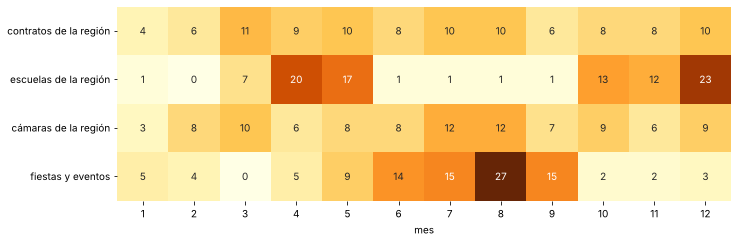

escuelas: abril y mayo 37 % | octubre a diciembre 48 %
fiestas y eventos: junio a septiembre 71 %


,1,2,3,4,5,6,7,8,9,10,11,12
contratos de la región,4,6,11,9,10,8,10,10,6,8,8,10
escuelas de la región,1,0,7,20,17,1,1,1,1,13,12,23
cámaras de la región,3,8,10,6,8,8,12,12,7,9,6,9
fiestas y eventos,5,4,0,5,9,14,15,27,15,2,2,3


In [46]:
def por_mes(meses):
    """% de cada mes, de 1 a 12, en una columna de meses."""
    conteo = []
    for mes in range(1, 13):
        conteo.append((meses == mes).sum())
    total = sum(conteo)
    return [round(n / total * 100) for n in conteo]


calendario = pd.DataFrame([por_mes(region_c["mes"]),
                           por_mes(region_c[region_c["tipo_comprador"] == "escuela"]["mes"]),
                           por_mes(region_c[region_c["tipo_comprador"] == "camara"]["mes"]),
                           por_mes(eventos["mes"])],
                          index=["contratos de la región", "escuelas de la región", "cámaras de la región", "fiestas y eventos"],
                          columns=range(1, 13))
print("contratos de escuelas de la región:", (region_c["tipo_comprador"] == "escuela").sum(), "| fiestas y eventos con mes:", len(eventos) - eventos["mes"].isna().sum())
fig, ax = plt.subplots(figsize=(11, 3.5))
sns.heatmap(calendario, annot=True, fmt="d", cmap="YlOrBr", cbar=False, ax=ax)
plt.xlabel("mes")
plt.ylabel("")
plt.show()

print("escuelas: abril y mayo", calendario.loc["escuelas de la región", [4, 5]].sum(), "% | octubre a diciembre", calendario.loc["escuelas de la región", [10, 11, 12]].sum(), "%")
print("fiestas y eventos: junio a septiembre", calendario.loc["fiestas y eventos", [6, 7, 8, 9]].sum(), "%")
calendario

**Qué saco.** Las escuelas de la región compran en abril y mayo (37 %) y de octubre a diciembre (48 %), y casi nada en verano. Las cámaras compran todo el año. Las fiestas se concentran de junio a septiembre (71 %).

**Para los datos y la presentación.** Para los datos: el mes es un filtro del dashboard. Para la presentación: el calendario: escuelas en marzo y septiembre, fiestas y asociaciones de marzo a mayo.

**Por qué lo hago.** Quiero en una sola tabla todo lo que la beira. necesita saber de cada entidad antes de contactarla.

**Por qué este código.** Para cada comprador saco el procedimiento más repetido (la misma técnica que el mes habitual: contar, ordenar y `drop_duplicates`; en caso de empate ordeno también por el nombre del procedimiento, para que el resultado no dependa del ordenador), el plazo mediano y los proveedores distintos, y lo uno a la lista con `merge`.

<sub>Lo que uso: `groupby` (semana 2), `agg`, `size`, `sum`, `mean`, `median`... (semana 2), `reset_index` (semana 2), `.columns =` (semana 2), `sort_values` / `sort_index` (semana 2), `drop_duplicates` (semana 2), `unique` / `nunique` (semana 2), `merge` (semana 2), `isin` (semana 2), `map` (semana 2), `shape` (semana 2), `value_counts` (semana 2), `head` (semana 2), `to_csv` (semana 4).</sub>

In [47]:
habitual = contratos.groupby(["comprador_nif", "procedimiento"]).size().reset_index()
habitual.columns = ["comprador_nif", "procedimiento_habitual", "veces"]
habitual = habitual.sort_values(["veces", "procedimiento_habitual"], ascending=[False, True]).drop_duplicates("comprador_nif")[["comprador_nif", "procedimiento_habitual"]]
plazo = contratos.groupby("comprador_nif")["prazoexecucao"].median().reset_index()
plazo.columns = ["comprador_nif", "plazo_mediano_dias"]
distintos = contratos.groupby("comprador_nif")["proveedor_id"].nunique().reset_index()
distintos.columns = ["comprador_nif", "proveedores_distintos"]

ampliada = lista_final.merge(habitual, on="comprador_nif", how="left").merge(plazo, on="comprador_nif", how="left").merge(distintos, on="comprador_nif", how="left")
ampliada["publica_concursos"] = ampliada["comprador_nif"].isin(anuncios["comprador_nif"]).map({True: "sí", False: "no"})
ampliada.to_csv(RESULTADOS + "lista_entidades_beira_ampliada.csv", index=False)
print(ampliada.shape)
print(ampliada["procedimiento_habitual"].value_counts())
# primeras filas de las tablas que crea esta celda
print("habitual:")
print(habitual.head())
print("plazo:")
print(plazo.head())
print("distintos:")
print(distintos.head())
ampliada[["comprador", "tipo_comprador", "municipio", "km_a_la_base", "grupo_compra", "mes_habitual", "procedimiento_habitual",
          "plazo_mediano_dias", "proveedores_distintos", "ya_compraba_2013_2015"]].head(15)

(63, 19)
procedimiento_habitual
ajuste directo     29
consulta previa    27
concurso            7
Name: count, dtype: int64
habitual:
      comprador_nif procedimiento_habitual
1098      600012662         ajuste directo
1089      600008878               concurso
1022      513606084                   otro
184       501442600         ajuste directo
336       503767549        consulta previa
plazo:
   comprador_nif  plazo_mediano_dias
0      500051054                15.0
1      500051062               362.0
2      500051070                30.0
3      500086826                 5.0
4      500122237                15.0
distintos:
   comprador_nif  proveedores_distintos
0      500051054                     24
1      500051062                     13
2      500051070                     47
3      500086826                      5
4      500122237                     15


,comprador,tipo_comprador,municipio,km_a_la_base,grupo_compra,mes_habitual,procedimiento_habitual,plazo_mediano_dias,proveedores_distintos,ya_compraba_2013_2015
0,Agrupamento de Escolas de Arganil,escuela,Arganil,22.0,A. fiel,4,ajuste directo,254.0,2,no
1,Município de Mortágua,camara,Mortágua,32.0,A. fiel,10,consulta previa,20.0,6,no
2,Universidade da Beira Interior,otro,Covilhã,32.0,A. fiel,3,ajuste directo,30.0,3,sí
3,"Centro Hospitalar Tondela-Viseu, E. P. E.",otro,Viseu,34.0,A. fiel,1,ajuste directo,90.0,4,no
4,Município de Viseu,camara,Viseu,34.0,A. fiel,7,ajuste directo,30.0,20,sí
5,Agrupamento de Escolas de Vila Nova de Poiares,escuela,Vila Nova de Poiares,37.0,A. fiel,12,ajuste directo,60.0,7,no
6,Associação Para a Recuperação de Cidadãos Inad...,otro,Lousã,42.0,A. fiel,3,consulta previa,365.0,2,no
7,Município da Lousã,camara,Lousã,42.0,A. fiel,8,consulta previa,60.0,5,sí
8,Município de Belmonte,camara,Belmonte,43.0,A. fiel,11,ajuste directo,10.0,4,no
9,Agrupamento de Escolas de Sátão,escuela,Sátão,44.0,A. fiel,12,ajuste directo,30.0,10,no


**Qué saco.** De las 63 entidades, 29 suelen comprar por ajuste directo, 27 por consulta previa y 7 por concurso. Cuando una entidad usa dos procedimientos el mismo número de veces, me quedo con el primero por orden alfabético, y lo mismo con el mes habitual (el más temprano): así la lista sale igual en cualquier ordenador.

**Para los datos y la presentación.** Para los datos: `resultados/lista_entidades_beira_ampliada.csv` es la tabla `lista_beira` de MySQL, de Tableau y de la app. Para la presentación: «a las de ajuste directo, visita antes de su mes; a las de consulta previa, pedir que nos inviten».

> **Resumo da secção (português).** Metade dos contratos é ajuste directo e 77 % são de menos de 20.000 €. No ajuste directo a entidade escolhe uma só empresa, por isso o que conta é ser conhecido antes da encomenda. O prazo não trava a PAISAN (chega a tempo em 86 % dos contratos da região). Ninguém domina o mercado e 59 % das compras repetidas vão para um fornecedor novo. 72 % dos compradores de 2013-2015 continuam a comprar. Os concursos são grandes demais para já. As escolas compram em Abril e Maio e de Outubro a Dezembro; as festas, de Junho a Setembro. Tudo fica na lista ampliada.

# 7. La PAISAN: H4, H5, H6, capacidad y modelo

La parte B mira dentro de la fábrica con sus facturas del e-fatura (2013-2026). Los datos son internos: los clientes van en código (C1 es el que más ha facturado) y no se enseña ningún NIF ni número de factura.

**Por qué lo hago.** H6 compara las facturas de la PAISAN con el salario mínimo. Antes quiero el contexto: cómo han cambiado desde 2011 el salario mínimo, que es el coste de la mano de obra, y el precio de la ropa.

**Por qué este código.** Junto las dos series por año y las paso a índice con 2011 = 100. Así las comparo en una sola escala, sin dos ejes, que confunden. `melt` las pone en formato largo para dibujarlas con `lineplot`, una línea por serie.

<sub>Lo que uso: filtro con una condición (semana 2), `merge` (semana 2), `loc` / `iloc` (semana 2), `melt` (semana 2), `map` (semana 2), `isin` (semana 2), `head` (semana 2), `plt.subplots`, `plt.xlabel`, `plt.show`... (semana 5), `sns.lineplot` (semana 5).</sub>

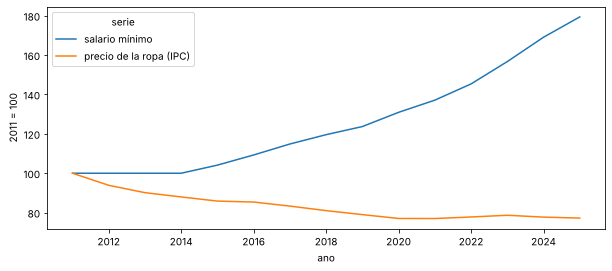

     ano  salario_2011  ropa_2011
0   2011         100.0      100.0
4   2015         104.0       86.0
9   2020         131.0       77.0
14  2025         179.0       77.0
ipc_ropa:
     ano   indice
30  2011  129.496
31  2012  121.563
32  2013  116.717
33  2014  113.908
34  2015  111.183
largo:
    ano           serie  indice_2011
0  2011  salario mínimo   100.000000
1  2012  salario mínimo   100.000000
2  2013  salario mínimo   100.000000
3  2014  salario mínimo   100.000000
4  2015  salario mínimo   104.123711
    ano  ...                                              nota
0  2011  ...                                               NaN
1  2012  ...                                               NaN
2  2013  ...                                               NaN
3  2014  ...  505 € a partir de outubro (Literacia Financeira)
4  2015  ...                                               NaN

[5 rows x 4 columns]
    ano  ... fecha_consulta
0  2011  ...     2026-11-04
1  2012  ...     2026-11-04

,ano,salario_minimo,fuente,nota,indice,salario_2011,ropa_2011
0,2011,485,https://www.pordata.pt/en/Portugal/National+mi...,NaN,129.496,100.000000,100.000000
1,2012,485,https://www.pordata.pt/en/Portugal/National+mi...,NaN,121.563,100.000000,93.873942
2,2013,485,https://www.pordata.pt/en/Portugal/National+mi...,NaN,116.717,100.000000,90.131742
3,2014,485,https://www.pordata.pt/en/Portugal/National+mi...,505 € a partir de outubro (Literacia Financeira),113.908,100.000000,87.962563
4,2015,505,https://www.pordata.pt/en/Portugal/National+mi...,NaN,111.183,104.123711,85.858250


In [48]:
salario = leer("salario_minimo")
ipc = leer("ipc_vestuario")
ipc_ropa = ipc[ipc["categoria"] == "prendas de vestir"][["ano", "indice"]]
precios = salario.merge(ipc_ropa, on="ano")
precios["salario_2011"] = precios["salario_minimo"] / precios["salario_minimo"].iloc[0] * 100
precios["ropa_2011"] = precios["indice"] / precios["indice"].iloc[0] * 100

largo = precios[["ano", "salario_2011", "ropa_2011"]].melt(id_vars="ano", var_name="serie", value_name="indice_2011")
largo["serie"] = largo["serie"].map({"salario_2011": "salario mínimo", "ropa_2011": "precio de la ropa (IPC)"})
fig, ax = plt.subplots(figsize=(10, 4))
sns.lineplot(data=largo, x="ano", y="indice_2011", hue="serie", ax=ax)
plt.ylabel("2011 = 100")
plt.show()
print(precios[precios["ano"].isin([2011, 2015, 2020, 2025])][["ano", "salario_2011", "ropa_2011"]].round(0))

# primeras filas de las tablas que crea esta celda
print("ipc_ropa:")
print(ipc_ropa.head())
print("largo:")
print(largo.head())
print(salario.head())
print(ipc.head())
precios.head()

**Qué saco.** De 2011 a 2025 el salario mínimo sube un 79 % y el precio de la ropa baja un 23 %.

**Para los datos y la presentación.** Para los datos: `indicadores_ano` en MySQL. Para la presentación: este gráfico abre la parte B: «cobrar lo mismo por pieza es ganar menos cada año».

**Por qué lo hago.** Las facturas vienen en catorce archivos, uno por año. Las quiero en una sola tabla.

**Por qué este código.** `glob` lista los archivos de la carpeta: si un día vuelvo a descargar 2020 y 2021 por partes, basta con dejarlos ahí. Leo todo como texto (`dtype=str`) porque los importes vienen como «1.215,24 €». El e-fatura separa con punto y coma y usa `utf-8-sig`. Enseño las primeras filas sin el número de factura ni el NIF.

<sub>Lo que uso: `for` (semana 1), `len`, `range`, `round`... (semana 1), `pd.read_csv` (semana 2), `pd.concat` (semana 2), `.columns =` (semana 2), `shape` (semana 2), `isna` / `duplicated` (semana 2), `agg`, `size`, `sum`, `mean`, `median`... (semana 2), `value_counts` (semana 2), `head` (semana 2), `glob.glob` (semana 4).</sub>

In [49]:
archivos = sorted(glob.glob(INTERNO + "efatura/*.csv"))
partes = []
for archivo in archivos:
    partes.append(pd.read_csv(archivo, sep=";", encoding="utf-8-sig", dtype=str))
facturas = pd.concat(partes, ignore_index=True)
facturas.columns = ["documento", "nif", "fecha", "tipo", "total", "iva", "base", "situacion"]
print(len(archivos), "archivos |", facturas.shape[0], "filas |", facturas.shape[1], "columnas | filas repetidas:", facturas.duplicated().sum())
print(facturas["tipo"].value_counts())
print(facturas["situacion"].value_counts())
print("facturas sin NIF:", facturas["nif"].isna().sum())
print(facturas[["fecha", "tipo", "total", "iva", "base", "situacion"]].head())

14 archivos | 3416 filas | 8 columnas | filas repetidas: 0
tipo
Fatura             3402
Nota de crédito      13
Fatura-recibo         1
Name: count, dtype: int64
situacion
Registado                          3280
Benefício não atribuído              95
Documento Anulado pelo Emitente      41
Name: count, dtype: int64
facturas sin NIF: 905
        fecha    tipo       total         iva        base  situacion
0  2013-11-08  Fatura    369,00 €     69,00 €    300,00 €  Registado
1  2013-06-10  Fatura  1.215,24 €    227,24 €    988,00 €  Registado
2  2013-06-08  Fatura  6.058,37 €  1.132,87 €  4.925,50 €  Registado
3  2013-04-15  Fatura  4.172,16 €    780,16 €  3.392,00 €  Registado
4  2013-12-13  Fatura    722,99 €    135,19 €    587,80 €  Registado


**Qué saco.** 3.416 facturas en 14 archivos, sin filas repetidas: 3.402 facturas, 13 notas de crédito y una factura-recibo. 41 están anuladas y 905 no tienen NIF.

**Para los datos y la presentación.** Para los datos: hay que pasar los importes a número y quitar las anuladas. Para la presentación: «3.416 facturas de 14 años».

**Por qué lo hago.** Quiero las facturas listas: importes en número, sin anuladas, con fecha, con el tipo de cliente y con los clientes en código.

**Por qué este código.** Defino dos funciones: `a_numero` pasa «1.215,24 €» a número y `tipo_cliente` mira el NIF. El primer número del NIF portugués dice qué tipo de entidad es, así que el tipo de cliente sale sin enseñar quién es. Las notas de crédito las pongo en negativo porque devuelven dinero. Doy a cada cliente un código (C1 el mayor) y quito de la tabla el número de factura y el NIF.

<sub>Lo que uso: `def` y `return` (semana 1), `lower`, `replace`, `split`, `join`, `strip`, `startswith`, `endswith` (semana 1), `if` / `else` (semana 1), `for` (semana 1), `lambda` (semana 1), comprensión de listas y diccionarios (semana 1), `len`, `range`, `round`... (semana 1), `apply` (semana 2), `drop_duplicates` (semana 2), filtro con una condición (semana 2), `copy` (semana 2), `loc` / `iloc` (semana 2), `pd.to_datetime` y `.dt.year` (semana 2), `dropna` / `fillna` (semana 2), `groupby` (semana 2), `agg`, `size`, `sum`, `mean`, `median`... (semana 2), `sort_values` / `sort_index` (semana 2), `reset_index` (semana 2), `merge` (semana 2), `drop` (semana 2), `head` (semana 2).</sub>

In [50]:
def a_numero(texto):
    """Pasa «1.215,24 €» a 1215.24."""
    return float(texto.replace("€", "").replace(".", "").replace(",", ".").strip())


def tipo_cliente(nif, iva):
    """Tipo de cliente por el NIF: el primer número dice si es una persona, una empresa o una entidad pública."""
    if nif == "" and iva == 0:
        return "extranjero"          # sin NIF portugués y sin IVA: exportación
    if nif == "":
        return "consumidor final"
    if nif[0] not in "0123456789" or nif.startswith("98"):
        return "extranjero"          # NIF de otro país o no residente
    if nif[0] in "123":
        return "persona física"
    if nif[0] == "5":
        return "empresa o asociación"
    if nif[0] == "6":
        return "entidad pública"
    return "otro"


for columna in ["total", "iva", "base"]:
    facturas[columna] = facturas[columna].apply(a_numero)
facturas = facturas.drop_duplicates()
facturas = facturas[facturas["situacion"] != "Documento Anulado pelo Emitente"].copy()
notas = facturas["tipo"] == "Nota de crédito"
facturas.loc[notas, "base"] = facturas.loc[notas, "base"] * -1
facturas["fecha"] = pd.to_datetime(facturas["fecha"])
facturas["ano"] = facturas["fecha"].dt.year
facturas["mes"] = facturas["fecha"].dt.month
facturas["nif"] = facturas["nif"].fillna("")
facturas["tipo_cliente"] = facturas.apply(lambda fila: tipo_cliente(fila["nif"], fila["iva"]), axis=1)
facturas["clave"] = facturas["nif"]
facturas.loc[facturas["nif"] == "", "clave"] = "sin NIF, " + facturas["tipo_cliente"]
facturas["sin_nif"] = facturas["nif"] == ""

por_cliente = facturas.groupby("clave")["base"].sum().sort_values(ascending=False).reset_index()
por_cliente["cliente"] = ["C" + str(i + 1) for i in range(len(por_cliente))]
facturas = facturas.merge(por_cliente[["clave", "cliente"]], on="clave").drop(columns=["documento", "nif", "clave"])
print(por_cliente[["cliente", "base"]].head())
print(facturas.groupby("ano")["fecha"].agg(["size", "min", "max"]))
revisar(facturas, "facturas")

  cliente        base
0      C1  1464295.82
1      C2  1397374.25
2      C3   666615.74
3      C4   495244.87
4      C5   400596.25
      size        min        max
ano                             
2013   165 2013-01-17 2013-12-31
2014   167 2014-01-16 2014-12-19
2015   204 2015-01-08 2015-12-28
2016   176 2016-01-21 2016-12-27
2017   243 2017-01-05 2017-12-26
2018   224 2018-01-04 2018-12-19
2019   260 2019-01-10 2019-12-31
2020   295 2020-05-14 2020-12-30
2021   294 2021-01-27 2021-12-30
2022   291 2022-01-12 2022-12-29
2023   255 2023-01-02 2023-12-22
2024   272 2024-01-03 2024-12-30
2025   279 2025-01-02 2025-12-29
2026   250 2026-01-02 2026-10-31
==== facturas ====
3375 filas y 11 columnas | filas duplicadas: 3
<class 'pandas.DataFrame'>
RangeIndex: 3375 entries, 0 to 3374
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   fecha         3375 non-null   datetime64[us]
 1   tipo          3375 non-

**Qué saco.** Quedan 3.375 facturas de 81 clientes, sin nulos. Cada año empieza en enero menos 2020 (14 de mayo) y 2021 (27 de enero): son los dos años cortados por el límite de descarga. C1 es la exportación sin NIF.

**Para los datos y la presentación.** Para los datos: las tablas `clientes_paisan` y `facturas_paisan` (internas). Para la presentación: «81 clientes en 14 años».

**Por qué lo hago.** Quiero ver el tamaño de la PAISAN año a año y a quién factura.

**Por qué este código.** Agrupo por año y por tipo de cliente con `agg`. Uso la base (sin IVA), que es lo que de verdad cobra la fábrica, y la factura mediana, porque unas pocas facturas muy grandes moverían la media. Los años incompletos están en `config.py`.

<sub>Lo que uso: `groupby` (semana 2), `agg`, `size`, `sum`, `mean`, `median`... (semana 2), `.columns =` (semana 2), `unique` / `nunique` (semana 2), `sort_values` / `sort_index` (semana 2).</sub>

In [51]:
por_ano = facturas.groupby("ano")["base"].agg(["size", "sum", "median"])
por_ano.columns = ["facturas", "facturacion", "factura_mediana"]
por_ano["clientes"] = facturas.groupby("ano")["cliente"].nunique()
por_tipo = facturas.groupby("tipo_cliente")["base"].agg(["size", "sum"])
por_tipo.columns = ["facturas", "facturacion"]
por_tipo["pct_facturacion"] = (por_tipo["facturacion"] / por_tipo["facturacion"].sum() * 100).round(0)
print(por_tipo.sort_values("facturacion", ascending=False))
print("clientes distintos de 2013 a 2026:", facturas["cliente"].nunique())
por_ano.round(0)

                      facturas  facturacion  pct_facturacion
tipo_cliente                                                
empresa o asociación      1392   2383735.42             46.0
extranjero                1237   2139041.31             41.0
persona física             738    674264.05             13.0
consumidor final             5      1875.00              0.0
otro                         3       655.00              0.0
clientes distintos de 2013 a 2026: 81


,facturas,facturacion,factura_mediana,clientes
ano,,,,
2013,165,231578.0,781.0,13
2014,167,240498.0,828.0,13
2015,204,323148.0,825.0,15
2016,176,254554.0,956.0,14
2017,243,339505.0,1012.0,12
2018,224,360470.0,1083.0,13
2019,260,383912.0,612.0,22
2020,295,333095.0,775.0,17
2021,294,317522.0,563.0,17


**Qué saco.** La PAISAN factura con pocos clientes: entre 12 y 22 al año. Pasa de 231.578 € en 2013 a 511.185 € en 2025, y en 2026 ya va por 538.750 € a finales de octubre. El 46 % se factura a empresas y asociaciones y el 41 % al extranjero.

**Para los datos y la presentación.** Para los datos: la vista `concentracion_paisan` de MySQL parte de aquí. Para la presentación: «la PAISAN casi ha doblado su facturación desde 2013».

**Por qué lo hago.** H4: quiero medir cuánto pesan los tres mayores clientes de cada año y comprobar si pasan del 80 %.

**Por qué este código.** Para cada año ordeno los clientes y me quedo con los tres primeros con `head(3)`. La prueba es la t de una muestra (semana 5), que compara una media con un valor fijo: H0, el peso medio es del 80 % o menos; H1, es mayor (`alternative="greater"`). El 80 % es el umbral de la regla 80/20.

<sub>Lo que uso: `len`, `range`, `round`... (semana 1), `groupby` (semana 2), `agg`, `size`, `sum`, `mean`, `median`... (semana 2), `reset_index` (semana 2), `sort_values` / `sort_index` (semana 2), `head` (semana 2), `pd.DataFrame` / `pd.Series` (semana 2), `isin` (semana 2), `stats.ttest_1samp` (`alternative`) (semana 5).</sub>

In [52]:
cliente_ano = facturas.groupby(["ano", "cliente"])["base"].sum().reset_index()
cliente_ano = cliente_ano.sort_values(["ano", "base"], ascending=[True, False])
tres = cliente_ano.groupby("ano").head(3).groupby("ano")["base"].sum()
concentracion = pd.DataFrame({"facturacion": cliente_ano.groupby("ano")["base"].sum(), "tres_mayores": tres})
concentracion["pct_tres_mayores"] = (concentracion["tres_mayores"] / concentracion["facturacion"] * 100).round(0)
completos = concentracion[concentracion.index.isin(ANOS_INCOMPLETOS) == False]
t, p = stats.ttest_1samp(completos["pct_tres_mayores"], OBJETIVO_TRES_MAYORES * 100, alternative="greater")
print("peso medio de los tres mayores:", round(completos["pct_tres_mayores"].mean(), 1), "% | t =", round(t, 2), "| p =", round(p, 4), "|", len(completos), "años")
# primeras filas de las tablas que crea esta celda
print("cliente_ano:")
print(cliente_ano.head())
print("completos:")
print(completos.head())
concentracion.round(0)

peso medio de los tres mayores: 86.6 % | t = 3.93 | p = 0.0012 | 12 años
cliente_ano:
    ano cliente       base
0  2013      C1  185441.94
2  2013     C17   10123.76
7  2013     C22    9305.50
5  2013      C2    7065.00
4  2013     C19    4887.00
completos:
      facturacion  tres_mayores  pct_tres_mayores
ano                                              
2013    231577.80     204871.20              88.0
2014    240497.87     216432.62              90.0
2015    323147.92     294550.37              91.0
2016    254554.29     217781.89              86.0
2017    339504.55     288792.60              85.0


,facturacion,tres_mayores,pct_tres_mayores
ano,,,
2013,231578.0,204871.0,88.0
2014,240498.0,216433.0,90.0
2015,323148.0,294550.0,91.0
2016,254554.0,217782.0,86.0
2017,339505.0,288793.0,85.0
2018,360470.0,291339.0,81.0
2019,383912.0,347484.0,91.0
2020,333095.0,233666.0,70.0
2021,317522.0,285749.0,90.0


**Qué saco.** H4 se cumple: en los años completos, los tres mayores clientes suman de media el 86,6 % de la facturación (t = 3,93; p = 0,001). En 2024 y 2025 llegan al 92 % y al 93 %.

**Para los datos y la presentación.** Para los datos: lo repito en SQL con una vista y `ROW_NUMBER` (sección 9). Para la presentación: es el punto de partida de todo el proyecto: «si se va un cliente, se va un tercio del año».

**Por qué lo hago.** H5: quiero saber si los clientes de la PAISAN repiten como los compradores públicos.

**Por qué este código.** Es la misma prueba que H1 para poder comparar las dos. Uso solo clientes con NIF (la exportación sin NIF puede juntar varios clientes) y solo pares de años completos.

<sub>Lo que uso: `for` (semana 1), `lambda` (semana 1), `len`, `range`, `round`... (semana 1), filtro con una condición (semana 2), `drop_duplicates` (semana 2), `groupby` (semana 2), `agg`, `size`, `sum`, `mean`, `median`... (semana 2), `loc` / `iloc` (semana 2), `.columns =` (semana 2), `pd.concat` (semana 2), `reset_index` (semana 2), `apply` (semana 2), `head` (semana 2), `pd.crosstab` (semana 5), `chi2_contingency` (semana 5), `association` (semana 5).</sub>

In [53]:
compras_p = facturas[facturas["sin_nif"] == False][["cliente", "ano"]].drop_duplicates()
matriz_p = pd.crosstab(compras_p["cliente"], compras_p["ano"])
primer_ano_p = compras_p.groupby("cliente")["ano"].min()
partes = []
for ano in [2013, 2014, 2015, 2016, 2017, 2018, 2022, 2023, 2024]:
    trozo = matriz_p.loc[primer_ano_p[primer_ano_p <= ano].index, [ano, ano + 1]]
    trozo.columns = ["compra_este_ano", "compra_el_siguiente"]
    partes.append(trozo)
pares_p = pd.concat(partes).reset_index(drop=True)
tabla = pd.crosstab(pares_p["compra_este_ano"], pares_p["compra_el_siguiente"])
print(tabla.apply(lambda fila: fila / fila.sum() * 100, axis=1).round(0))
chi2, p, gl, esperado = stats.chi2_contingency(tabla)
print(len(pares_p), "pares cliente-año | chi2 =", round(chi2, 1), "| p =", round(p, 4), "| V de Cramér =", round(association(tabla, method="cramer"), 2))
# primeras filas de las tablas que crea esta celda
print("compras_p:")
print(compras_p.head())
print("matriz_p:")
print(matriz_p.head())
print("pares_p:")
print(pares_p.head())
tabla

compra_el_siguiente     0     1
compra_este_ano                
0                    96.0   4.0
1                    33.0  67.0
302 pares cliente-año | chi2 = 134.1 | p = 0.0 | V de Cramér = 0.67
compras_p:
   cliente   ano
0      C67  2013
1      C22  2013
4      C17  2013
15     C19  2013
18     C51  2013
matriz_p:
ano      2013  2014  2015  2016  2017  2018  ...  2021  2022  2023  2024  2025  2026
cliente                                      ...                                    
C10         0     0     0     0     0     0  ...     1     1     0     0     0     0
C11         0     0     0     0     0     0  ...     1     0     0     0     1     1
C12         1     1     1     1     1     1  ...     0     0     0     0     0     0
C13         0     0     0     0     0     0  ...     0     0     0     0     0     1
C14         0     1     1     1     1     1  ...     1     1     1     1     0     0

[5 rows x 14 columns]
pares_p:
   compra_este_ano  compra_el_siguiente
0             

compra_el_siguiente,0,1
compra_este_ano,,
0,169,7
1,42,84


**Qué saco.** H5 se cumple, y con más fuerza que H1: el 67 % de los clientes que compran un año vuelve al siguiente, frente al 4 % de los que no compraron (302 pares; V = 0,67).

**Para los datos y la presentación.** Para los datos: también en SQL con `LEAD`. Para la presentación: «un cliente que se va casi nunca vuelve: cuidar al que está vale más».

**Por qué lo hago.** H6: quiero comparar el crecimiento de la PAISAN con el del salario mínimo y probar si una factura vale hoy menos salarios mínimos que hace diez años.

**Por qué este código.** Divido cada factura por el salario mínimo de su año: así quito el efecto de la subida de sueldos. Comparo 2013-2015 con 2023-2025 con la t de Welch sobre el logaritmo, porque las facturas tienen una cola larga y los dos grupos no tienen la misma varianza.

<sub>Lo que uso: `for` (semana 1), `len`, `range`, `round`... (semana 1), `isin` (semana 2), `reset_index` (semana 2), `merge` (semana 2), filtro con una condición (semana 2), `loc` / `iloc` (semana 2), `melt` (semana 2), `map` (semana 2), `agg`, `size`, `sum`, `mean`, `median`... (semana 2), `head` (semana 2), `plt.subplots`, `plt.xlabel`, `plt.show`... (semana 5), `sns.lineplot` (semana 5), `stats.ttest_ind` (`equal_var=False`) (semana 5), `np.log1p` (semana 5).</sub>

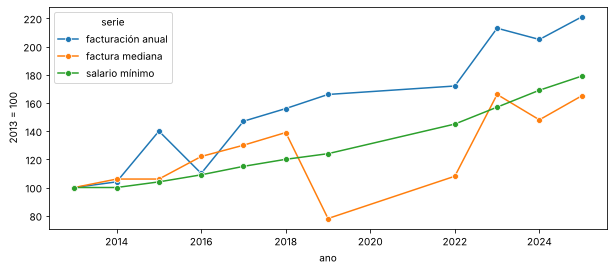

     ano  facturacion_2013  factura_mediana_2013  salario_minimo_2013
0   2013             100.0                 100.0                100.0
6   2019             166.0                  78.0                124.0
10  2025             221.0                 165.0                179.0
factura mediana en salarios mínimos: 2013-2015 = 1.67 | 2023-2025 = 1.55
Welch sobre log(1 + factura en salarios mínimos) | t = -4.17 | p = 0.0
largo_b:
    ano              serie  indice_2013
0  2013  facturación anual        100.0
1  2014  facturación anual        104.0
2  2015  facturación anual        140.0
3  2016  facturación anual        110.0
4  2017  facturación anual        147.0
salarios:
       fecha    tipo    total  ...  cliente  salario_minimo en_salarios
0 2013-11-08  Fatura   369.00  ...      C67             485    0.618557
1 2013-06-10  Fatura  1215.24  ...      C22             485    2.037113
2 2013-06-08  Fatura  6058.37  ...      C22             485   10.155670
3 2013-04-15  Fatura  4172.16

In [54]:
anual = por_ano[por_ano.index.isin(ANOS_INCOMPLETOS) == False].reset_index().merge(salario[["ano", "salario_minimo"]], on="ano")
anual = anual[anual["ano"] <= 2025]
base_2013 = anual[anual["ano"] == 2013].iloc[0]
for columna in ["facturacion", "factura_mediana", "salario_minimo"]:
    anual[columna + "_2013"] = (anual[columna] / base_2013[columna] * 100).round(0)
largo_b = anual[["ano", "facturacion_2013", "factura_mediana_2013", "salario_minimo_2013"]].melt(id_vars="ano", var_name="serie", value_name="indice_2013")
largo_b["serie"] = largo_b["serie"].map({"facturacion_2013": "facturación anual", "factura_mediana_2013": "factura mediana", "salario_minimo_2013": "salario mínimo"})
fig, ax = plt.subplots(figsize=(10, 4))
sns.lineplot(data=largo_b, x="ano", y="indice_2013", hue="serie", marker="o", ax=ax)
plt.ylabel("2013 = 100")
plt.show()
print(anual[anual["ano"].isin([2013, 2019, 2025])][["ano", "facturacion_2013", "factura_mediana_2013", "salario_minimo_2013"]])

salarios = facturas.merge(salario[["ano", "salario_minimo"]], on="ano")
salarios = salarios[(salarios["base"] > 0) & (salarios["ano"] <= 2025)]
salarios["en_salarios"] = salarios["base"] / salarios["salario_minimo"]
antes = salarios[salarios["ano"].isin([2013, 2014, 2015])]["en_salarios"]
ahora = salarios[salarios["ano"].isin([2023, 2024, 2025])]["en_salarios"]
print("factura mediana en salarios mínimos: 2013-2015 =", round(antes.median(), 2), "| 2023-2025 =", round(ahora.median(), 2))
t, p = stats.ttest_ind(np.log1p(ahora), np.log1p(antes), equal_var=False)
print("Welch sobre log(1 + factura en salarios mínimos) | t =", round(t, 2), "| p =", round(p, 4))

# primeras filas de las tablas que crea esta celda
print("largo_b:")
print(largo_b.head())
print("salarios:")
print(salarios.head())

**Qué saco.** H6 se cumple: de 2013 a 2025 el salario mínimo sube un 79 % y la factura mediana un 65 %. En salarios mínimos, la factura mediana baja de 1,67 a 1,55 (Welch, t = −4,17; p < 0,001). La PAISAN crece porque factura más (+121 %), no porque cada pedido pague más trabajo.

**Para los datos y la presentación.** Para los datos: nada nuevo. Para la presentación: «la fábrica crece en volumen, no en precio». Con cuidado: una factura no es una pieza.

**Por qué lo hago.** Quiero unir la parte B con la A: ¿cuántos clientes de la PAISAN venden ropa al Estado?

**Por qué este código.** El NIF es la clave común entre las facturas y el Portal BASE: busco el NIF de cada cliente entre los proveedores de los contratos con `isin`. Solo enseño totales, para no decir quiénes son.

<sub>Lo que uso: `len`, `range`, `round`... (semana 1), `astype` (semana 2), `unique` / `nunique` (semana 2), `dropna` / `fillna` (semana 2), `isin` (semana 2), `agg`, `size`, `sum`, `mean`, `median`... (semana 2), `merge` (semana 2), `head` (semana 2), `groupby` (semana 2), `.columns =` (semana 2).</sub>

In [55]:
nif_compradores = contratos["comprador_nif"].astype(str).unique()
nif_proveedores = contratos["proveedor_nif"].dropna().astype(int).astype(str).unique()
por_cliente["compra_al_estado"] = por_cliente["clave"].isin(nif_compradores)
por_cliente["vende_al_estado"] = por_cliente["clave"].isin(nif_proveedores)
vende = por_cliente[por_cliente["vende_al_estado"]]
print("clientes de la PAISAN que compran ropa al Estado:", por_cliente["compra_al_estado"].sum())
print("clientes de la PAISAN que venden ropa al Estado:", len(vende), "de", len(por_cliente), "| su parte de la facturación de la PAISAN:", round(vende["base"].sum() / por_cliente["base"].sum() * 100), "%")
print(vende[["cliente", "base", "compra_al_estado", "vende_al_estado"]].round(0))

sus_contratos = contratos[contratos["proveedor_nif"].fillna(0).astype(int).astype(str).isin(vende["clave"])]
sus_contratos = sus_contratos.merge(compradores[["comprador_nif", "concelho"]], on="comprador_nif")
print("sus contratos públicos 2020-2025:", len(sus_contratos), "| gasto:", round(sus_contratos["precio"].sum()), "€ | precio mediano:", round(sus_contratos["precio"].median()), "€")
print("de ropa o fardamento:", (sus_contratos["ropa_fardamento"] == "sí").sum(), "| con compradores de la región:", (sus_contratos["concelho"] != "").sum(),
      "| con entidades de la lista:", sus_contratos["comprador_nif"].isin(lista_final["comprador_nif"]).sum())
print(sus_contratos[["ano", "tipo_comprador", "producto", "precio", "ropa_fardamento"]].head())
intermediarios = sus_contratos.groupby("tipo_comprador")["precio"].agg(["size", "sum", "median"]).round(0)
intermediarios.columns = ["contratos", "gasto", "precio_mediano"]
intermediarios

clientes de la PAISAN que compran ropa al Estado: 1
clientes de la PAISAN que venden ropa al Estado: 9 de 81 | su parte de la facturación de la PAISAN: 13 %
   cliente      base  compra_al_estado  vende_al_estado
3       C4  495245.0             False             True
8       C9   49319.0             False             True
9      C10   48438.0             False             True
10     C11   45548.0             False             True
20     C21   10452.0             False             True
24     C25    7905.0             False             True
27     C28    6452.0             False             True
28     C29    6142.0             False             True
48     C49    1606.0             False             True
sus contratos públicos 2020-2025: 61 | gasto: 3082993 € | precio mediano: 24824 €
de ropa o fardamento: 46 | con compradores de la región: 5 | con entidades de la lista: 4
    ano tipo_comprador         producto   precio ropa_fardamento
0  2020           otro        otra ropa  84304

,contratos,gasto,precio_mediano
tipo_comprador,,,
camara,7,120557.0,13545.0
escuela,4,4472.0,907.0
otro,50,2957964.0,36831.0


**Qué saco.** 9 de los 81 clientes venden ropa al Estado y suman el 13 % de la facturación. Entre 2020 y 2025 firmaron 61 contratos públicos por 3,08 millones; 4 con entidades de la lista de la beira.

**Para los datos y la presentación.** Para los datos: columna `vende_al_estado` de `clientes_paisan`. Para la presentación: «la PAISAN ya trabaja para el mercado público, pero por detrás de otra empresa».

**Por qué lo hago.** Quiero estimar cuánta facturación más cabe en la fábrica y en qué meses hay más sitio.

**Por qué este código.** No hay registro de piezas producidas, así que uso la facturación: el mejor mes de los últimos doce es una capacidad que la fábrica ya demostró, y el `hueco` de cada mes es lo que le falta para llegar a él. `periodo` (año × 12 + mes) me deja quedarme con los últimos doce meses sin funciones de fecha que no se dieron.

<sub>Lo que uso: `len`, `range`, `round`... (semana 1), `groupby` (semana 2), `agg`, `size`, `sum`, `mean`, `median`... (semana 2), `reset_index` (semana 2), `.columns =` (semana 2), filtro con una condición (semana 2), `copy` (semana 2), `isin` (semana 2), `sort_values` / `sort_index` (semana 2), `head` (semana 2), `plt.subplots`, `plt.xlabel`, `plt.show`... (semana 5), `sns.barplot` (semana 5).</sub>

últimos 12 meses | facturación: 606355 € | mes mediano: 53023 € | mejor mes: 66721 € | peor mes: 29502 €
hueco hasta el mejor mes, sumado en el año: 194302 €


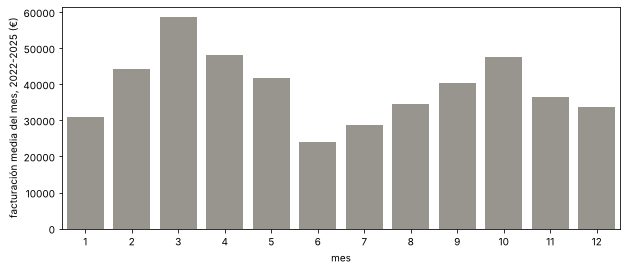

    mes  facturacion
5     6      23875.0
6     7      28826.0
0     1      31006.0
11   12      33595.0
7     8      34533.0
mes_a_mes:
    ano  mes  facturacion  facturas_mes  periodo
0  2013    1      2642.00             7    24157
1  2013    2      5699.09             6    24158
2  2013    3      9127.66             8    24159
3  2013    4     20060.73            13    24160
4  2013    5     26720.84            17    24161


,ano,mes,facturacion,facturas_mes,hueco
150,2025,11,29502.0,17,37219.0
151,2025,12,38103.0,19,28619.0
152,2026,1,61737.0,26,4985.0
153,2026,2,58689.0,23,8032.0
154,2026,3,64428.0,28,2293.0
155,2026,4,66721.0,31,0.0
156,2026,5,41933.0,25,24788.0
157,2026,6,50640.0,24,16081.0
158,2026,7,42221.0,23,24501.0
159,2026,8,39482.0,23,27240.0


In [56]:
mes_a_mes = facturas.groupby(["ano", "mes"])["base"].agg(["sum", "size"]).reset_index()
mes_a_mes.columns = ["ano", "mes", "facturacion", "facturas_mes"]
mes_a_mes["periodo"] = mes_a_mes["ano"] * 12 + mes_a_mes["mes"]
ultimo = mes_a_mes["periodo"].max()
doce = mes_a_mes[mes_a_mes["periodo"] > ultimo - 12].copy()
mejor_mes = doce["facturacion"].max()
doce["hueco"] = mejor_mes - doce["facturacion"]
print("últimos 12 meses | facturación:", round(doce["facturacion"].sum()), "€ | mes mediano:", round(doce["facturacion"].median()), "€ | mejor mes:", round(mejor_mes), "€ | peor mes:", round(doce["facturacion"].min()), "€")
print("hueco hasta el mejor mes, sumado en el año:", round(doce["hueco"].sum()), "€")

estacion = mes_a_mes[mes_a_mes["ano"].isin([2022, 2023, 2024, 2025])].groupby("mes")["facturacion"].mean().round(0).reset_index()
fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(data=estacion, x="mes", y="facturacion", color=COLORES["gris"], ax=ax)
plt.ylabel("facturación media del mes, 2022-2025 (€)")
plt.show()
print(estacion.sort_values("facturacion").head())
# primeras filas de las tablas que crea esta celda
print("mes_a_mes:")
print(mes_a_mes.head())
doce[["ano", "mes", "facturacion", "facturas_mes", "hueco"]].round(0)

**Qué saco.** En los últimos doce meses (noviembre de 2025 a octubre de 2026) la PAISAN facturó 606.355 €, con un mes mediano de 53.023 €. El mejor mes fue abril de 2026 (66.721 €). Si todos los meses llegaran ahí, cabrían 194.302 € más al año. Los meses con más sitio son junio y julio.

**Para los datos y la presentación.** Para los datos: lo repito en SQL con `MAX() OVER ()`. Para la presentación: «cabe casi 200.000 € más, sobre todo en verano». Límite: mido euros, no piezas.

**Por qué lo hago.** Quiero poner un número al objetivo de la beira.: cuánto tendría que facturar para que los tres mayores bajen al 80 %.

**Por qué este código.** Es una cuenta y no una previsión: despejo las ventas que hacen falta (tres mayores / 0,80 − facturación) con los datos de 2025, el último año completo. Supone que las ventas de la beira. se facturan en la PAISAN y que los tres mayores siguen comprando lo mismo. El 0,80 viene de `config.py`.

<sub>Lo que uso: `len`, `range`, `round`... (semana 1), `loc` / `iloc` (semana 2), `agg`, `size`, `sum`, `mean`, `median`... (semana 2), `pd.DataFrame` / `pd.Series` (semana 2).</sub>

In [57]:
tres_2025 = concentracion.loc[2025, "tres_mayores"]
total_2025 = concentracion.loc[2025, "facturacion"]
necesario = tres_2025 / OBJETIVO_TRES_MAYORES - total_2025
print("para que los tres mayores bajen al 80 %, la beira. tendría que facturar", round(necesario), "€ al año")
print("hueco de la fábrica en los últimos 12 meses:", round(doce["hueco"].sum()), "€")

escenarios = pd.DataFrame({"ventas_beira": [10000, 25000, 50000, 83000, 100000]})
escenarios["pct_tres_mayores"] = (tres_2025 / (total_2025 + escenarios["ventas_beira"]) * 100).round(1)
escenarios

para que los tres mayores bajen al 80 %, la beira. tendría que facturar 82787 € al año
hueco de la fábrica en los últimos 12 meses: 194302 €


,ventas_beira,pct_tres_mayores
0,10000,91.2
1,25000,88.6
2,50000,84.7
3,83000,80.0
4,100000,77.7


**Qué saco.** En 2025 los tres mayores sumaron 475.177 € de 511.185 € (93 %). Para bajar al 80 % la beira. tendría que facturar unos 82.800 € al año, cerca de 6.900 € al mes. Cabe en el hueco de 194.302 €. Con 25.000 € al año el peso baja al 88,6 % y con 50.000 € al 84,7 %.

**Para los datos y la presentación.** Para los datos: es el objetivo con el que la app compara los pedidos de la beira. Para la presentación: es el número final: «unos 83.000 € al año, muchos pedidos pequeños, sobre todo en junio y julio».

## Modelo: ¿se puede prever la facturación del mes siguiente?

El Case Study 2 no pide machine learning, pero me interesa saber si se puede planificar la fábrica con un mes de antelación. Uso solo lo que se dio en la semana 7: regresión lineal, KNN, árbol, random forest y gradient boosting, con `MinMaxScaler` y las métricas MAE, RMSE y R².

**Por qué lo hago.** Para el modelo necesito una fila por mes: la facturación del mes (lo que quiero prever) y datos del pasado (lo que sé el día 1).

**Por qué este código.** Con `periodo` voy al mes anterior (periodo − 1) y al mismo mes del año anterior (periodo − 12) con dos `merge`; uso `merge` en lugar de `shift` porque `shift` no se dio en clase. Quito los meses incompletos de la descarga y los que los usan como pasado.

<sub>Lo que uso: `groupby` (semana 2), `agg`, `size`, `sum`, `mean`, `median`... (semana 2), `reset_index` (semana 2), `.columns =` (semana 2), `unique` / `nunique` (semana 2), `merge` (semana 2), `copy` (semana 2), `isin` (semana 2), `shape` (semana 2), `head` (semana 2), `corrwith` (semana 5).</sub>

In [58]:
mensual = facturas.groupby(["ano", "mes"])["base"].agg(["sum", "size"]).reset_index()
mensual.columns = ["ano", "mes", "facturacion", "facturas_mes"]
clientes_mes = facturas.groupby(["ano", "mes"])["cliente"].nunique().reset_index()
clientes_mes.columns = ["ano", "mes", "clientes_mes"]
mensual = mensual.merge(clientes_mes, on=["ano", "mes"])
mensual["periodo"] = mensual["ano"] * 12 + mensual["mes"]
anterior = mensual[["periodo", "facturacion", "clientes_mes"]].copy()
anterior["periodo"] = anterior["periodo"] + 1
anterior.columns = ["periodo", "facturacion_mes_anterior", "clientes_mes_anterior"]
hace_un_ano = mensual[["periodo", "facturacion"]].copy()
hace_un_ano["periodo"] = hace_un_ano["periodo"] + 12
hace_un_ano.columns = ["periodo", "facturacion_hace_un_ano"]
mensual = mensual.merge(anterior, on="periodo").merge(hace_un_ano, on="periodo")

afectado = mensual["periodo"].isin(MESES_INCOMPLETOS) | (mensual["periodo"] - 1).isin(MESES_INCOMPLETOS) | (mensual["periodo"] - 12).isin(MESES_INCOMPLETOS)
mensual = mensual[afectado == False]
print(mensual.shape)
print(mensual[["facturacion", "facturacion_mes_anterior", "facturacion_hace_un_ano", "clientes_mes_anterior"]].corrwith(mensual["facturacion"]).round(2))
# primeras filas de las tablas que crea esta celda
print("clientes_mes:")
print(clientes_mes.head())
print("anterior:")
print(anterior.head())
print("hace_un_ano:")
print(hace_un_ano.head())
mensual.head()

(142, 9)
facturacion                 1.00
facturacion_mes_anterior    0.48
facturacion_hace_un_ano     0.49
clientes_mes_anterior       0.04
dtype: float64
clientes_mes:
    ano  mes  clientes_mes
0  2013    1             3
1  2013    2             4
2  2013    3             3
3  2013    4             5
4  2013    5             7
anterior:
   periodo  facturacion_mes_anterior  clientes_mes_anterior
0    24158                   2642.00                      3
1    24159                   5699.09                      4
2    24160                   9127.66                      3
3    24161                  20060.73                      5
4    24162                  26720.84                      7
hace_un_ano:
   periodo  facturacion_hace_un_ano
0    24169                  2642.00
1    24170                  5699.09
2    24171                  9127.66
3    24172                 20060.73
4    24173                 26720.84


,ano,mes,facturacion,facturas_mes,clientes_mes,periodo,facturacion_mes_anterior,clientes_mes_anterior,facturacion_hace_un_ano
0,2014,1,11442.81,10,6,24169,23323.42,7,2642.00
1,2014,2,3337.78,7,2,24170,11442.81,6,5699.09
2,2014,3,17014.78,13,3,24171,3337.78,2,9127.66
3,2014,4,16026.57,11,5,24172,17014.78,3,20060.73
4,2014,5,27243.77,15,4,24173,16026.57,5,26720.84


**Qué saco.** Quedan 142 meses. La facturación de un mes se parece algo a la del mes anterior (r = 0,48) y a la del mismo mes del año anterior (r = 0,49).

**Para los datos y la presentación.** Para los datos: tabla de trabajo, no se guarda. Para la presentación: no.

**Por qué lo hago.** Quiero saber si un modelo gana a las reglas simples que usaría cualquiera: «igual que el mes anterior», «igual que hace un año» o «la media».

**Por qué este código.** Separo por tiempo (entreno hasta 2023 y pruebo con 2024-2026), porque si separara al azar el modelo vería el futuro. Escalo con `MinMaxScaler` aprendiendo solo del entrenamiento. Pruebo los cinco modelos de clase con poca profundidad, porque hay pocos meses, y mido MAE, RMSE y R².

<sub>Lo que uso: `len`, `range`, `round`... (semana 1), `for` (semana 1), `loc` / `iloc` (semana 2), `shape` (semana 2), `pd.DataFrame` / `pd.Series` (semana 2), `agg`, `size`, `sum`, `mean`, `median`... (semana 2), `sort_values` / `sort_index` (semana 2), `head` (semana 2), `np.sqrt` (semana 5), `MinMaxScaler` (`fit` y `transform`) (semana 7), `LinearRegression` (semana 7), `KNeighborsRegressor` (semana 7), `DecisionTree` (semana 7), `RandomForest` (semana 7), `GradientBoosting` (semana 7), `mean_absolute_error`, `mean_squared_error`, `r2_score` (semana 7), `fit` y `predict` (semana 7), `feature_importances_` (semana 7).</sub>

In [59]:
VARIABLES_B = ["mes", "ano", "facturacion_mes_anterior", "facturacion_hace_un_ano", "clientes_mes_anterior"]
entreno_b = mensual["ano"] <= 2023
test_b = mensual["ano"] >= 2024
X_b_train = mensual.loc[entreno_b, VARIABLES_B]
X_b_test = mensual.loc[test_b, VARIABLES_B]
y_b_train = mensual.loc[entreno_b, "facturacion"]
y_b_test = mensual.loc[test_b, "facturacion"]
print("entrenamiento:", X_b_train.shape, "| test:", X_b_test.shape)

escalador_b = MinMaxScaler()
escalador_b.fit(X_b_train)
X_b_train_norm = pd.DataFrame(escalador_b.transform(X_b_train), columns=VARIABLES_B)
X_b_test_norm = pd.DataFrame(escalador_b.transform(X_b_test), columns=VARIABLES_B)

modelos_b = {"regresión lineal": LinearRegression(),
             "KNN": KNeighborsRegressor(n_neighbors=10),
             "árbol de decisión": DecisionTreeRegressor(max_depth=3, random_state=SEMILLA),
             "random forest": RandomForestRegressor(n_estimators=300, max_depth=4, random_state=SEMILLA),
             "gradient boosting": GradientBoostingRegressor(n_estimators=200, max_depth=2, learning_rate=0.05, random_state=SEMILLA)}
referencias = {"igual que el mes anterior": X_b_test["facturacion_mes_anterior"],
               "igual que hace un año": X_b_test["facturacion_hace_un_ano"],
               "media del entrenamiento": [y_b_train.mean()] * len(y_b_test)}
errores = []
for nombre in referencias:
    errores.append({"modelo": nombre, "MAE (€)": round(mean_absolute_error(y_b_test, referencias[nombre])),
                    "RMSE (€)": round(np.sqrt(mean_squared_error(y_b_test, referencias[nombre]))), "R²": round(r2_score(y_b_test, referencias[nombre]), 2)})
for nombre in modelos_b:
    modelos_b[nombre].fit(X_b_train_norm, y_b_train)
    prediccion_b = modelos_b[nombre].predict(X_b_test_norm)
    errores.append({"modelo": nombre, "MAE (€)": round(mean_absolute_error(y_b_test, prediccion_b)),
                    "RMSE (€)": round(np.sqrt(mean_squared_error(y_b_test, prediccion_b))), "R²": round(r2_score(y_b_test, prediccion_b), 2)})
print("facturación mensual mediana del test:", round(y_b_test.median()), "€")
print("peso de cada variable en el gradient boosting:")
print(pd.Series(modelos_b["gradient boosting"].feature_importances_, index=VARIABLES_B).round(2).sort_values(ascending=False))
# primeras filas de las tablas que crea esta celda
print("X_b_train:")
print(X_b_train.head())
print("X_b_test:")
print(X_b_test.head())
print("X_b_train_norm:")
print(X_b_train_norm.head())
print("X_b_test_norm:")
print(X_b_test_norm.head())
pd.DataFrame(errores).sort_values("MAE (€)")

entrenamiento: (108, 5) | test: (34, 5)
facturación mensual mediana del test: 42437 €
peso de cada variable en el gradient boosting:
ano                         0.38
facturacion_hace_un_ano     0.23
mes                         0.18
facturacion_mes_anterior    0.14
clientes_mes_anterior       0.07
dtype: float64
X_b_train:
   mes   ano  ...  facturacion_hace_un_ano  clientes_mes_anterior
0    1  2014  ...                  2642.00                      7
1    2  2014  ...                  5699.09                      6
2    3  2014  ...                  9127.66                      2
3    4  2014  ...                 20060.73                      3
4    5  2014  ...                 26720.84                      5

[5 rows x 5 columns]
X_b_test:
     mes   ano  ...  facturacion_hace_un_ano  clientes_mes_anterior
111    1  2024  ...                 35023.73                      6
112    2  2024  ...                 46887.48                      7
113    3  2024  ...                 77137.53

,modelo,MAE (€),RMSE (€),R²
7,gradient boosting,9400,12042,0.29
6,random forest,9941,12331,0.26
5,árbol de decisión,10440,13276,0.14
3,regresión lineal,11179,13534,0.10
4,KNN,12326,15413,-0.16
1,igual que hace un año,12900,16434,-0.32
0,igual que el mes anterior,13791,17037,-0.42
2,media del entrenamiento,16941,20500,-1.06


**Qué saco.** El gradient boosting es el mejor: falla de media 9.400 € al mes, frente a 12.900 € de la mejor regla simple, y explica el 29 % de la variación (R² = 0,29). Lo que más pesa es el año (el crecimiento) y la facturación de hace un año. En un mes típico de 42.437 € el error sigue siendo de uno de cada cinco euros.

**Para los datos y la presentación.** Para los datos: no se guarda. Para la presentación: una frase: «sirve para planificar con margen, no para fijar una cifra».

**Por qué lo hago.** Mientras no tenga el precio por pieza de la PAISAN, quiero una referencia de mercado.

**Por qué este código.** Leo los precios públicos de personalización y el coste publicado de la ISTO., y calculo cuántas veces el precio multiplica el coste. Son datos pequeños: un `groupby` basta.

<sub>Lo que uso: `head` (semana 2), `groupby` (semana 2), `agg`, `size`, `sum`, `mean`, `median`... (semana 2).</sub>

In [60]:
mercado = leer("precios_personalizacion")
print(mercado[["fuente", "prenda", "detalle", "cantidad_minima", "precio_min", "precio_max"]].head())
print(mercado.groupby("prenda")["precio_min"].agg(["count", "median", "min", "max"]).round(2))

isto = leer("isto_costes")
isto["veces_el_coste"] = (isto["precio"] / isto["coste"]).round(1)
isto[["producto", "coste", "precio", "veces_el_coste"]]

          fuente   prenda  ... precio_min  precio_max
0  Gift Campaign  t-shirt  ...       2.53        2.53
1  Gift Campaign  t-shirt  ...       3.57        3.57
2  Gift Campaign  t-shirt  ...       2.10        2.10
3  Gift Campaign  t-shirt  ...       2.81        2.81
4  Gift Campaign  t-shirt  ...       3.31        3.31

[5 rows x 6 columns]
                          count  median    min    max
prenda                                               
digitalização do bordado      1   32.00  32.00  32.00
emblema                       1    0.72   0.72   0.72
hoodie                        4   10.22   5.78  24.31
pólo                          9    6.26   2.68   9.42
serviço de bordado            1    3.00   3.00   3.00
sweat                         5   10.08   6.41  13.26
t-shirt                      11    3.31   1.58   8.05


,producto,coste,precio,veces_el_coste
0,Supima T-Shirt,14.45,55.0,3.8
1,Heavyweight T-Shirt,19.59,55.0,2.8
2,Heavyweight Sweatshirt,33.89,110.0,3.2
3,Linen Shirt Stripe,31.76,115.0,3.6


**Qué saco.** Una camiseta para personalizar sale desde unos 3,3 € y una sudadera desde unos 10 €. La ISTO. vende cada prenda por 2,8 a 3,8 veces lo que le cuesta.

**Para los datos y la presentación.** Para los datos: solo referencia. Para la presentación: en próximos pasos, «falta el precio por pieza de la PAISAN».

## La fábrica y el mercado juntos

Hasta aquí la parte A (el mercado) y la parte B (la fábrica) van por separado. Estos dos pasos las unen: si los meses en que el mercado pide coinciden con los meses en que la fábrica tiene sitio, y cuántas piezas son los euros del objetivo.

**Por qué lo hago.** Quiero saber si la demanda llega cuando la fábrica tiene sitio. Si las fiestas y las escuelas piden justo en los meses flojos de la PAISAN, la beira. no compite con los clientes de siempre por las mismas semanas.

**Por qué este código.** Pongo en la misma escala (% del año) tres calendarios: la facturación media de la PAISAN de cada mes (2022-2025), los pedidos de fiestas y los contratos de escuelas de la región. Las fiestas las paso al mes de antes, que es cuando hay que producir (`(mes - 2) % 12 + 1` lleva enero a diciembre). Uso la función `por_mes` de la sección 6 y un solo eje en %, para no mezclar euros con contratos. La correlación de Pearson con 12 meses es solo orientativa.

<sub>Lo que uso: `len`, `range`, `round`... (semana 1), `copy` (semana 2), `agg`, `size`, `sum`, `mean`, `median`... (semana 2), `dropna` / `fillna` (semana 2), `pd.DataFrame` / `pd.Series` (semana 2), filtro con una condición (semana 2), `merge` (semana 2), `isin` (semana 2), `melt` (semana 2), `map` (semana 2), `stats.pearsonr` (semana 5), `plt.subplots`, `plt.xlabel`, `plt.show`... (semana 5), `sns.lineplot` (semana 5).</sub>

PAISAN frente a fiestas (mes de producción) | r = -0.49 | p = 0.108
hueco medio de junio a agosto: 29474 € al mes | fiestas que se producen de mayo a agosto: 71 %


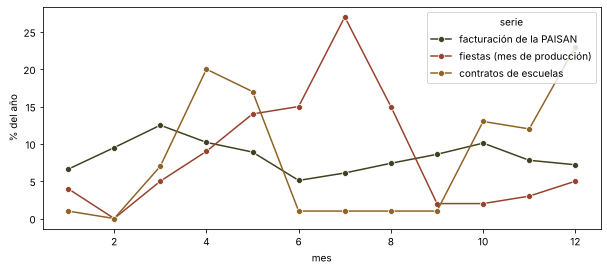

,mes,pct_paisan,hueco_medio,pct_fiestas,pct_escuelas
0,1,6.6,27546.0,4,1
1,2,9.5,14178.0,0,0
2,3,12.5,0.0,5,7
3,4,10.2,10492.0,9,20
4,5,8.9,16932.0,14,17
5,6,5.1,34677.0,15,1
6,7,6.1,29726.0,27,1
7,8,7.4,24019.0,15,1
8,9,8.6,18076.0,2,1
9,10,10.1,10950.0,2,13


In [61]:
fabrica = estacion.copy()   # facturación media de cada mes, 2022-2025 (sección 7)
fabrica["pct_paisan"] = (fabrica["facturacion"] / fabrica["facturacion"].sum() * 100).round(1)
fabrica["hueco_medio"] = (fabrica["facturacion"].max() - fabrica["facturacion"]).round(0)
mes_produccion = (eventos["mes"].dropna() - 2) % 12 + 1   # se produce el mes antes de la fiesta
demanda = pd.DataFrame({"mes": range(1, 13),
                        "pct_fiestas": por_mes(mes_produccion),
                        "pct_escuelas": por_mes(region_c[region_c["tipo_comprador"] == "escuela"]["mes"])})
encaje = fabrica[["mes", "pct_paisan", "hueco_medio"]].merge(demanda, on="mes")

r, p = stats.pearsonr(encaje["pct_paisan"], encaje["pct_fiestas"])
print("PAISAN frente a fiestas (mes de producción) | r =", round(r, 2), "| p =", round(p, 3))
print("hueco medio de junio a agosto:", round(encaje[encaje["mes"].isin([6, 7, 8])]["hueco_medio"].mean()), "€ al mes |",
      "fiestas que se producen de mayo a agosto:", encaje[encaje["mes"].isin([5, 6, 7, 8])]["pct_fiestas"].sum(), "%")

largo_encaje = encaje.melt(id_vars="mes", value_vars=["pct_paisan", "pct_fiestas", "pct_escuelas"], var_name="serie", value_name="pct")
largo_encaje["serie"] = largo_encaje["serie"].map({"pct_paisan": "facturación de la PAISAN", "pct_fiestas": "fiestas (mes de producción)", "pct_escuelas": "contratos de escuelas"})
fig, ax = plt.subplots(figsize=(10, 4))
sns.lineplot(data=largo_encaje, x="mes", y="pct", hue="serie", marker="o",
             palette=[COLORES["verde_serra"], COLORES["terracota"], COLORES["ambar"]], ax=ax)
plt.ylabel("% del año")
plt.show()
encaje

**Qué saco.** Los dos calendarios casi se complementan. La PAISAN factura menos en junio (5,1 % del año) y julio (6,1 %), justo cuando hay que producir para las fiestas: el 71 % se produce de mayo a agosto, con el pico en julio (27 %). En esos meses la fábrica tiene de media unos 29.500 € de hueco al mes. La correlación es negativa (r = −0,49), aunque con 12 meses no es significativa (p = 0,11): es un indicio, no una prueba. Las escuelas piden en abril y mayo y de octubre a diciembre, meses en que la fábrica va a un ritmo medio; su mes más cargado es marzo (12,5 %).

**Para los datos y la presentación.** Para los datos: la tabla `encaje` va a la app (página de la PAISAN). Para la presentación: es el gráfico que une las dos partes: «el mercado pide cuando la fábrica tiene sitio».

**Por qué lo hago.** El objetivo está en euros, pero la fábrica piensa en piezas. Quiero pasar los euros a piezas con los precios que publican otras empresas de personalización.

**Por qué este código.** Uso los 32 precios públicos de 7 empresas portuguesas (sin los emblemas, que no son prendas) y tomo tres precios por pieza: el barato (cuartil 1), el típico (mediana) y el caro (cuartil 3) del precio máximo publicado, que es el más prudente. Con ellos divido tres cantidades: el objetivo anual, el contrato mediano de las escuelas y el precio mediano de las entidades de la lista. Es una cuenta, no un precio de la beira.: cuando la PAISAN dé su precio por pieza, se cambia en una línea.

<sub>Lo que uso: comprensión de listas y diccionarios (semana 1), `len`, `range`, `round`... (semana 1), `for` (semana 1), filtro con una condición (semana 2), `agg`, `size`, `sum`, `mean`, `median`... (semana 2), `pd.DataFrame` / `pd.Series` (semana 2), `astype` (semana 2), `quantile` / `skew` (semana 5).</sub>

In [62]:
textil = mercado[mercado["prenda"] != "emblema"]
precios_pieza = textil["precio_max"].quantile([0.25, 0.5, 0.75]).round(2)
print("precio por pieza en el mercado | barato:", precios_pieza[0.25], "€ | típico:", precios_pieza[0.5], "€ | caro:", precios_pieza[0.75], "€")

escuelas_mediana = contratos[contratos["tipo_comprador"] == "escuela"]["precio"].median()
lista_mediana = ampliada["precio_mediano"].median()
cantidades = {"objetivo anual de la beira.": necesario, "objetivo de un mes": necesario / 12,
              "contrato mediano de una escuela": escuelas_mediana, "contrato mediano de la lista": lista_mediana}
piezas = pd.DataFrame({"euros": [round(v) for v in cantidades.values()]}, index=list(cantidades.keys()))
for nombre, precio in [("piezas_a_precio_caro", precios_pieza[0.75]), ("piezas_a_precio_tipico", precios_pieza[0.5]), ("piezas_a_precio_barato", precios_pieza[0.25])]:
    piezas[nombre] = (piezas["euros"] / precio).round(-1).astype(int)
piezas

precio por pieza en el mercado | barato: 4.86 € | típico: 7.06 € | caro: 10.0 €


,euros,piezas_a_precio_caro,piezas_a_precio_tipico,piezas_a_precio_barato
objetivo anual de la beira.,82787,8280,11730,17030
objetivo de un mes,6899,690,980,1420
contrato mediano de una escuela,3203,320,450,660
contrato mediano de la lista,10037,1000,1420,2070


**Qué saco.** Con los precios publicados, una pieza personalizada sale entre 4,86 € y 10 € (7,06 € la típica). El objetivo de 82.787 € son entre 8.280 y 17.030 piezas al año; al precio típico, unas 11.730, cerca de 980 al mes. Un contrato mediano de escuela son unas 450 piezas y uno mediano de la lista, unas 1.420. Son precios «a partir de», sin la marca ni el margen de la beira.: con su precio real serán menos piezas.

**Para los datos y la presentación.** Para los datos: la pregunta para la PAISAN pasa de euros a piezas. Para la presentación: «el objetivo son unas N piezas al mes»; con el precio real de la PAISAN la cifra se afina.

> **Resumo da secção (português).** Junto as 14 descargas do e-fatura (3.375 facturas válidas, 81 clientes em código). H4 cumpre-se: os três maiores clientes somam em média 86,6 % da facturação (93 % em 2025). H5 cumpre-se com força: 67 % dos clientes voltam no ano seguinte, contra 4 %. H6 cumpre-se: a factura mediana sobe 65 % e o salário mínimo 79 %. Nove clientes vendem roupa ao Estado. Nos últimos doze meses cabem mais 194.302 € na fábrica, sobretudo em Junho e Julho, e a beira. teria de facturar cerca de 82.800 € por ano para os três maiores descerem para 80 %. O modelo de facturação mensal (gradient boosting) erra 9.400 € por mês, melhor do que as regras simples, mas só serve para planear com margem. Juntando as duas partes: a fábrica tem mais folga em Junho e Julho, justamente quando se produz para as festas (71 % de Maio a Agosto), e o objectivo equivale a cerca de 980 peças por mês ao preço típico do mercado (7,06 €).

# 8. Tablas para la base de datos, Tableau y la app

El análisis está hecho en pandas. Para la base de datos lo separo en tablas con claves, como en la clase de datos relacionales; para Tableau lo vuelvo a juntar en tablas anchas. La app lee las mismas tablas.

**Por qué lo hago.** En una base de datos cada dato se guarda una sola vez y las tablas se unen por claves. Quiero preparar las ocho tablas públicas y comprobar sus claves antes de llevarlas a MySQL.

**Por qué este código.** Sigo el patrón de la clase de datos relacionales: una tabla por entidad, la clave primaria sin repetir y cada clave foránea comprobada con `assert set(...).issubset(set(...))` contra su tabla madre. Así, si algo no cuadra, el notebook para aquí y no en MySQL. Los proveedores sin NIF público llevan un código (SN1, SN2...) en lugar del nombre, porque algunos son personas; `con_nif` es «sí» cuando el identificador es solo cifras (un NIF): le quito las cifras con `strip` y miro si queda algo.

<sub>Lo que uso: `lambda` (semana 1), comprensión de listas y diccionarios (semana 1), `for` (semana 1), `items` y `get` (semana 1), `copy` (semana 2), `map` (semana 2), `groupby` (semana 2), `agg`, `size`, `sum`, `mean`, `median`... (semana 2), `reset_index` (semana 2), `merge` (semana 2), `rename` (semana 2), `isin` (semana 2), `drop_duplicates` (semana 2), `sort_values` / `sort_index` (semana 2), `apply` (semana 2), filtro con una condición (semana 2), `isna` / `duplicated` (semana 2), `shape` (semana 2), `head` (semana 2), `pathlib.Path` y `mkdir` (semana 4), `to_csv` (semana 4).</sub>

In [63]:
carpeta_sql = Path(CARPETA_SQL)
carpeta_sql.mkdir(exist_ok=True)

tabla_municipios = municipios[["municipio", "distrito", "piloto", "poblacion", "poblacion_5_24", "km_a_la_base"]].copy()
tabla_municipios["piloto"] = tabla_municipios["piloto"].map({True: "sí", False: "no"})
posicion = organizaciones.groupby("municipio")[["lat", "lon"]].mean().round(4).reset_index()   # posición media de sus organizaciones, para el mapa
tabla_municipios = tabla_municipios.merge(posicion, on="municipio", how="left")

tabla_compradores = compradores[["comprador_nif", "comprador", "tipo_comprador", "concelho"]].rename(columns={"concelho": "municipio"})
tabla_compradores["en_lista"] = tabla_compradores["comprador_nif"].isin(ampliada["comprador_nif"]).map({True: "sí", False: "no"})

# proveedores: los que no tienen NIF público (personas y empresas de fuera) llevan un código (SN1, SN2...) en lugar de su nombre
tabla_proveedores = con_competidores[["proveedor_id", "tipo_proveedor"]].drop_duplicates("proveedor_id").sort_values("proveedor_id").reset_index(drop=True)
tabla_proveedores["con_nif"] = tabla_proveedores["proveedor_id"].apply(lambda x: "sí" if str(x).strip("0123456789") == "" else "no")
sin_nif = list(tabla_proveedores[tabla_proveedores["con_nif"] == "no"]["proveedor_id"])
codigo = {viejo: "SN" + str(i + 1) for i, viejo in enumerate(sin_nif)}
tabla_proveedores["proveedor_id"] = tabla_proveedores["proveedor_id"].replace(codigo)

tabla_contratos = con_competidores[["idcontrato", "comprador_nif", "proveedor_id", "fecha", "ano", "mes", "precio", "producto",
                                    "grupo", "procedimiento", "prazoexecucao", "competidores", "ropa_fardamento"]].rename(columns={"prazoexecucao": "plazo_dias"})
tabla_contratos["proveedor_id"] = tabla_contratos["proveedor_id"].replace(codigo)

tabla_lista = ampliada[["comprador_nif", "grupo_compra", "tasa_vuelta", "anos_con_compra", "contratos", "precio_mediano", "ultimo_ano", "mes_habitual",
                        "contratos_ropa", "compra_ropa_fardamento", "procedimiento_habitual", "plazo_mediano_dias", "proveedores_distintos",
                        "ya_compraba_2013_2015", "publica_concursos"]]

tabla_organizaciones = organizaciones[["nombre", "segmento", "municipio", "nivel_contacto", "km_a_la_base"]].reset_index(drop=True).reset_index()
tabla_organizaciones = tabla_organizaciones.rename(columns={"index": "id_organizacion"})

tabla_eventos = eventos[["evento", "tipo", "municipio", "mes"]].reset_index(drop=True).reset_index()
tabla_eventos = tabla_eventos.rename(columns={"index": "id_evento"})

tabla_indicadores = precios[["ano", "salario_minimo", "indice"]].rename(columns={"indice": "ipc_ropa"})

# claves primarias sin repetir y claves foráneas que existen en la tabla madre
assert tabla_compradores["comprador_nif"].duplicated().sum() == 0
assert tabla_proveedores["proveedor_id"].duplicated().sum() == 0
assert tabla_contratos["idcontrato"].duplicated().sum() == 0
assert set(tabla_compradores[tabla_compradores["municipio"] != ""]["municipio"]).issubset(set(tabla_municipios["municipio"]))
assert set(tabla_contratos["comprador_nif"]).issubset(set(tabla_compradores["comprador_nif"]))
assert set(tabla_contratos["proveedor_id"]).issubset(set(tabla_proveedores["proveedor_id"]))
assert set(tabla_lista["comprador_nif"]).issubset(set(tabla_compradores["comprador_nif"]))
assert set(tabla_organizaciones["municipio"]).issubset(set(tabla_municipios["municipio"]))
assert set(tabla_eventos["municipio"]).issubset(set(tabla_municipios["municipio"]))
print("todas las claves están bien")

tablas = {"municipios": tabla_municipios, "compradores": tabla_compradores, "proveedores": tabla_proveedores, "contratos": tabla_contratos,
          "lista_beira": tabla_lista, "organizaciones": tabla_organizaciones, "eventos": tabla_eventos, "indicadores_ano": tabla_indicadores}
for nombre, tabla in tablas.items():
    tabla.to_csv(carpeta_sql / (nombre + ".csv"), index=False)
    print("====", nombre, "|", tabla.shape[0], "filas |", tabla.shape[1], "columnas")
    print(tabla.head(3))

# primeras filas de las tablas que crea esta celda
print("posicion:")
print(posicion.head())

todas las claves están bien
==== municipios | 66 filas | 8 columnas
    municipio distrito piloto  ...  km_a_la_base      lat     lon
0     Arganil  Coimbra     sí  ...          22.0  40.2309 -8.0179
1  Cantanhede  Coimbra     no  ...          63.0  40.3625 -8.6164
2     Coimbra  Coimbra     no  ...          51.0  40.2115 -8.4371

[3 rows x 8 columns]
==== compradores | 890 filas | 5 columnas
   comprador_nif                                comprador  ... municipio en_lista
0      600012662  Ministério da Defesa Nacional - Marinha  ...                 no
1      600008878              Guarda Nacional Republicana  ...                 no
2      513606084                    Águas do Norte, S. A.  ...                 no

[3 rows x 5 columns]
==== proveedores | 1764 filas | 3 columnas
  proveedor_id tipo_proveedor con_nif
0    500000743           otro      sí
1    500007616           otro      sí
2    500017000           otro      sí
==== contratos | 6382 filas | 13 columnas
   idcontrato  co

**Qué saco.** Ocho tablas en `data/sql/`: 66 municipios, 890 compradores, 1.764 proveedores, 6.382 contratos, las 63 entidades de la lista, 1.596 organizaciones, 136 eventos y 15 años de indicadores. Todas las claves cuadran.

**Para los datos y la presentación.** Para los datos: es el esquema de `sql/1_esquema.sql`. Para la presentación: el diagrama de la base de datos (municipios en el centro; contratos unidos a compradores y proveedores).

**Por qué lo hago.** Tableau trabaja mejor con una tabla ancha que con muchas tablas unidas, y las facturas tienen que quedar en la carpeta interna.

**Por qué este código.** Es lo contrario de la base de datos: allí separo y aquí vuelvo a unir con `merge`. Añado `ambito` (región o resto del país) para poder filtrar en el panel. Los clientes de la PAISAN van solo con su código.

<sub>Lo que uso: `lambda` (semana 1), `merge` (semana 2), `apply` (semana 2), `shape` (semana 2), `head` (semana 2), `drop_duplicates` (semana 2), `map` (semana 2), `reset_index` (semana 2), `rename` (semana 2), `pathlib.Path` y `mkdir` (semana 4), `to_csv` (semana 4).</sub>

In [64]:
carpeta_tableau = Path(CARPETA_TABLEAU)
carpeta_tableau.mkdir(exist_ok=True)
contratos_tableau = tabla_contratos.merge(tabla_compradores, on="comprador_nif").merge(tabla_proveedores, on="proveedor_id").merge(tabla_municipios, on="municipio", how="left")
contratos_tableau["ambito"] = contratos_tableau["municipio"].apply(lambda municipio: "región" if municipio != "" else "resto del país")
contratos_tableau.to_csv(carpeta_tableau / "contratos_tableau.csv", index=False)
lista_tableau = tabla_lista.merge(tabla_compradores, on="comprador_nif").merge(tabla_municipios, on="municipio", how="left")
lista_tableau.to_csv(carpeta_tableau / "lista_tableau.csv", index=False)
print("contratos_tableau:", contratos_tableau.shape, "| lista_tableau:", lista_tableau.shape)
print(contratos_tableau.head(3))
print(lista_tableau.head(3))

carpeta_interna = Path(CARPETA_SQL_INTERNA)
carpeta_interna.mkdir(exist_ok=True)
tabla_clientes = facturas[["cliente", "tipo_cliente"]].drop_duplicates("cliente").merge(por_cliente[["cliente", "vende_al_estado"]], on="cliente")
tabla_clientes["vende_al_estado"] = tabla_clientes["vende_al_estado"].map({True: "sí", False: "no"})
tabla_facturas = facturas[["cliente", "fecha", "ano", "mes", "tipo", "base"]].reset_index(drop=True).reset_index()
tabla_facturas = tabla_facturas.rename(columns={"index": "id_factura"})
assert set(tabla_facturas["cliente"]).issubset(set(tabla_clientes["cliente"]))
tabla_clientes.to_csv(carpeta_interna / "clientes_paisan.csv", index=False)
tabla_facturas.to_csv(carpeta_interna / "facturas_paisan.csv", index=False)
print("clientes_paisan:", tabla_clientes.shape, "| facturas_paisan:", tabla_facturas.shape)
print(tabla_clientes.head(3))
tabla_facturas.head(3)

contratos_tableau: (6382, 27) | lista_tableau: (63, 26)
   idcontrato  comprador_nif proveedor_id  ...      lat     lon          ambito
0     6196722      505330768    504361287  ...  40.2492 -7.5429          región
1     6211102      504404830    503599093  ...      NaN     NaN  resto del país
2     6212130      506876330    510895778  ...      NaN     NaN  resto del país

[3 rows x 27 columns]
   comprador_nif grupo_compra  tasa_vuelta  ...  km_a_la_base      lat     lon
0      600084469      A. fiel          0.8  ...          22.0  40.2309 -8.0179
1      506855368      A. fiel          0.8  ...          32.0  40.3920 -8.2343
2      502083514      A. fiel          0.8  ...          32.0  40.2492 -7.5429

[3 rows x 26 columns]
clientes_paisan: (81, 3) | facturas_paisan: (3375, 7)
  cliente          tipo_cliente vende_al_estado
0     C67                  otro              no
1     C22  empresa o asociación              no
2     C17  empresa o asociación              no


,id_factura,cliente,fecha,ano,mes,tipo,base
0,0,C67,2013-11-08,2013,11,Fatura,300.0
1,1,C22,2013-06-10,2013,6,Fatura,988.0
2,2,C22,2013-06-08,2013,6,Fatura,4925.5


**Qué saco.** `tableau/contratos_tableau.csv` tiene los 6.382 contratos con su comprador y su municipio; `tableau/lista_tableau.csv`, las 63 entidades. Los 81 clientes y las 3.375 facturas quedan en `data/interno/sql/`, sin NIF ni número de factura.

**Para los datos y la presentación.** Para los datos: son las fuentes del dashboard. Para la presentación: no directamente.

> **Resumo da secção (português).** Separo os dados em oito tabelas públicas com chaves primárias e estrangeiras verificadas com `assert`, como na aula de dados relacionais, e volto a juntá-los em duas tabelas largas para o Tableau. As facturas ficam na pasta interna, sem NIF nem números.

# 9. La base de datos en MySQL y las consultas SQL

Aquí creo la base `beira` en MySQL, la cargo y repito con SQL las preguntas principales: consultas básicas, joins, subconsultas, una vista, una tabla temporal, CTE y funciones de ventana. Al final compruebo que SQL y pandas dan lo mismo.

**Para ejecutar esta sección hace falta MySQL** (con `mysql-connector-python`, `sqlalchemy` y `pymysql` instalados). La primera celda pide la contraseña del usuario de MySQL que está en `src/config.py` (`USUARIO_MYSQL`) y no la guarda. Las mismas consultas están en `sql/2_consultas.sql` para abrirlas en MySQL Workbench. Las secciones anteriores no necesitan MySQL.

**Por qué lo hago.** Para hablar con MySQL desde Python necesito dos conexiones: una para crear y cargar la base y otra para consultar.

**Por qué este código.** Hago lo de la lección 4.7: `mysql.connector` (con cursor, `execute`, `executemany` y `commit`) para crear y cargar, y SQLAlchemy (`create_engine`, `text`) con `pd.read_sql` para consultar y recibir un DataFrame. Defino cinco funciones para no repetir código: `ejecutar_script` ejecuta un archivo .sql instrucción a instrucción, `cargar_tabla` inserta un DataFrame entero, `conectar` crea el engine, `consultar` devuelve un DataFrame y `ejecutar` lanza una instrucción sin resultado (como crear una vista). Están también en `src/base_datos.py`. La contraseña la pido con `getpass` para que no quede escrita en el notebook ni en GitHub.

<sub>Lo que uso: `import` (semana 1), `def` y `return` (semana 1), `for` (semana 1), `lower`, `replace`, `split`, `join`, `strip`, `startswith`, `endswith` (semana 1), comprensión de listas y diccionarios (semana 1), `if` / `else` (semana 1), `len`, `range`, `round`... (semana 1), `isna` / `duplicated` (semana 2), `mysql.connector` (`connect`, `cursor`, `execute`, `fetchall`) (semana 4), `ejecutar_script` (función propia, `src/base_datos.py`) (semana 4), `cargar_tabla` (función propia): `executemany` y `commit` (semana 4), `conectar` (función propia): `create_engine` de SQLAlchemy (semana 4), `consultar` (función propia): `pd.read_sql` con `text` (semana 4), `connection.execute` con `text` (semana 4), `getpass` (semana 4).</sub>

In [65]:
import getpass

import mysql.connector
from sqlalchemy import create_engine, text

from config import BASE_DE_DATOS, ESQUEMA_SQL, USUARIO_MYSQL


def ejecutar_script(cursor, ruta):
    """Ejecuta una a una las instrucciones de un script .sql y devuelve cuántas ha ejecutado.

    Las instrucciones van separadas por punto y coma. Las líneas que son solo comentario se quitan.
    """
    script = open(ruta, encoding="utf-8").read()
    ejecutadas = 0
    for trozo in script.split(";"):
        lineas = [linea for linea in trozo.split("\n") if not linea.strip().startswith("--")]
        instruccion = "\n".join(lineas).strip()
        if instruccion != "":
            cursor.execute(instruccion)
            ejecutadas += 1
    return ejecutadas


def cargar_tabla(conexion, nombre, tabla):
    """Inserta todas las filas de un DataFrame en la tabla de MySQL del mismo nombre y devuelve cuántas son.

    Los valores vacíos de pandas (NaN) se pasan como None, que MySQL guarda como NULL.
    """
    columnas = ", ".join(tabla.columns)
    huecos = ", ".join(["%s"] * len(tabla.columns))
    filas = []
    for fila in tabla.values.tolist():
        filas.append(tuple([None if pd.isna(valor) else valor for valor in fila]))
    cursor = conexion.cursor()
    cursor.executemany("INSERT INTO " + nombre + " (" + columnas + ") VALUES (" + huecos + ")", filas)
    conexion.commit()
    cursor.close()
    return len(filas)


def conectar(password, usuario="root", servidor="localhost"):
    """Crea el engine de SQLAlchemy para consultar la base de datos beira."""
    return create_engine("mysql+pymysql://" + usuario + ":" + password + "@" + servidor + "/" + BASE_DE_DATOS)


def consultar(engine, sql):
    """Ejecuta una consulta SQL y devuelve el resultado como DataFrame."""
    with engine.connect() as connection:
        return pd.read_sql(text(sql), connection)


def ejecutar(engine, sql):
    """Ejecuta una instrucción que no devuelve filas, como crear o borrar una vista."""
    with engine.connect() as connection:
        connection.execute(text(sql))


password = getpass.getpass("Contraseña de MySQL del usuario " + USUARIO_MYSQL + ": ")

**Qué saco.** Las librerías y las cinco funciones cargan, y la contraseña queda en memoria, no en el archivo.

**Para los datos y la presentación.** Para los datos: nada. Para la presentación: si alguien pregunta por seguridad, la contraseña nunca se escribe.

**Por qué lo hago.** Quiero crear la base desde cero cada vez, para que siempre se pueda repetir igual.

**Por qué este código.** `ejecutar_script` lee `sql/1_esquema.sql` y ejecuta sus instrucciones una a una con el cursor. El script borra la base si existe y crea las 11 tablas con sus claves primarias y foráneas, primero las tablas madre.

<sub>Lo que uso: `mysql.connector` (`connect`, `cursor`, `execute`, `fetchall`) (semana 4), `ejecutar_script` (función propia, `src/base_datos.py`) (semana 4).</sub>

In [66]:
conexion = mysql.connector.connect(host="localhost", user=USUARIO_MYSQL, passwd=password)
cursor = conexion.cursor()
print("instrucciones ejecutadas:", ejecutar_script(cursor, ESQUEMA_SQL))

cursor.execute("SHOW TABLES")
print([fila[0] for fila in cursor.fetchall()])

instrucciones ejecutadas: 14
['clientes_paisan', 'compradores', 'contratos', 'encomendas_beira', 'eventos', 'facturas_paisan', 'indicadores_ano', 'lista_beira', 'municipios', 'organizaciones', 'proveedores']


**Qué saco.** Se crean las 11 tablas: ocho públicas y tres internas (clientes, facturas y pedidos de la beira.).

**Para los datos y la presentación.** Para los datos: el esquema está en el repositorio (`sql/1_esquema.sql`). Para la presentación: el diagrama de tablas.

**Por qué lo hago.** Antes de cargar vuelvo a leer los CSV que guardé en la sección 8, para comprobar que el archivo, y no solo la tabla en memoria, está bien. Después cargo las tablas públicas.

**Por qué este código.** Es la validación «leer de vuelta» de la clase de datos relacionales: columnas en minúsculas, valores vacíos, duplicados y primeras filas. Al leer el CSV, el municipio vacío pasa a `NaN`, que MySQL guarda como `NULL`. Después `cargar_tabla` inserta todas las filas de una vez con `executemany` y confirma con `commit`, como en el ejemplo de la cafetería de la lección. El orden de la lista es el de las claves: primero municipios, después compradores y proveedores, después contratos.

<sub>Lo que uso: `for` (semana 1), `lower`, `replace`, `split`, `join`, `strip`, `startswith`, `endswith` (semana 1), `pd.read_csv` (semana 2), `.columns =` (semana 2), `.str` (semana 2), `shape` (semana 2), `isna` / `duplicated` (semana 2), `agg`, `size`, `sum`, `mean`, `median`... (semana 2), `head` (semana 2), `cargar_tabla` (función propia): `executemany` y `commit` (semana 4).</sub>

In [67]:
PUBLICAS = ["municipios", "compradores", "proveedores", "contratos", "lista_beira", "organizaciones", "eventos", "indicadores_ano"]
tablas_mysql = {}
for nombre in PUBLICAS:
    tabla = pd.read_csv(CARPETA_SQL + nombre + ".csv")
    tabla.columns = tabla.columns.str.lower()
    tablas_mysql[nombre] = tabla
    print("====", nombre, "|", tabla.shape[0], "filas y", tabla.shape[1], "columnas | valores vacíos:", tabla.isna().sum().sum(), "| filas duplicadas:", tabla.duplicated().sum())
    print(tabla.head(3))

for nombre in PUBLICAS:
    print(nombre, "| filas insertadas:", cargar_tabla(conexion, nombre, tablas_mysql[nombre]))

==== municipios | 66 filas y 8 columnas | valores vacíos: 0 | filas duplicadas: 0
    municipio distrito piloto  ...  km_a_la_base      lat     lon
0     Arganil  Coimbra     sí  ...          22.0  40.2309 -8.0179
1  Cantanhede  Coimbra     no  ...          63.0  40.3625 -8.6164
2     Coimbra  Coimbra     no  ...          51.0  40.2115 -8.4371

[3 rows x 8 columns]
==== compradores | 890 filas y 5 columnas | valores vacíos: 777 | filas duplicadas: 0
   comprador_nif                                comprador  ... municipio en_lista
0      600012662  Ministério da Defesa Nacional - Marinha  ...       NaN       no
1      600008878              Guarda Nacional Republicana  ...       NaN       no
2      513606084                    Águas do Norte, S. A.  ...       NaN       no

[3 rows x 5 columns]
==== proveedores | 1764 filas y 3 columnas | valores vacíos: 0 | filas duplicadas: 0
  proveedor_id tipo_proveedor con_nif
0    500000743           otro      sí
1    500007616           otro      

**Qué saco.** Las ocho tablas se leen bien, sin filas duplicadas, y se insertan todas sus filas.

**Para los datos y la presentación.** Para los datos: lo que entra en MySQL es exactamente lo que está en `data/sql/`. Para la presentación: no.

**Por qué lo hago.** Cargo también las tablas internas, si están: clientes y facturas de la PAISAN y pedidos de la beira.

**Por qué este código.** Con `try` / `except FileNotFoundError`: en GitHub la carpeta interna no está, y así el notebook sigue y solo se salta la parte de la PAISAN. Los pedidos de la beira. vienen de Airtable; la columna `origen_dato` separa los tres registros reales del escenario de 19 ventas.

<sub>Lo que uso: `try` / `except` (semana 1), `for` (semana 1), `lower`, `replace`, `split`, `join`, `strip`, `startswith`, `endswith` (semana 1), `if` / `else` (semana 1), `pd.read_csv` (semana 2), `.columns =` (semana 2), `.str` (semana 2), `shape` (semana 2), `isna` / `duplicated` (semana 2), `agg`, `size`, `sum`, `mean`, `median`... (semana 2), `head` (semana 2), `cargar_tabla` (función propia): `executemany` y `commit` (semana 4).</sub>

In [68]:
INTERNAS = ["clientes_paisan", "facturas_paisan", "encomendas_beira"]
try:
    for nombre in INTERNAS:
        tabla = pd.read_csv(CARPETA_SQL_INTERNA + nombre + ".csv")
        tabla.columns = tabla.columns.str.lower()
        tablas_mysql[nombre] = tabla
        print("====", nombre, "|", tabla.shape[0], "filas y", tabla.shape[1], "columnas | valores vacíos:", tabla.isna().sum().sum(), "| filas duplicadas:", tabla.duplicated().sum())
        if nombre == "encomendas_beira":
            print(tabla[["encomenda", "tipo_entidad", "oferta", "valor_vendido", "coste", "origen_dato"]].head(3))
        else:
            print(tabla.head(3))
        print("filas insertadas:", cargar_tabla(conexion, nombre, tabla))
    HAY_INTERNOS = True
except FileNotFoundError:
    HAY_INTERNOS = False
    print("faltan los datos internos (data/interno/sql): la sección 7 no se ejecuta")

==== clientes_paisan | 81 filas y 3 columnas | valores vacíos: 0 | filas duplicadas: 0
  cliente          tipo_cliente vende_al_estado
0     C67                  otro              no
1     C22  empresa o asociación              no
2     C17  empresa o asociación              no
filas insertadas: 81
==== facturas_paisan | 3375 filas y 7 columnas | valores vacíos: 0 | filas duplicadas: 0
   id_factura cliente       fecha   ano  mes    tipo    base
0           0     C67  2013-11-08  2013   11  Fatura   300.0
1           1     C22  2013-06-10  2013    6  Fatura   988.0
2           2     C22  2013-06-08  2013    6  Fatura  4925.5
filas insertadas: 3375
==== encomendas_beira | 22 filas y 10 columnas | valores vacíos: 7 | filas duplicadas: 0
      encomenda         tipo_entidad  ...  coste    origen_dato
0  ENC-2026-001          Instituição  ...  308.0  registro real
1  ENC-2026-002  Clube ou associação  ...  229.5  registro real
2  ENC-2026-003  Clube ou associação  ...   48.1  registro real

**Qué saco.** Se cargan 81 clientes, 3.375 facturas y 22 pedidos de la beira.

**Para los datos y la presentación.** Para los datos: la base tiene las 11 tablas. Para la presentación: no.

**Por qué lo hago.** Un mensaje de «cargado» no basta: quiero comprobar que MySQL tiene las mismas filas que los CSV.

**Por qué este código.** Cuento las filas de cada tabla con `SELECT COUNT(*)` y lo comparo con el CSV con un `assert`, como se recomienda al final de la clase de datos relacionales.

<sub>Lo que uso: `for` (semana 1), `items` y `get` (semana 1), `len`, `range`, `round`... (semana 1), `pd.DataFrame` / `pd.Series` (semana 2), `SELECT`, `FROM`, `WHERE`, `ORDER BY` (semana 4).</sub>

In [69]:
filas = []
for nombre, tabla in tablas_mysql.items():
    cursor.execute("SELECT COUNT(*) FROM " + nombre)
    filas.append({"tabla": nombre, "filas_csv": len(tabla), "filas_mysql": cursor.fetchall()[0][0]})
comprobacion = pd.DataFrame(filas)
assert (comprobacion["filas_csv"] == comprobacion["filas_mysql"]).all()

cursor.close()
conexion.close()
comprobacion

,tabla,filas_csv,filas_mysql
0,municipios,66,66
1,compradores,890,890
2,proveedores,1764,1764
3,contratos,6382,6382
4,lista_beira,63,63
5,organizaciones,1596,1596
6,eventos,136,136
7,indicadores_ano,15,15
8,clientes_paisan,81,81
9,facturas_paisan,3375,3375


**Qué saco.** Las 11 tablas tienen en MySQL las mismas filas que en los CSV.

**Para los datos y la presentación.** Para los datos: carga verificada. Para la presentación: «la base tiene 11 tablas y cuadra con los datos».

**Por qué lo hago.** A partir de aquí consulto con SQLAlchemy, que devuelve DataFrames.

**Por qué este código.** `conectar` crea el engine con `create_engine` y `consultar` usa `pd.read_sql` con `text`. Pruebo con las cinco primeras filas de contratos.

<sub>Lo que uso: `conectar` (función propia): `create_engine` de SQLAlchemy (semana 4), `consultar` (función propia): `pd.read_sql` con `text` (semana 4), `SELECT`, `FROM`, `WHERE`, `ORDER BY` (semana 4).</sub>

In [70]:
engine = conectar(password, USUARIO_MYSQL)
consultar(engine, "SELECT * FROM contratos LIMIT 5")

,idcontrato,comprador_nif,proveedor_id,fecha,ano,mes,precio,producto,grupo,procedimiento,plazo_dias,competidores,ropa_fardamento
0,6196722,505330768,504361287,2020-01-06,2020,1,17625.00,ropa de trabajo,otras prendas,ajuste directo,45,1,sí
1,6211102,504404830,503599093,2020-01-08,2020,1,25389.00,ropa de trabajo,otras prendas,consulta previa,1095,0,sí
2,6212130,506876330,510895778,2020-01-15,2020,1,22255.89,ropa de trabajo,otras prendas,consulta previa,60,0,sí
3,6217700,503494933,505697661,2020-01-16,2020,1,10140.00,otra ropa,otras prendas,ajuste directo,45,0,no
4,6222956,502176482,503474665,2020-01-16,2020,1,6350.00,merchandising,otras prendas,ajuste directo,15,0,no


**Qué saco.** La conexión funciona.

**Para los datos y la presentación.** Para los datos: nada. Para la presentación: no.

## Consultas básicas, joins y subconsultas

**Por qué lo hago.** Empiezo por lo más simple: el tamaño del mercado en una consulta.

**Por qué este código.** `COUNT`, `COUNT(DISTINCT)`, `SUM`, `MIN` y `MAX` en un solo `SELECT` (lección 4.2).

<sub>Lo que uso: `SELECT`, `FROM`, `WHERE`, `ORDER BY` (semana 4), `consultar` (función propia): `pd.read_sql` con `text` (semana 4).</sub>

In [71]:
sql = """
SELECT COUNT(*) AS contratos,
       COUNT(DISTINCT comprador_nif) AS compradores,
       COUNT(DISTINCT proveedor_id) AS proveedores,
       ROUND(SUM(precio) / 1000000, 1) AS millones_eur,
       MIN(fecha) AS primera_fecha,
       MAX(fecha) AS ultima_fecha
FROM contratos
"""
mercado_sql = consultar(engine, sql)
mercado_sql

,contratos,compradores,proveedores,millones_eur,primera_fecha,ultima_fecha
0,6382,890,1764,150.7,2020-01-02,2025-12-31


**Qué saco.** 6.382 contratos, 890 compradores y 1.764 proveedores entre enero de 2020 y diciembre de 2025.

**Para los datos y la presentación.** Para los datos: son los KPI de cabecera del dashboard. Para la presentación: la cifra de entrada.

**Por qué lo hago.** Quiero los contratos por tramos de precio, para saber cuántos son del tamaño de la beira.

**Por qué este código.** `CASE WHEN` crea el tramo, como un `if`, y una subconsulta en el `SELECT` da el total para calcular el %.

<sub>Lo que uso: `SELECT`, `FROM`, `WHERE`, `ORDER BY` (semana 4), `CASE WHEN` (semana 4), `GROUP BY` con `COUNT`, `SUM`, `AVG` (semana 4), `consultar` (función propia): `pd.read_sql` con `text` (semana 4).</sub>

In [72]:
sql = """
SELECT CASE WHEN precio < 5000 THEN '1. menos de 5.000 €'
            WHEN precio < 20000 THEN '2. de 5.000 a 20.000 €'
            WHEN precio < 75000 THEN '3. de 20.000 a 75.000 €'
            ELSE '4. 75.000 € o más' END AS tramo,
       COUNT(*) AS contratos,
       ROUND(COUNT(*) * 100.0 / (SELECT COUNT(*) FROM contratos), 1) AS pct
FROM contratos
GROUP BY tramo
ORDER BY tramo
"""
tramos_sql = consultar(engine, sql)
tramos_sql

,tramo,contratos,pct
0,1. menos de 5.000 €,1739,27.2
1,2. de 5.000 a 20.000 €,3166,49.6
2,3. de 20.000 a 75.000 €,1171,18.3
3,4. 75.000 € o más,306,4.8


**Qué saco.** El 77 % de los contratos es de menos de 20.000 €, igual que en pandas.

**Para los datos y la presentación.** Para los datos: es un KPI del dashboard. Para la presentación: «tres de cada cuatro contratos son pequeños».

**Por qué lo hago.** Quiero quién compra, juntando contratos y compradores.

**Por qué este código.** Un `JOIN` por `comprador_nif`: el tipo de comprador está en `compradores` y no se repite en cada contrato. Con `CASE WHEN` dentro de `SUM` cuento el % de ajuste directo de cada tipo.

<sub>Lo que uso: `SELECT`, `FROM`, `WHERE`, `ORDER BY` (semana 4), `CASE WHEN` (semana 4), `JOIN` / `LEFT JOIN` (semana 4), `GROUP BY` con `COUNT`, `SUM`, `AVG` (semana 4), `consultar` (función propia): `pd.read_sql` con `text` (semana 4).</sub>

In [73]:
sql = """
SELECT com.tipo_comprador,
       COUNT(DISTINCT com.comprador_nif) AS compradores,
       COUNT(*) AS contratos,
       ROUND(SUM(con.precio) / 1000000, 1) AS millones_eur,
       ROUND(SUM(CASE WHEN con.procedimiento = 'ajuste directo' THEN 1 ELSE 0 END) * 100.0 / COUNT(*), 0) AS pct_ajuste_directo
FROM contratos AS con
JOIN compradores AS com ON com.comprador_nif = con.comprador_nif
GROUP BY com.tipo_comprador
ORDER BY contratos DESC
"""
quien_compra_sql = consultar(engine, sql)
quien_compra_sql

,tipo_comprador,compradores,contratos,millones_eur,pct_ajuste_directo
0,otro,420,3256,89.8,45.0
1,camara,267,2477,56.1,53.0
2,escuela,126,412,2.1,66.0
3,junta,74,233,2.6,79.0
4,bomberos,3,4,0.1,75.0


**Qué saco.** Las juntas (79 %) y las escuelas (66 %) son las que más compran por ajuste directo; los otros organismos (89,8 M€) y las cámaras (56,1 M€), los que más gastan. Aquí cada comprador tiene un solo tipo (el de la tabla `compradores`), por eso las escuelas salen con 126 compradores y no con 128 como en la sección 4, donde el tipo era el de cada contrato.

**Para los datos y la presentación.** Para los datos: misma tabla que en la sección 4. Para la presentación: no, ya está.

**Por qué lo hago.** Quiero cada municipio de la región, compre o no: también los que no aparecen en ningún contrato.

**Por qué este código.** `LEFT JOIN` desde `municipios`: si un municipio no tiene compradores, sale igual con 0. `IFNULL` pone 0 en el gasto vacío.

<sub>Lo que uso: `len`, `range`, `round`... (semana 1), `agg`, `size`, `sum`, `mean`, `median`... (semana 2), filtro con una condición (semana 2), `head` (semana 2), `SELECT`, `FROM`, `WHERE`, `ORDER BY` (semana 4), `IFNULL` (semana 4), `JOIN` / `LEFT JOIN` (semana 4), `GROUP BY` con `COUNT`, `SUM`, `AVG` (semana 4), `consultar` (función propia): `pd.read_sql` con `text` (semana 4).</sub>

In [74]:
sql = """
SELECT mun.municipio,
       mun.piloto,
       mun.km_a_la_base,
       COUNT(DISTINCT com.comprador_nif) AS compradores,
       COUNT(con.idcontrato) AS contratos,
       ROUND(IFNULL(SUM(con.precio), 0), 0) AS importe_eur
FROM municipios AS mun
LEFT JOIN compradores AS com ON com.municipio = mun.municipio
LEFT JOIN contratos AS con ON con.comprador_nif = com.comprador_nif
GROUP BY mun.municipio, mun.piloto, mun.km_a_la_base
ORDER BY contratos DESC, mun.km_a_la_base
"""
por_municipio = consultar(engine, sql)
print("municipios:", len(por_municipio), "| sin ningún contrato publicado:", (por_municipio["contratos"] == 0).sum())
print("total de la región:", por_municipio["compradores"].sum(), "compradores y", por_municipio["contratos"].sum(), "contratos")
print(por_municipio[por_municipio["piloto"] == "sí"])
por_municipio.head(10)

municipios: 66 | sin ningún contrato publicado: 9
total de la región: 113 compradores y 542 contratos
               municipio piloto  ...  contratos  importe_eur
13               Arganil     sí  ...          9     111200.0
29  Oliveira do Hospital     sí  ...          4      18061.0
31                 Nelas     sí  ...          3       2807.0
40       Carregal do Sal     sí  ...          2      25670.0
41                  Seia     sí  ...          2      32425.0
50                 Tábua     sí  ...          1      11882.0

[6 rows x 6 columns]


,municipio,piloto,km_a_la_base,compradores,contratos,importe_eur
0,Coimbra,no,51.0,18,132,2598357.0
1,Viseu,no,34.0,4,59,881908.0
2,Guarda,no,54.0,3,29,574128.0
3,Sertã,no,65.0,2,29,166932.0
4,Castelo Branco,no,67.0,4,18,389928.0
5,Sátão,no,44.0,2,17,32222.0
6,Lousã,no,42.0,3,12,136112.0
7,Figueira da Foz,no,87.0,2,12,162209.0
8,Vouzela,no,45.0,1,11,50147.0
9,Cantanhede,no,63.0,4,11,392488.0


**Qué saco.** Salen los 66 municipios: 9 sin ningún contrato publicado aparecen con 0. En total, 113 compradores y 542 contratos en la región, como en pandas.

**Para los datos y la presentación.** Para los datos: es la base del mapa de Tableau. Para la presentación: no.

**Por qué lo hago.** Quiero saber si en la región hay un proveedor que domine.

**Por qué este código.** Una subconsulta en el `FROM` cuenta contratos por proveedor; la consulta de fuera resume: proveedores, el mayor y su %.

<sub>Lo que uso: `SELECT`, `FROM`, `WHERE`, `ORDER BY` (semana 4), `CASE WHEN` (semana 4), subconsulta (semana 4), `JOIN` / `LEFT JOIN` (semana 4), `GROUP BY` con `COUNT`, `SUM`, `AVG` (semana 4), `consultar` (función propia): `pd.read_sql` con `text` (semana 4).</sub>

In [75]:
sql = """
SELECT COUNT(*) AS proveedores,
       SUM(contratos) AS contratos,
       MAX(contratos) AS contratos_del_mayor,
       ROUND(MAX(contratos) * 100.0 / SUM(contratos), 1) AS pct_del_mayor,
       SUM(CASE WHEN contratos = 1 THEN 1 ELSE 0 END) AS con_un_solo_contrato
FROM (SELECT con.proveedor_id,
             COUNT(*) AS contratos
      FROM contratos AS con
      JOIN compradores AS com ON com.comprador_nif = con.comprador_nif
      WHERE com.municipio IS NOT NULL
      GROUP BY con.proveedor_id) AS por_proveedor
"""
nadie_domina = consultar(engine, sql)
nadie_domina

,proveedores,contratos,contratos_del_mayor,pct_del_mayor,con_un_solo_contrato
0,268,542,29,5.4,173


**Qué saco.** 268 proveedores para 542 contratos de la región; el mayor tiene el 5 %. Lo mismo que en pandas.

**Para los datos y la presentación.** Para los datos: nada nuevo. Para la presentación: «nadie domina».

## Vistas, tabla temporal y CTE

**Por qué lo hago.** Muchas consultas usan «los contratos de la región con su comprador y su municipio». En lugar de repetir los joins, los guardo como vista.

**Por qué este código.** `CREATE VIEW` guarda la consulta con nombre y se usa como una tabla (lección 4.5). Primero `DROP VIEW IF EXISTS` para poder repetir. Con ella calculo cómo compran en la región.

<sub>Lo que uso: `connection.execute` con `text` (semana 4), `CREATE VIEW` (semana 4), `SELECT`, `FROM`, `WHERE`, `ORDER BY` (semana 4), `JOIN` / `LEFT JOIN` (semana 4), `GROUP BY` con `COUNT`, `SUM`, `AVG` (semana 4), `consultar` (función propia): `pd.read_sql` con `text` (semana 4).</sub>

In [76]:
ejecutar(engine, "DROP VIEW IF EXISTS contratos_region")
ejecutar(engine, """
CREATE VIEW contratos_region AS
SELECT con.idcontrato, con.fecha, con.ano, con.mes, con.precio, con.producto, con.grupo, con.procedimiento,
       con.plazo_dias, con.competidores, con.ropa_fardamento, con.proveedor_id,
       com.comprador_nif, com.comprador, com.tipo_comprador, com.en_lista,
       mun.municipio, mun.distrito, mun.piloto, mun.km_a_la_base
FROM contratos AS con
JOIN compradores AS com ON com.comprador_nif = con.comprador_nif
JOIN municipios AS mun ON mun.municipio = com.municipio
""")

sql = """
SELECT procedimiento,
       COUNT(*) AS contratos,
       ROUND(COUNT(*) * 100.0 / (SELECT COUNT(*) FROM contratos_region), 0) AS pct,
       ROUND(AVG(competidores), 1) AS competidores_medios,
       ROUND(AVG(precio), 0) AS precio_medio
FROM contratos_region
GROUP BY procedimiento
ORDER BY contratos DESC
"""
como_compran_sql = consultar(engine, sql)
como_compran_sql

,procedimiento,contratos,pct,competidores_medios,precio_medio
0,ajuste directo,262,48.0,0.1,9014.0
1,consulta previa,213,39.0,1.8,22871.0
2,concurso,66,12.0,8.1,27065.0
3,otro,1,0.0,0.0,7366.0


**Qué saco.** En la región el 48 % es ajuste directo y el 39 % consulta previa.

**Para los datos y la presentación.** Para los datos: la vista `contratos_region` queda en la base para Workbench. Para la presentación: no, ya está.

**Por qué lo hago.** Quiero contar cuántos años compra cada entidad, guardando antes un resultado intermedio.

**Por qué este código.** `CREATE TEMPORARY TABLE` guarda las compras por comprador y año; solo dura lo que dura la conexión, así que la creo y la consulto dentro del mismo `with engine.connect()`.

<sub>Lo que uso: `connection.execute` con `text` (semana 4), `CREATE TEMPORARY TABLE` (semana 4), `SELECT`, `FROM`, `WHERE`, `ORDER BY` (semana 4), `GROUP BY` con `COUNT`, `SUM`, `AVG` (semana 4), `consultar` (función propia): `pd.read_sql` con `text` (semana 4), subconsulta (semana 4).</sub>

In [77]:
with engine.connect() as connection:
    connection.execute(text("DROP TABLE IF EXISTS compras_ano"))
    connection.execute(text("""
CREATE TEMPORARY TABLE compras_ano AS
SELECT comprador_nif,
       ano,
       COUNT(*) AS contratos,
       SUM(precio) AS importe
FROM contratos
GROUP BY comprador_nif, ano
"""))
    anos_con_compra = pd.read_sql(text("""
SELECT anos_con_compra,
       COUNT(*) AS compradores
FROM (SELECT comprador_nif,
             COUNT(*) AS anos_con_compra
      FROM compras_ano
      GROUP BY comprador_nif) AS por_comprador
GROUP BY anos_con_compra
ORDER BY anos_con_compra
"""), connection)
anos_con_compra

,anos_con_compra,compradores
0,1,324
1,2,176
2,3,127
3,4,98
4,5,80
5,6,85


**Qué saco.** 324 compradores compran en un solo año y 85 en los seis, como en la sección 3.

**Para los datos y la presentación.** Para los datos: nada. Para la presentación: no.

**Por qué lo hago.** H1 en SQL: quiero los mismos pares «compra este año / compra el siguiente» y la misma prueba.

**Por qué este código.** Con `WITH` (CTE) encadeno cuatro pasos con nombre: los años, el primer año de cada comprador, sus compras y los pares. Es más legible que subconsultas metidas unas dentro de otras. El chi-cuadrado lo hago en Python sobre el resultado: así se combinan SQL y Python.

<sub>Lo que uso: `len`, `range`, `round`... (semana 1), `agg`, `size`, `sum`, `mean`, `median`... (semana 2), `WITH` (CTE) (semana 4), `SELECT`, `FROM`, `WHERE`, `ORDER BY` (semana 4), `GROUP BY` con `COUNT`, `SUM`, `AVG` (semana 4), `CASE WHEN` (semana 4), `JOIN` / `LEFT JOIN` (semana 4), `consultar` (función propia): `pd.read_sql` con `text` (semana 4), `chi2_contingency` (semana 5), `association` (semana 5).</sub>

In [78]:
sql = """
WITH anos AS (
    SELECT DISTINCT ano FROM contratos WHERE ano <= 2024
), primera AS (
    SELECT comprador_nif, MIN(ano) AS primer_ano FROM contratos GROUP BY comprador_nif
), compras AS (
    SELECT DISTINCT comprador_nif, ano FROM contratos
), pares AS (
    SELECT pri.comprador_nif,
           anos.ano,
           CASE WHEN este.comprador_nif IS NULL THEN 0 ELSE 1 END AS compra_este_ano,
           CASE WHEN sig.comprador_nif IS NULL THEN 0 ELSE 1 END AS compra_el_siguiente
    FROM primera AS pri
    JOIN anos ON anos.ano >= pri.primer_ano
    LEFT JOIN compras AS este ON este.comprador_nif = pri.comprador_nif AND este.ano = anos.ano
    LEFT JOIN compras AS sig ON sig.comprador_nif = pri.comprador_nif AND sig.ano = anos.ano + 1
)
SELECT compra_este_ano,
       COUNT(*) AS casos,
       SUM(compra_el_siguiente) AS vuelven,
       ROUND(SUM(compra_el_siguiente) * 100.0 / COUNT(*), 0) AS pct_vuelven
FROM pares
GROUP BY compra_este_ano
ORDER BY compra_este_ano
"""
h1 = consultar(engine, sql)
h1["no_vuelven"] = h1["casos"] - h1["vuelven"]
tabla = h1[["no_vuelven", "vuelven"]]
chi2, p, gl, esperado = stats.chi2_contingency(tabla)
print(h1["casos"].sum(), "pares comprador-año | chi2 =", round(chi2, 1), "| p =", round(p, 4), "| V de Cramér =", round(association(tabla, method="cramer"), 2))
h1

2907 pares comprador-año | chi2 = 289.4 | p = 0.0 | V de Cramér = 0.32


,compra_este_ano,casos,vuelven,pct_vuelven,no_vuelven
0,0,1011,292,29.0,719
1,1,1896,1177,62.0,719


**Qué saco.** Sale lo mismo que en pandas: vuelve el 62 % de los que compraron y el 29 % de los que no (V = 0,32).

**Para los datos y la presentación.** Para los datos: SQL y pandas coinciden. Para la presentación: «la hipótesis principal se comprueba igual en SQL».

## Funciones de ventana

**Por qué lo hago.** ¿Vuelven al año siguiente? Lo quiero año a año, mirando para cada compra cuál es la siguiente.

**Por qué este código.** `LEAD` (función de ventana) trae el año de la siguiente compra del mismo comprador (`PARTITION BY comprador_nif`). Si es el año + 1, ha vuelto.

<sub>Lo que uso: `WITH` (CTE) (semana 4), `SELECT`, `FROM`, `WHERE`, `ORDER BY` (semana 4), `LAG` y `LEAD` (semana 4), funciones de ventana (`OVER`, `PARTITION BY`) (semana 4), `CASE WHEN` (semana 4), `GROUP BY` con `COUNT`, `SUM`, `AVG` (semana 4), `consultar` (función propia): `pd.read_sql` con `text` (semana 4), `plt.subplots`, `plt.xlabel`, `plt.show`... (semana 5), `sns.barplot` (semana 5).</sub>

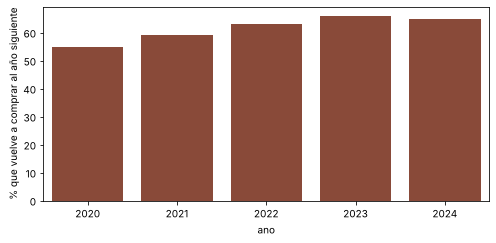

,ano,compradores,vuelven,pct_vuelven
0,2020,326,179,55.0
1,2021,322,189,59.0
2,2022,364,231,63.0
3,2023,431,284,66.0
4,2024,453,294,65.0


In [79]:
sql = """
WITH compras AS (
    SELECT DISTINCT comprador_nif, ano FROM contratos
), con_siguiente AS (
    SELECT comprador_nif,
           ano,
           LEAD(ano) OVER (PARTITION BY comprador_nif ORDER BY ano) AS siguiente_compra
    FROM compras
)
SELECT ano,
       COUNT(*) AS compradores,
       SUM(CASE WHEN siguiente_compra = ano + 1 THEN 1 ELSE 0 END) AS vuelven,
       ROUND(SUM(CASE WHEN siguiente_compra = ano + 1 THEN 1 ELSE 0 END) * 100.0 / COUNT(*), 0) AS pct_vuelven
FROM con_siguiente
WHERE ano <= 2024
GROUP BY ano
ORDER BY ano
"""
h1_por_ano = consultar(engine, sql)
fig, ax = plt.subplots(figsize=(8, 3.5))
sns.barplot(data=h1_por_ano, x="ano", y="pct_vuelven", color=COLORES["terracota"], ax=ax)
plt.ylabel("% que vuelve a comprar al año siguiente")
plt.show()
h1_por_ano

**Qué saco.** Cada año vuelve a comprar entre el 55 % (2020) y el 66 % (2023) de los que compraron, como en pandas.

**Para los datos y la presentación.** Para los datos: nada nuevo. Para la presentación: el gráfico de barras por año, si hace falta.

**Por qué lo hago.** ¿Cuando vuelven, cambian de proveedor? En pandas lo hice con `duplicated`; en SQL lo hago con ventanas.

**Por qué este código.** Dos `ROW_NUMBER`: uno numera las compras de cada comprador y otro las veces que compra al mismo proveedor. Si la compra no es la primera y es la primera vez con ese proveedor, es un proveedor nuevo.

<sub>Lo que uso: `WITH` (CTE) (semana 4), `SELECT`, `FROM`, `WHERE`, `ORDER BY` (semana 4), `ROW_NUMBER` y `RANK` (semana 4), funciones de ventana (`OVER`, `PARTITION BY`) (semana 4), `JOIN` / `LEFT JOIN` (semana 4), `CASE WHEN` (semana 4), `GROUP BY` con `COUNT`, `SUM`, `AVG` (semana 4), `consultar` (función propia): `pd.read_sql` con `text` (semana 4).</sub>

In [80]:
sql = """
WITH numerados AS (
    SELECT con.comprador_nif,
           com.en_lista,
           ROW_NUMBER() OVER (PARTITION BY con.comprador_nif ORDER BY con.fecha, con.idcontrato) AS compra_numero,
           ROW_NUMBER() OVER (PARTITION BY con.comprador_nif, con.proveedor_id ORDER BY con.fecha, con.idcontrato) AS vez_con_ese_proveedor
    FROM contratos AS con
    JOIN compradores AS com ON com.comprador_nif = con.comprador_nif
)
SELECT en_lista,
       COUNT(*) AS compras_despues_de_la_primera,
       SUM(CASE WHEN vez_con_ese_proveedor = 1 THEN 1 ELSE 0 END) AS a_un_proveedor_nuevo,
       ROUND(SUM(CASE WHEN vez_con_ese_proveedor = 1 THEN 1 ELSE 0 END) * 100.0 / COUNT(*), 0) AS pct_proveedor_nuevo
FROM numerados
WHERE compra_numero > 1
GROUP BY en_lista
ORDER BY en_lista DESC
"""
cambio_proveedor = consultar(engine, sql)
cambio_proveedor

,en_lista,compras_despues_de_la_primera,a_un_proveedor_nuevo,pct_proveedor_nuevo
0,sí,414,244,59.0
1,no,5078,2573,51.0


**Qué saco.** En la lista de la beira., el 59 % de las compras repetidas va a un proveedor nuevo, igual que en pandas.

**Para los datos y la presentación.** Para los datos: el número de la presentación sale igual por dos caminos. Para la presentación: «son fieles a comprar, no al proveedor».

**Por qué lo hago.** MySQL no tiene una función de mediana, y la mediana es la medida que uso en todo el proyecto.

**Por qué este código.** La calculo con ventanas: `ROW_NUMBER` ordena los precios de cada tipo de comprador y `COUNT(*) OVER` da el total; la mediana es la fila del medio (o la media de las dos del medio). Lo compruebo con pandas en la misma celda.

<sub>Lo que uso: `merge` (semana 2), `groupby` (semana 2), `agg`, `size`, `sum`, `mean`, `median`... (semana 2), `sort_values` / `sort_index` (semana 2), `WITH` (CTE) (semana 4), `SELECT`, `FROM`, `WHERE`, `ORDER BY` (semana 4), `ROW_NUMBER` y `RANK` (semana 4), funciones de ventana (`OVER`, `PARTITION BY`) (semana 4), `JOIN` / `LEFT JOIN` (semana 4), `GROUP BY` con `COUNT`, `SUM`, `AVG` (semana 4), `consultar` (función propia): `pd.read_sql` con `text` (semana 4).</sub>

In [81]:
sql = """
WITH ordenados AS (
    SELECT com.tipo_comprador,
           con.precio,
           ROW_NUMBER() OVER (PARTITION BY com.tipo_comprador ORDER BY con.precio) AS posicion,
           COUNT(*) OVER (PARTITION BY com.tipo_comprador) AS total
    FROM contratos AS con
    JOIN compradores AS com ON com.comprador_nif = con.comprador_nif
)
SELECT tipo_comprador,
       total AS contratos,
       ROUND(AVG(precio), 0) AS precio_mediano
FROM ordenados
WHERE posicion * 2 BETWEEN total AND total + 2
GROUP BY tipo_comprador, total
ORDER BY precio_mediano
"""
mediana = consultar(engine, sql)
en_pandas = tablas_mysql["contratos"].merge(tablas_mysql["compradores"], on="comprador_nif").groupby("tipo_comprador")["precio"].median().round(0)
print("la misma mediana en pandas:")
print(en_pandas.sort_values())
mediana

la misma mediana en pandas:
tipo_comprador
escuela      3188.0
junta        7955.0
otro         9509.0
camara      12000.0
bomberos    22532.0
Name: precio, dtype: float64


,tipo_comprador,contratos,precio_mediano
0,escuela,412,3188.0
1,junta,233,7955.0
2,otro,3256,9509.0
3,camara,2477,12000.0
4,bomberos,4,22532.0


**Qué saco.** Las medianas de SQL y de pandas coinciden: escuelas 3.188 €, cámaras 12.000 €. Son algo distintas de las de la sección 3 (3.203 € y 11.988 €) porque aquí cada comprador tiene un solo tipo.

**Para los datos y la presentación.** Para los datos: SQL y pandas cuadran. Para la presentación: no.

**Por qué lo hago.** Quiero, para cada distrito, las tres entidades fieles más cercanas: por dónde empezar en cada zona.

**Por qué este código.** `RANK() OVER (PARTITION BY distrito ORDER BY km...)` numera las entidades dentro de cada distrito, y me quedo con las tres primeras con un `WHERE` en la consulta de fuera.

<sub>Lo que uso: `WITH` (CTE) (semana 4), `SELECT`, `FROM`, `WHERE`, `ORDER BY` (semana 4), `ROW_NUMBER` y `RANK` (semana 4), funciones de ventana (`OVER`, `PARTITION BY`) (semana 4), `JOIN` / `LEFT JOIN` (semana 4), `consultar` (función propia): `pd.read_sql` con `text` (semana 4).</sub>

In [82]:
sql = """
WITH ordenadas AS (
    SELECT mun.distrito,
           com.comprador,
           com.tipo_comprador,
           mun.municipio,
           mun.km_a_la_base,
           lis.grupo_compra,
           lis.mes_habitual,
           lis.procedimiento_habitual,
           RANK() OVER (PARTITION BY mun.distrito ORDER BY mun.km_a_la_base, lis.contratos DESC) AS posicion
    FROM lista_beira AS lis
    JOIN compradores AS com ON com.comprador_nif = lis.comprador_nif
    JOIN municipios AS mun ON mun.municipio = com.municipio
    WHERE lis.grupo_compra = 'A. fiel'
)
SELECT distrito, posicion, comprador, tipo_comprador, municipio, km_a_la_base, mes_habitual, procedimiento_habitual
FROM ordenadas
WHERE posicion <= 3
ORDER BY distrito, posicion
"""
primeras = consultar(engine, sql)
primeras

,distrito,posicion,comprador,tipo_comprador,municipio,km_a_la_base,mes_habitual,procedimiento_habitual
0,Castelo Branco,1,Universidade da Beira Interior,otro,Covilhã,32.0,3,ajuste directo
1,Castelo Branco,2,Município de Belmonte,camara,Belmonte,43.0,11,ajuste directo
2,Castelo Branco,3,Município de Oleiros,camara,Oleiros,49.0,3,ajuste directo
3,Coimbra,1,Agrupamento de Escolas de Arganil,escuela,Arganil,22.0,4,ajuste directo
4,Coimbra,2,Agrupamento de Escolas de Vila Nova de Poiares,escuela,Vila Nova de Poiares,37.0,12,ajuste directo
5,Coimbra,3,Associação Para a Recuperação de Cidadãos Inad...,otro,Lousã,42.0,3,consulta previa
6,Guarda,1,Município da Guarda,camara,Guarda,54.0,8,consulta previa
7,Guarda,2,Município de Trancoso,camara,Trancoso,63.0,3,consulta previa
8,Guarda,3,Associação Promotora do Ensino Profissional da...,escuela,Trancoso,63.0,4,consulta previa
9,Viseu,1,Município de Mortágua,camara,Mortágua,32.0,10,consulta previa


**Qué saco.** Sale una ruta de visitas por distrito con las tres fieles más cercanas.

**Para los datos y la presentación.** Para los datos: es un buen filtro para la app. Para la presentación: la ruta de visitas por zona.

## La PAISAN en SQL

**Por qué lo hago.** H4 en SQL: el peso de los tres mayores clientes de cada año, guardado como vista para usarlo después.

**Por qué este código.** La vista `concentracion_paisan` usa una CTE y dos ventanas: `ROW_NUMBER` ordena los clientes de cada año y `SUM() OVER` da la facturación del año. La prueba t la hago en Python con el resultado. La línea del 80 % la dibujo con `plt.plot`.

<sub>Lo que uso: `if` / `else` (semana 1), `len`, `range`, `round`... (semana 1), `isin` (semana 2), `agg`, `size`, `sum`, `mean`, `median`... (semana 2), `connection.execute` con `text` (semana 4), `CREATE VIEW` (semana 4), `WITH` (CTE) (semana 4), `SELECT`, `FROM`, `WHERE`, `ORDER BY` (semana 4), `GROUP BY` con `COUNT`, `SUM`, `AVG` (semana 4), `ROW_NUMBER` y `RANK` (semana 4), funciones de ventana (`OVER`, `PARTITION BY`) (semana 4), `consultar` (función propia): `pd.read_sql` con `text` (semana 4), `stats.ttest_1samp` (`alternative`) (semana 5), `plt.subplots`, `plt.xlabel`, `plt.show`... (semana 5), `sns.barplot` (semana 5).</sub>

peso medio de los tres mayores: 86.6 % | t = 3.93 | p = 0.0012 | 12 años


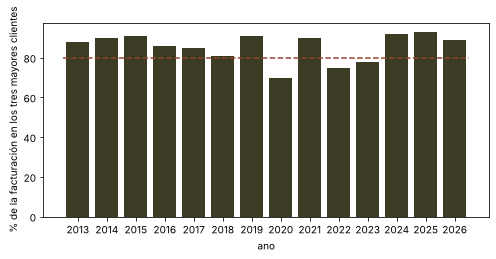

     ano  facturacion  tres_mayores  pct_tres_mayores
0   2013     231578.0      204871.0              88.0
1   2014     240498.0      216433.0              90.0
2   2015     323148.0      294550.0              91.0
3   2016     254554.0      217782.0              86.0
4   2017     339505.0      288793.0              85.0
5   2018     360470.0      291339.0              81.0
6   2019     383912.0      347484.0              91.0
7   2020     333095.0      233666.0              70.0
8   2021     317522.0      285749.0              90.0
9   2022     397349.0      299247.0              75.0
10  2023     494097.0      386239.0              78.0
11  2024     473909.0      435306.0              92.0
12  2025     511185.0      475177.0              93.0
13  2026     538750.0      478193.0              89.0


In [83]:
if HAY_INTERNOS:
    ejecutar(engine, "DROP VIEW IF EXISTS concentracion_paisan")
    ejecutar(engine, """
CREATE VIEW concentracion_paisan AS
WITH cliente_ano AS (
    SELECT ano, cliente, SUM(base) AS facturado
    FROM facturas_paisan
    GROUP BY ano, cliente
), ordenados AS (
    SELECT ano,
           cliente,
           facturado,
           ROW_NUMBER() OVER (PARTITION BY ano ORDER BY facturado DESC) AS posicion,
           SUM(facturado) OVER (PARTITION BY ano) AS facturacion_ano
    FROM cliente_ano
)
SELECT ano,
       MAX(facturacion_ano) AS facturacion,
       SUM(facturado) AS tres_mayores,
       ROUND(SUM(facturado) * 100.0 / MAX(facturacion_ano), 0) AS pct_tres_mayores
FROM ordenados
WHERE posicion <= 3
GROUP BY ano
""")
    concentracion_sql = consultar(engine, """
SELECT ano,
       ROUND(facturacion, 0) AS facturacion,
       ROUND(tres_mayores, 0) AS tres_mayores,
       pct_tres_mayores
FROM concentracion_paisan
ORDER BY ano
""")
    completos_sql = concentracion_sql[concentracion_sql["ano"].isin([2020, 2021]) == False]
    t, p = stats.ttest_1samp(completos_sql["pct_tres_mayores"], 80, alternative="greater")
    print("peso medio de los tres mayores:", round(completos_sql["pct_tres_mayores"].mean(), 1), "% | t =", round(t, 2), "| p =", round(p, 4), "|", len(completos_sql), "años")
    fig, ax = plt.subplots(figsize=(8, 3.5))
    sns.barplot(data=concentracion_sql, x="ano", y="pct_tres_mayores", color=COLORES["verde_serra"], ax=ax)
    plt.plot([-0.5, len(concentracion_sql) - 0.5], [80, 80], color=COLORES["terracota"], linestyle="--")
    plt.ylabel("% de la facturación en los tres mayores clientes")
    plt.show()
    print(concentracion_sql)

**Qué saco.** Sale lo mismo que en pandas: 86,6 % de media en los años completos (p = 0,001) y 93 % en 2025.

**Para los datos y la presentación.** Para los datos: la vista queda en la base. Para la presentación: el gráfico de barras con la línea del 80 %.

**Por qué lo hago.** La capacidad en SQL: el mejor mes de los últimos doce y el hueco de cada mes.

**Por qué este código.** `MAX() OVER ()` pone al lado de cada mes el máximo de los doce sin agrupar las filas; restando sale el hueco. Una subconsulta elige los últimos doce meses.

<sub>Lo que uso: `if` / `else` (semana 1), `len`, `range`, `round`... (semana 1), `agg`, `size`, `sum`, `mean`, `median`... (semana 2), `astype` (semana 2), `consultar` (función propia): `pd.read_sql` con `text` (semana 4), `WITH` (CTE) (semana 4), `SELECT`, `FROM`, `WHERE`, `ORDER BY` (semana 4), `GROUP BY` con `COUNT`, `SUM`, `AVG` (semana 4), subconsulta (semana 4), funciones de ventana (`OVER`, `PARTITION BY`) (semana 4), `plt.subplots`, `plt.xlabel`, `plt.show`... (semana 5), `sns.barplot` (semana 5).</sub>

facturación de los últimos doce meses: 606355 € | hueco hasta el mejor mes: 194303 €


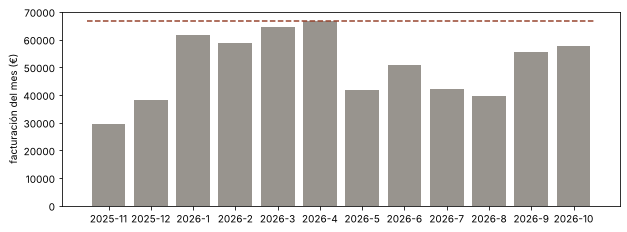

     ano  mes  facturacion  mejor_mes    hueco  periodo
0   2025   11      29502.0    66721.0  37219.0  2025-11
1   2025   12      38103.0    66721.0  28619.0  2025-12
2   2026    1      61737.0    66721.0   4985.0   2026-1
3   2026    2      58689.0    66721.0   8032.0   2026-2
4   2026    3      64428.0    66721.0   2293.0   2026-3
5   2026    4      66721.0    66721.0      0.0   2026-4
6   2026    5      41933.0    66721.0  24788.0   2026-5
7   2026    6      50640.0    66721.0  16081.0   2026-6
8   2026    7      42221.0    66721.0  24501.0   2026-7
9   2026    8      39482.0    66721.0  27240.0   2026-8
10  2026    9      55405.0    66721.0  11317.0   2026-9
11  2026   10      57494.0    66721.0   9228.0  2026-10


In [84]:
if HAY_INTERNOS:
    hueco_sql = consultar(engine, """
WITH mensual AS (
    SELECT ano, mes, SUM(base) AS facturacion
    FROM facturas_paisan
    GROUP BY ano, mes
), doce AS (
    SELECT ano, mes, facturacion
    FROM mensual
    WHERE ano * 12 + mes > (SELECT MAX(ano * 12 + mes) FROM mensual) - 12
)
SELECT ano,
       mes,
       ROUND(facturacion, 0) AS facturacion,
       ROUND(MAX(facturacion) OVER (), 0) AS mejor_mes,
       ROUND(MAX(facturacion) OVER () - facturacion, 0) AS hueco
FROM doce
ORDER BY ano, mes
""")
    print("facturación de los últimos doce meses:", round(hueco_sql["facturacion"].sum()), "€ | hueco hasta el mejor mes:", round(hueco_sql["hueco"].sum()), "€")
    hueco_sql["periodo"] = hueco_sql["ano"].astype(str) + "-" + hueco_sql["mes"].astype(str)
    fig, ax = plt.subplots(figsize=(10, 3.5))
    sns.barplot(data=hueco_sql, x="periodo", y="facturacion", color=COLORES["gris"], ax=ax)
    plt.plot([-0.5, len(hueco_sql) - 0.5], [hueco_sql["mejor_mes"].max(), hueco_sql["mejor_mes"].max()], color=COLORES["terracota"], linestyle="--")
    plt.xlabel("")
    plt.ylabel("facturación del mes (€)")
    plt.show()
    print(hueco_sql)

**Qué saco.** Mismo resultado que en pandas: 606.355 € en doce meses y un hueco de 194.303 € (un euro más, por redondear cada mes).

**Para los datos y la presentación.** Para los datos: nada nuevo. Para la presentación: el gráfico de los doce meses con la línea del mejor mes.

**Por qué lo hago.** Por último, los pedidos de la beira. frente al objetivo anual.

**Por qué este código.** Agrupo los pedidos por `origen_dato` (registro real o escenario) y, con un `CROSS JOIN`, pongo al lado el objetivo que sale de la vista de H4: tres mayores / 0,80 − facturación de 2025.

<sub>Lo que uso: `if` / `else` (semana 1), `consultar` (función propia): `pd.read_sql` con `text` (semana 4), `SELECT`, `FROM`, `WHERE`, `ORDER BY` (semana 4), `GROUP BY` con `COUNT`, `SUM`, `AVG` (semana 4), `CROSS JOIN` (semana 4), `JOIN` / `LEFT JOIN` (semana 4), subconsulta (semana 4).</sub>

In [85]:
if HAY_INTERNOS:
    beira_pedidos = consultar(engine, """
SELECT origen_dato,
       COUNT(*) AS pedidos,
       ROUND(SUM(valor_vendido), 2) AS vendido,
       ROUND(SUM(coste), 2) AS coste,
       ROUND((SUM(valor_vendido) - SUM(coste)) * 100.0 / SUM(valor_vendido), 1) AS margen_pct,
       ROUND(AVG(valor_vendido), 0) AS pedido_medio
FROM encomendas_beira
GROUP BY origen_dato
ORDER BY origen_dato DESC
""")
    print(beira_pedidos)
    beira_objetivo = consultar(engine, """
SELECT ped.origen_dato,
       ROUND(SUM(ped.valor_vendido), 0) AS vendido,
       ROUND(MAX(obj.objetivo), 0) AS objetivo_anual,
       ROUND(SUM(ped.valor_vendido) * 100.0 / MAX(obj.objetivo), 1) AS pct_del_objetivo
FROM encomendas_beira AS ped
CROSS JOIN (SELECT tres_mayores / 0.80 - facturacion AS objetivo
            FROM concentracion_paisan
            WHERE ano = 2025) AS obj
GROUP BY ped.origen_dato
ORDER BY ped.origen_dato DESC
""")
    print(beira_objetivo)

     origen_dato  pedidos   vendido     coste  margen_pct  pedido_medio
0  registro real        3    892.00    585.60        34.3         297.0
1      escenario       19  29230.51  15630.26        46.5        1538.0
     origen_dato  vendido  objetivo_anual  pct_del_objetivo
0  registro real    892.0         82787.0               1.1
1      escenario  29231.0         82787.0              35.3


**Qué saco.** Los tres pedidos reales suman 892 € (margen del 34,3 %), el 1,1 % del objetivo anual de 82.787 €. El escenario de 19 ventas suma 29.230,51 € (margen del 46,5 %), el 35,3 % del objetivo. Es un escenario: sirve para enseñar cómo se seguirá el objetivo, no son ventas.

**Para los datos y la presentación.** Para los datos: es la página «La beira. hoy» de la app. Para la presentación: «así mediremos el avance: euros vendidos frente a 83.000 €».

**Por qué lo hago.** Quiero cerrar la sección comprobando que SQL y pandas dan los mismos números clave.

**Por qué este código.** Pongo en una tabla tres números calculados por los dos caminos y los comparo con `assert`: si alguno no cuadra, el notebook para.

<sub>Lo que uso: `len`, `range`, `round`... (semana 1), `pd.DataFrame` / `pd.Series` (semana 2), `agg`, `size`, `sum`, `mean`, `median`... (semana 2), `loc` / `iloc` (semana 2), `np.abs`, `np.zeros_like`, `np.triu_indices_from` (semana 7).</sub>

In [86]:
comparacion = pd.DataFrame({
    "dato": ["contratos de menos de 20.000 € (%)", "peso medio de los tres mayores, años completos (%)", "hueco de la fábrica en 12 meses (€)"],
    "pandas": [round((contratos["precio"] < 20000).mean() * 100), round(completos["pct_tres_mayores"].mean(), 1), round(doce["hueco"].sum())],
    "sql": [round(tramos_sql["pct"].iloc[:2].sum()), round(completos_sql["pct_tres_mayores"].mean(), 1), round(hueco_sql["hueco"].sum())]})
comparacion["diferencia"] = comparacion["sql"] - comparacion["pandas"]
assert (np.abs(comparacion["diferencia"]) <= 5).all()
comparacion

,dato,pandas,sql,diferencia
0,contratos de menos de 20.000 € (%),77.0,77.0,0.0
1,"peso medio de los tres mayores, años completos...",86.6,86.6,0.0
2,hueco de la fábrica en 12 meses (€),194302.0,194303.0,1.0


**Qué saco.** Los tres números coinciden (en el hueco puede haber unos euros de diferencia por redondear cada mes).

**Para los datos y la presentación.** Para los datos: dos caminos, mismo resultado. Para la presentación: «lo he comprobado en Python y en SQL».

> **Resumo da secção (português).** Crio a base `beira` em MySQL com 11 tabelas, carrego-a com `executemany` e confirmo que tem as mesmas linhas que os CSV. Repito em SQL as perguntas principais: consultas básicas, joins, subconsultas, uma vista, uma tabela temporária, CTE e funções de janela (`ROW_NUMBER`, `RANK`, `LEAD`, `SUM`/`MAX` com `OVER`). O resultado é o mesmo que em pandas: 77 % de contratos pequenos, H1 com 62 % contra 29 %, 59 % de fornecedores novos, 86,6 % nos três maiores clientes e 194.302 € de folga na fábrica.

# 10. El dashboard y la app

## Dashboard de Tableau (`tableau/beira_en_datos.twb`)

Dos paneles que leen `tableau/contratos_tableau.csv` y `tableau/lista_tableau.csv`. Si Tableau no encuentra los datos al abrirlo, se elige «Editar conexión» y se busca el CSV en la misma carpeta.

**1 · El mercado público de ropa.** Pregunta: ¿hay mercado para una marca pequeña de ropa personalizada? Filtros: ámbito (región o resto del país), tipo de comprador y ropa o fardamento.

| KPI | Cómo se calcula | Por qué importa |
|---|---|---|
| Precio mediano | mediana del precio de los contratos | el tamaño normal de un pedido |
| Contratos de menos de 20.000 € | % de contratos con precio < 20.000 € | cuántos pedidos están al alcance de la beira. |
| Ajuste directo | % de contratos por ajuste directo | cuántos se ganan dándose a conocer, sin concurso |
| Competidores | media de empresas que se presentan | contra cuántas compite la beira. |

Además: contratos por año, por mes (calendario) y por procedimiento, coloreados por tipo de comprador.

**2 · A quién dirigirse.** Pregunta: ¿a quién se dirige la beira., cuándo y cómo? Filtros: grupo de compra, tipo de comprador y si compra ropa o fardamento. Hojas: entidades por grupo, mes habitual, cómo compran, mapa de la región y la tabla de las entidades con su distancia.

## App de Streamlit (`app/app.py` y `app/backend.py`)

Se abre desde la carpeta `app` con `streamlit run app.py`. Como en la lección, `backend.py` lee los datos y hace los filtros y los gráficos, y `app.py` solo los enseña.

| Página | Para qué |
|---|---|
| A quién dirigirse | la lista de 63 entidades con filtros de grupo, tipo, distancia y ropa; resumen, mes habitual, mapa y tabla |
| El mercado público | los contratos por ámbito, años, tipo de comprador y ropa; contratos por año y por mes, procedimiento y mayores compradores |
| La PAISAN | concentración de clientes, capacidad por meses y un «¿y si la beira. vende X € al año?» que recalcula el peso de los tres mayores |
| La beira. hoy | los pedidos de Airtable, con el escenario de ventas separado de los registros reales, frente al objetivo de unos 83.000 € |

Sin la carpeta `data/interno` la app funciona igual en las dos primeras páginas y avisa en las otras dos.

> **Resumo da secção (português).** O painel de Tableau tem dois dashboards: o mercado público (preço mediano, contratos pequenos, ajuste directo e concorrentes, por ano, mês e procedimento) e a lista da beira. (grupo, mês habitual, como compram, mapa e tabela). A app de Streamlit tem quatro páginas: a quem dirigir-se, o mercado, a PAISAN com o «e se a beira. vender...» e as encomendas da beira. frente ao objectivo.

# 11. Conclusiones

## Las hipótesis

| | Hipótesis | Resultado | Solo con ropa y fardamento |
|---|---|---|---|
| H1 | Quien compra un año vuelve al siguiente | **se cumple:** 62 % frente a 29 % (V = 0,32), todos los años y también en la región (54 % frente a 29 %) | se mantiene: 53 % frente a 27 % (V = 0,26) |
| H2 | Las prendas de equipo se compran de mayo a septiembre | **se cumple, con efecto pequeño:** 58 % frente a 43 % (V = 0,08) | 59 % frente a 43 % (V = 0,11) |
| H3 | Clubes y asociaciones publican menos contacto que las escuelas | **se cumple:** 18 % frente a 85 % (V = 0,56) | no aplica |
| H4 | La PAISAN depende de pocos clientes | **se cumple:** 86,6 % de media en los tres mayores (p = 0,001); 93 % en 2025 | no aplica |
| H5 | Los clientes de la PAISAN repiten | **se cumple:** 67 % frente a 4 % (V = 0,67) | no aplica |
| H6 | La factura mediana sube menos que el salario mínimo | **se cumple:** +65 % frente a +79 %; de 1,67 a 1,55 salarios mínimos | no aplica |

## Lo que recomiendo a la beira.

- **A quién.** A las 63 entidades de la lista, empezando por las 34 fieles que compran ropa, de la más cercana a la más lejana: abre el Agrupamento de Escolas de Arganil. En el piloto, empezar por Oliveira do Hospital.
- **Cómo.** A las de ajuste directo (sobre todo escuelas y juntas), visita y catálogo antes de su mes habitual; a las de consulta previa, pedir que inviten a la beira. Los clubes y asociaciones, en el terreno, porque casi no tienen contacto público (H3).
- **Frente a quién.** Nadie domina y el 59 % de las compras repetidas va a un proveedor nuevo: hay sitio para una marca local con fábrica propia.
- **Cuándo.** Escuelas en marzo y en septiembre; fiestas y asociaciones de marzo a mayo; cámaras, antes de su mes habitual.
- **Qué pedidos.** Pequeños: el 77 % es de menos de 20.000 € y las escuelas, de 3.200 € de mediana. El plazo no es problema (86 % a tiempo en la región). Los concursos grandes, para más adelante.
- **Cuánto.** Unos 83.000 € al año (unos 6.900 € al mes, cerca de 980 piezas al precio típico del mercado) bastan para que los tres mayores clientes bajen al 80 %, y caben en el hueco de la fábrica (194.302 €).
- **Cuándo producir.** La fábrica tiene más sitio en junio y julio, justo cuando se produce para las fiestas: las fiestas y asociaciones son el cliente que mejor encaja con el calendario de la PAISAN.

## Límites

- El Portal BASE solo tiene compras públicas, y muchas compras pequeñas no se publican: el mercado pequeño está infravalorado.
- En la región los números son pequeños (113 compradores, 542 contratos): las conclusiones regionales son orientativas.
- La regla de ropa y fardamento no se ha medido con una muestra de contratos etiquetada.
- El e-fatura no trae líneas: mido euros, no piezas ni margen. Las descargas de 2020 y 2021 están incompletas.
- Los pedidos de la beira. son tres registros reales y un escenario: enseñan cómo se seguirá el objetivo, no son resultados.
- Las reglas de contratación pública cambiaron el 1 de octubre de 2026; estos datos son de antes.

## Próximos pasos

1. Pedir a la PAISAN las piezas por semana y el precio por pieza, para medir margen y capacidad en piezas.
2. Catálogo y visitas a las fieles de ajuste directo antes de marzo, empezando por Arganil.
3. Trabajo de campo con clubes, asociaciones y comisiones de fiestas de los seis municipios del piloto, de marzo a mayo.
4. Seguir los pedidos en Airtable y compararlos cada mes con el objetivo en la app.
5. Volver a descargar 2020 y 2021 del e-fatura por partes.

> **Resumo da secção (português).** As seis hipóteses cumprem-se. A beira. deve dirigir-se às 63 entidades da lista, começando pelas 34 fiéis que compram roupa e pela mais perto (a escola de Arganil); às de ajuste directo, apresentar-se antes do mês habitual; às de consulta prévia, pedir convite; aos clubes, no terreno. Ninguém domina o mercado, as encomendas são pequenas e o prazo chega. Cerca de 83.000 € por ano de vendas da beira. bastam para os três maiores clientes da PAISAN descerem para 80 %, e cabem na fábrica. Os limites: só compras públicas, números pequenos na região, facturas sem linhas e encomendas da beira. ainda em cenário.